<a href="https://colab.research.google.com/github/celsoalmeida2079-del/MorphIq-/blob/main/C%C3%B3pia_de_MorphIQ_Experimentos_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

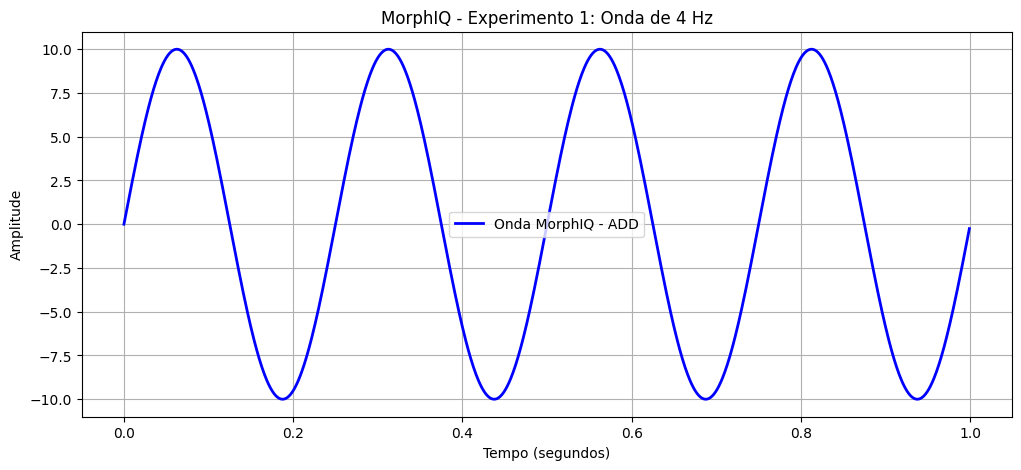

EXPERIMENTO 1 CONCLUIDO
Frequencia: 4 Hz
Amplitude: 10
Amostras geradas: 1000


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# MORPHIQ - EXPERIMENTO 1
# Geracao da primeira onda senoidal

frequencia = 4       # Hz
amplitude = 10       # Unidades de amplitude
duracao = 1          # Segundo
taxa_amostragem = 1000

# Eixo do tempo
tempo = np.arange(
    0, duracao, 1/taxa_amostragem
)

# Geracao da onda
onda = amplitude * np.sin(
    2 * np.pi * frequencia * tempo
)

# Desenho
plt.figure(figsize=(12, 5))
plt.plot(
    tempo, onda,
    color="blue",
    linewidth=2,
    label="Onda MorphIQ - ADD"
)

plt.title("MorphIQ - Experimento 1: Onda de 4 Hz")
plt.xlabel("Tempo (segundos)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

print("EXPERIMENTO 1 CONCLUIDO")
print("Frequencia:", frequencia, "Hz")
print("Amplitude:", amplitude)
print("Amostras geradas:", len(onda))

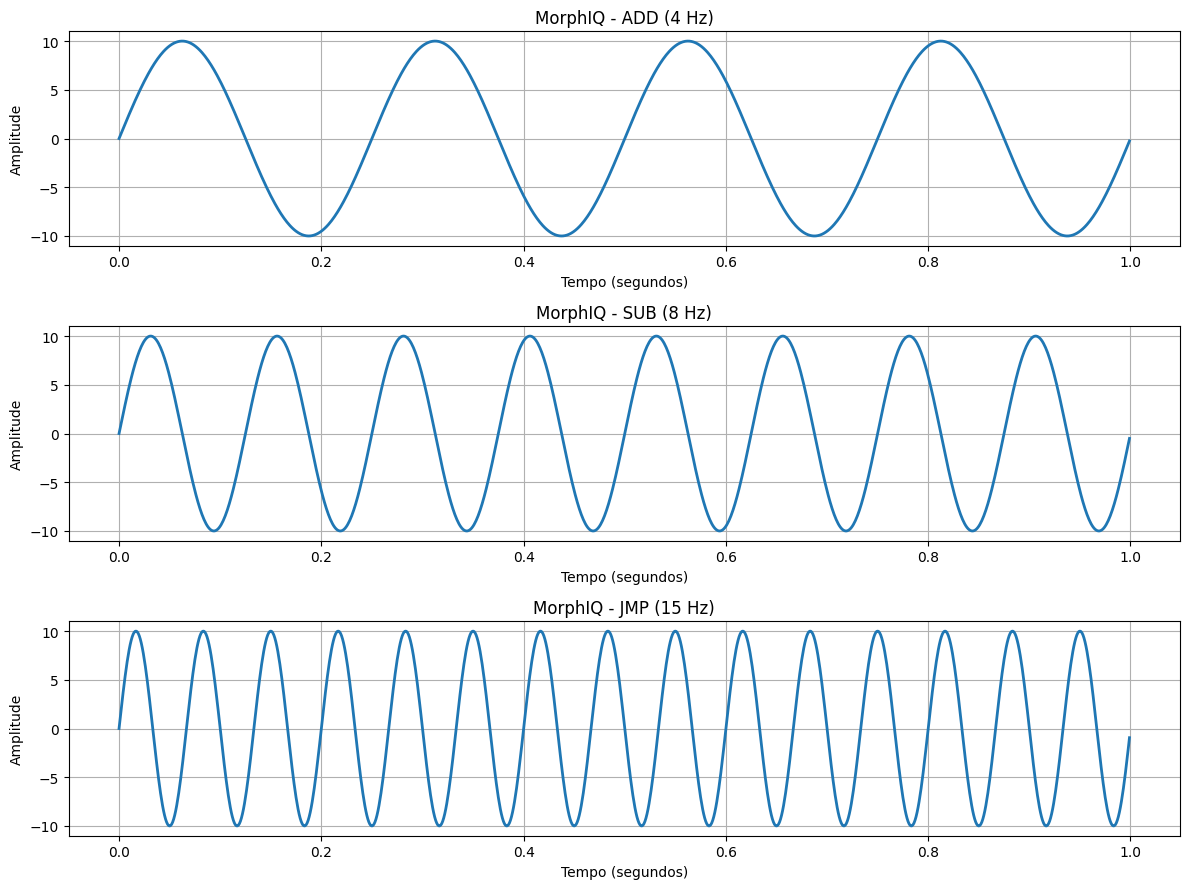

MORPHIQ - EXPERIMENTO 2
-----------------------
Comando ADD = 4 Hz
Comando SUB = 8 Hz
Comando JMP = 15 Hz
Tres ondas geradas com sucesso!


In [ ]:

# MORPHIQ - EXPERIMENTO 2
# Representacao de comandos por ondas

import numpy as np
import matplotlib.pyplot as plt

# Configuracoes
amplitude = 10
taxa_amostragem = 1000
duracao = 1

tempo = np.arange(
    0, duracao, 1/taxa_amostragem
)

# Frequencias associadas aos comandos
comandos = {
    "ADD": 4,
    "SUB": 8,
    "JMP": 15
}

# Criar graficos
fig, eixos = plt.subplots(
    3, 1, figsize=(12, 9)
)

for i, (comando, frequencia) in enumerate(
    comandos.items()
):
    onda = amplitude * np.sin(
        2 * np.pi * frequencia * tempo
    )

    eixos[i].plot(
        tempo,
        onda,
        linewidth=2
    )

    eixos[i].set_title(
        f"MorphIQ - {comando} ({frequencia} Hz)"
    )

    eixos[i].set_xlabel("Tempo (segundos)")
    eixos[i].set_ylabel("Amplitude")
    eixos[i].set_ylim(-11, 11)
    eixos[i].grid(True)

plt.tight_layout()
plt.show()

# Confirmacao
print("MORPHIQ - EXPERIMENTO 2")
print("-----------------------")

for comando, frequencia in comandos.items():
    print(
        f"Comando {comando} = {frequencia} Hz"
    )

print("Tres ondas geradas com sucesso!")

-----------------------------
Frequencia enviada: 4 Hz
Frequencia detectada: 4.0 Hz
Comando identificado: ADD
-----------------------------
Frequencia enviada: 8 Hz
Frequencia detectada: 8.0 Hz
Comando identificado: SUB
-----------------------------
Frequencia enviada: 15 Hz
Frequencia detectada: 15.0 Hz
Comando identificado: JMP


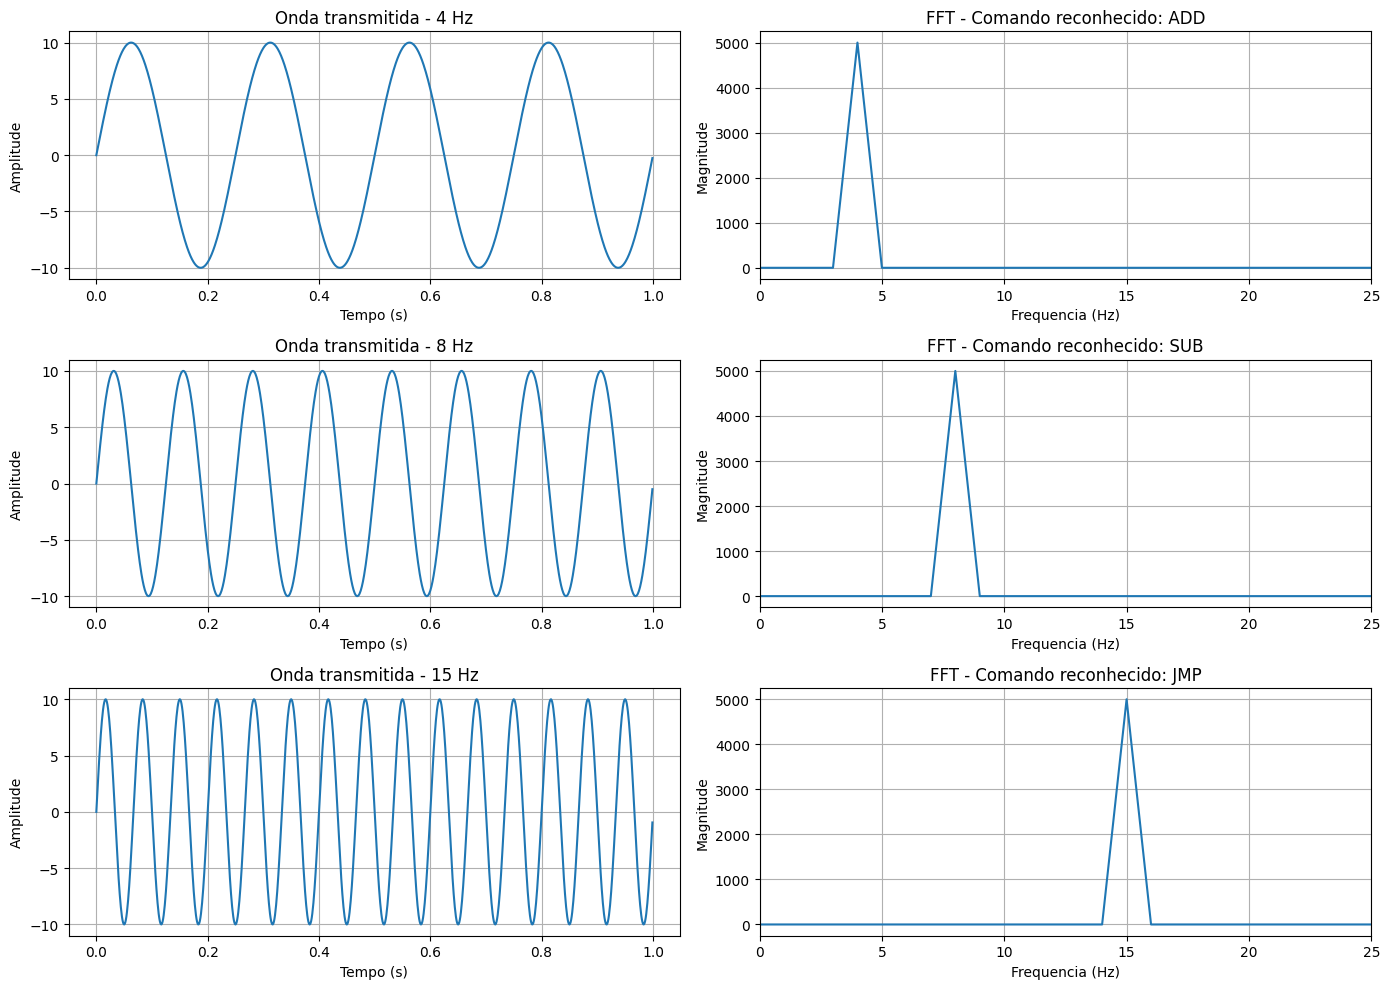


EXPERIMENTO 3 FINALIZADO


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 3
# RECONHECIMENTO AUTOMATICO DE COMANDOS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# Configuracoes
fs = 1000
duracao = 1
amplitude = 10

tempo = np.arange(0, duracao, 1/fs)

# Dicionario MorphIQ
comandos = {
    4: "ADD",
    8: "SUB",
    15: "JMP"
}

# Funcao geradora de ondas
def gerar_onda(frequencia):
    return amplitude * np.sin(
        2 * np.pi * frequencia * tempo
    )

# Funcao de reconhecimento
def reconhecer_comando(onda):

    espectro = np.abs(np.fft.rfft(onda))

    frequencias = np.fft.rfftfreq(
        len(onda),
        d=1/fs
    )

    indice = np.argmax(espectro[1:]) + 1
    frequencia_detectada = frequencias[indice]

    # Identificar comando mais proximo
    frequencia_referencia = min(
        comandos.keys(),
        key=lambda f: abs(f - frequencia_detectada)
    )

    # Tolerancia de reconhecimento
    if abs(frequencia_referencia - frequencia_detectada) <= 0.5:
        comando = comandos[frequencia_referencia]
    else:
        comando = "DESCONHECIDO"

    return frequencia_detectada, comando, frequencias, espectro


# Testar os tres comandos
fig, eixos = plt.subplots(
    3, 2,
    figsize=(14, 10)
)

for i, frequencia in enumerate([4, 8, 15]):

    onda = gerar_onda(frequencia)

    freq_detectada, comando, freqs, espectro = reconhecer_comando(onda)

    # Grafico da onda
    eixos[i, 0].plot(tempo, onda)
    eixos[i, 0].set_title(
        f"Onda transmitida - {frequencia} Hz"
    )
    eixos[i, 0].set_xlabel("Tempo (s)")
    eixos[i, 0].set_ylabel("Amplitude")
    eixos[i, 0].grid(True)

    # Grafico da FFT
    eixos[i, 1].plot(freqs, espectro)
    eixos[i, 1].set_xlim(0, 25)
    eixos[i, 1].set_title(
        f"FFT - Comando reconhecido: {comando}"
    )
    eixos[i, 1].set_xlabel("Frequencia (Hz)")
    eixos[i, 1].set_ylabel("Magnitude")
    eixos[i, 1].grid(True)

    print("-----------------------------")
    print("Frequencia enviada:", frequencia, "Hz")
    print("Frequencia detectada:", freq_detectada, "Hz")
    print("Comando identificado:", comando)

plt.tight_layout()
plt.show()

print("\nEXPERIMENTO 3 FINALIZADO")

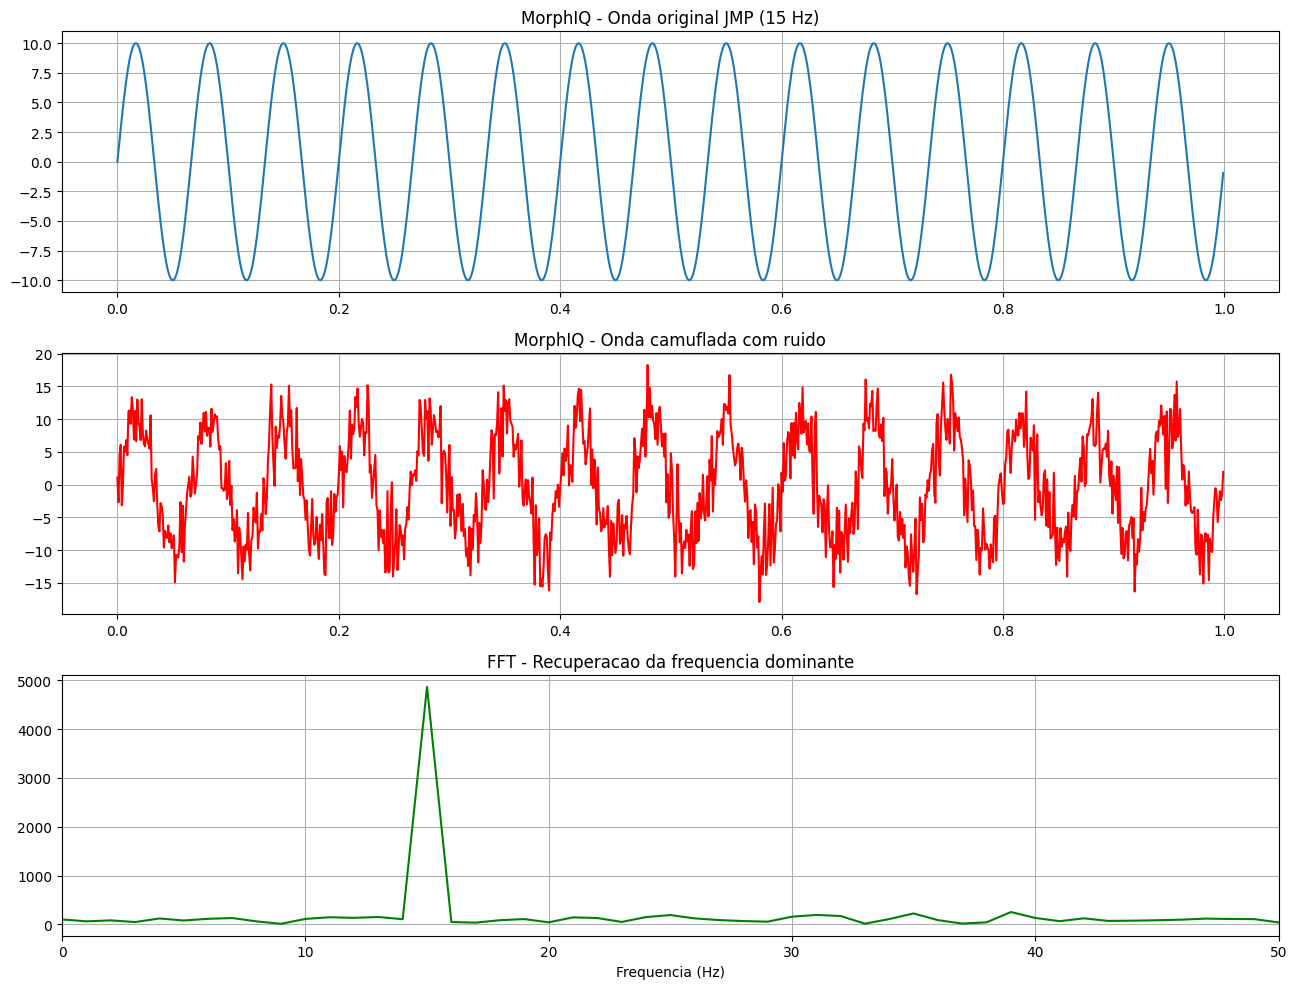

EXPERIMENTO 4 - RESULTADOS
--------------------------
Frequencia original: 15 Hz
Frequencia detectada: 15.0 Hz
Comando reconhecido: JMP
Intensidade do ruido: 3.5


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 4
# CAMUFLAGEM COM RUIDO GAUSSIANO
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# Configuracoes
fs = 1000
duracao = 1
frequencia = 15
amplitude = 10
intensidade_ruido = 3.5

tempo = np.arange(0, duracao, 1/fs)

# Onda original - comando JMP
onda_original = amplitude * np.sin(
    2 * np.pi * frequencia * tempo
)

# Gerar ruido aleatorio reproduzivel
rng = np.random.default_rng(42)

ruido = rng.normal(
    0,
    intensidade_ruido,
    len(tempo)
)

# Camuflar a onda
onda_camuflada = onda_original + ruido

# Analise FFT
espectro = np.abs(
    np.fft.rfft(onda_camuflada)
)

frequencias = np.fft.rfftfreq(
    len(onda_camuflada),
    d=1/fs
)

indice = np.argmax(espectro[1:]) + 1
frequencia_detectada = frequencias[indice]

# Reconhecimento
if abs(frequencia_detectada - 15) <= 0.5:
    comando = "JMP"
else:
    comando = "NAO RECONHECIDO"

# Graficos
fig, eixos = plt.subplots(
    3, 1,
    figsize=(13, 10)
)

eixos[0].plot(tempo, onda_original)
eixos[0].set_title(
    "MorphIQ - Onda original JMP (15 Hz)"
)
eixos[0].grid(True)

eixos[1].plot(
    tempo,
    onda_camuflada,
    color="red"
)
eixos[1].set_title(
    "MorphIQ - Onda camuflada com ruido"
)
eixos[1].grid(True)

eixos[2].plot(
    frequencias,
    espectro,
    color="green"
)
eixos[2].set_xlim(0, 50)
eixos[2].set_title(
    "FFT - Recuperacao da frequencia dominante"
)
eixos[2].set_xlabel("Frequencia (Hz)")
eixos[2].grid(True)

plt.tight_layout()
plt.show()

print("EXPERIMENTO 4 - RESULTADOS")
print("--------------------------")
print("Frequencia original:", frequencia, "Hz")
print("Frequencia detectada:", frequencia_detectada, "Hz")
print("Comando reconhecido:", comando)
print("Intensidade do ruido:", intensidade_ruido)

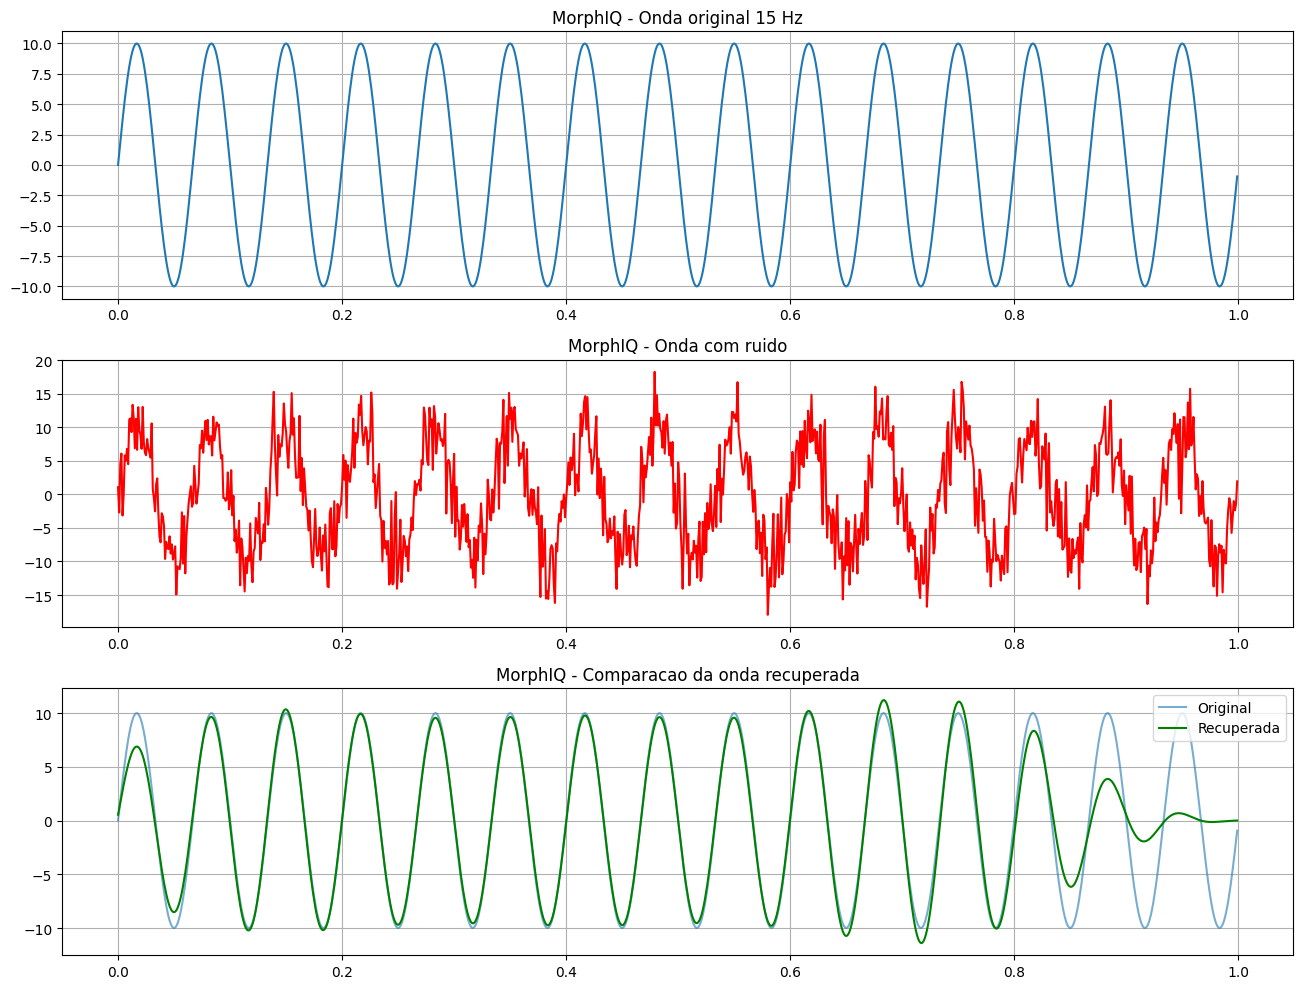

MORPHIQ - EXPERIMENTO 5
-----------------------
Frequencia original: 15 Hz
Frequencia recuperada: 15.0 Hz
Erro RMS: 2.3499
RESULTADO: FREQUENCIA RECUPERADA


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 5
# RECUPERACAO DE ONDA COM FILTRO DIGITAL
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

# Configuracoes
fs = 1000
duracao = 1
frequencia_original = 15
amplitude = 10

tempo = np.arange(0, duracao, 1/fs)

# Onda original
onda_original = amplitude * np.sin(
    2 * np.pi * frequencia_original * tempo
)

# Ruido gaussiano
rng = np.random.default_rng(42)
ruido = rng.normal(0, 3.5, len(tempo))

# Onda com ruido
onda_camuflada = onda_original + ruido

# Filtro passa-faixa: 12 a 18 Hz
sos = butter(
    4,
    [12, 18],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# Recuperacao
onda_recuperada = sosfiltfilt(
    sos, onda_camuflada
)

# Frequencia recuperada via FFT
espectro = np.abs(
    np.fft.rfft(onda_recuperada)
)

frequencias = np.fft.rfftfreq(
    len(onda_recuperada),
    d=1/fs
)

indice = np.argmax(espectro[1:]) + 1
freq_detectada = frequencias[indice]

# Erro quadratico medio
erro = np.sqrt(np.mean(
    (onda_original - onda_recuperada)**2
))

# Graficos
fig, eixos = plt.subplots(3, 1, figsize=(13, 10))

eixos[0].plot(tempo, onda_original)
eixos[0].set_title("MorphIQ - Onda original 15 Hz")
eixos[0].grid(True)

eixos[1].plot(tempo, onda_camuflada, color="red")
eixos[1].set_title("MorphIQ - Onda com ruido")
eixos[1].grid(True)

eixos[2].plot(
    tempo, onda_original,
    label="Original",
    alpha=0.6
)
eixos[2].plot(
    tempo, onda_recuperada,
    label="Recuperada",
    color="green"
)
eixos[2].set_title(
    "MorphIQ - Comparacao da onda recuperada"
)
eixos[2].legend()
eixos[2].grid(True)

plt.tight_layout()
plt.show()

print("MORPHIQ - EXPERIMENTO 5")
print("-----------------------")
print("Frequencia original:", frequencia_original, "Hz")
print("Frequencia recuperada:", freq_detectada, "Hz")
print("Erro RMS:", round(erro, 4))

if abs(freq_detectada - frequencia_original) <= 1:
    print("RESULTADO: FREQUENCIA RECUPERADA")
else:
    print("RESULTADO: RECUPERACAO INSUFICIENTE")

Enviado: ADD | Detectado: ADD | Correto: True
Enviado: SUB | Detectado: SUB | Correto: True
Enviado: JMP | Detectado: JMP | Correto: True


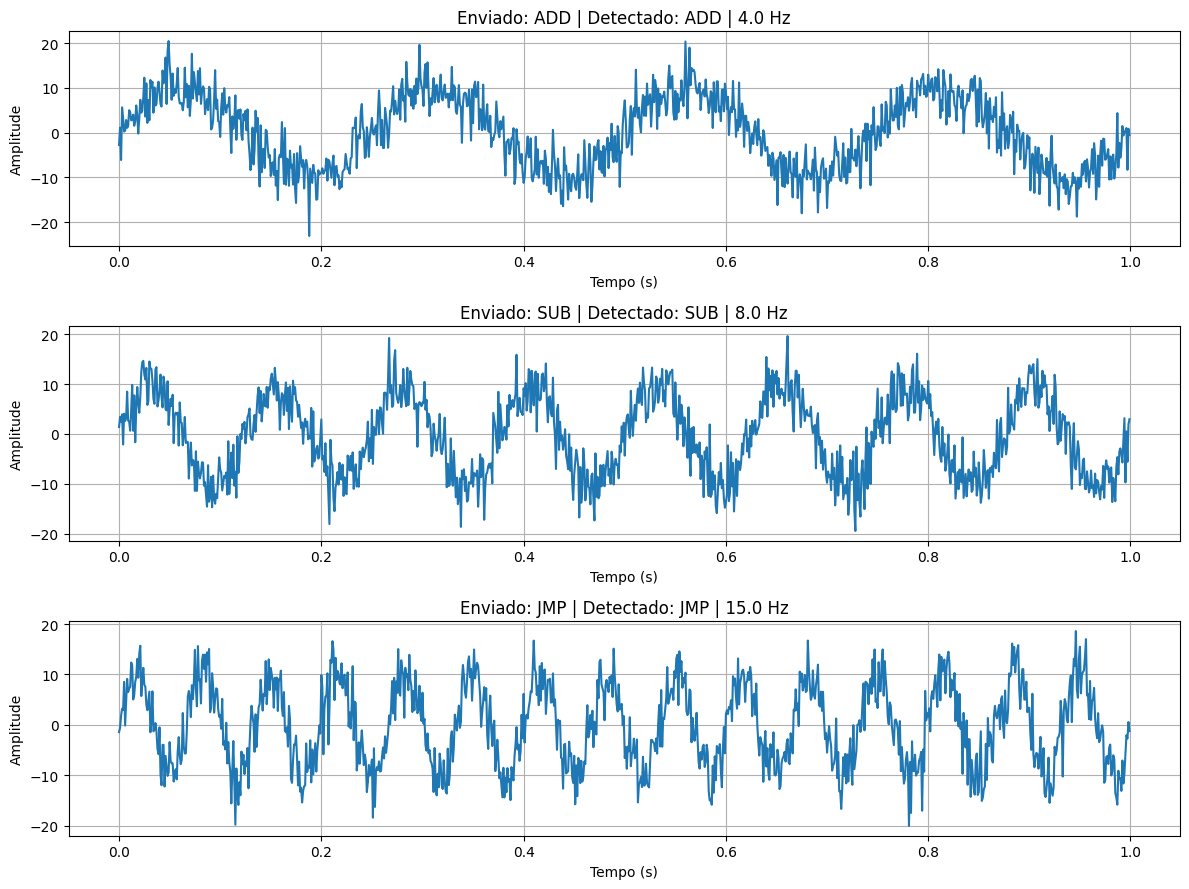


MORPHIQ - EXPERIMENTO 6
Acuracia: 100.0 %
Testes realizados: 3
RESULTADO: 3 COMANDOS RECONHECIDOS


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 6
# DECODIFICACAO AUTOMATICA COM RUIDO
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

fs = 1000
duracao = 1
amplitude = 10
intensidade_ruido = 3.5

tempo = np.arange(0, duracao, 1/fs)

dicionario = {
    "ADD": 4,
    "SUB": 8,
    "JMP": 15
}

rng = np.random.default_rng(2026)

def decodificar(onda):
    frequencias = np.fft.rfftfreq(len(onda), 1/fs)
    espectro = np.abs(np.fft.rfft(onda))

    indice = np.argmax(espectro[1:]) + 1
    frequencia_detectada = frequencias[indice]

    comando = "DESCONHECIDO"

    for nome, freq in dicionario.items():
        if abs(frequencia_detectada - freq) <= 0.5:
            comando = nome
            break

    return comando, frequencia_detectada

resultados = []

fig, eixos = plt.subplots(3, 1, figsize=(12, 9))

for i, (comando, frequencia) in enumerate(
    dicionario.items()
):
    onda = amplitude * np.sin(
        2 * np.pi * frequencia * tempo
    )

    ruido = rng.normal(
        0, intensidade_ruido, len(tempo)
    )

    onda_recebida = onda + ruido

    comando_detectado, freq_detectada = decodificar(
        onda_recebida
    )

    correto = comando_detectado == comando
    resultados.append(correto)

    eixos[i].plot(tempo, onda_recebida)
    eixos[i].set_title(
        f"Enviado: {comando} | "
        f"Detectado: {comando_detectado} | "
        f"{freq_detectada:.1f} Hz"
    )
    eixos[i].set_xlabel("Tempo (s)")
    eixos[i].set_ylabel("Amplitude")
    eixos[i].grid(True)

    print(
        f"Enviado: {comando} | "
        f"Detectado: {comando_detectado} | "
        f"Correto: {correto}"
    )

plt.tight_layout()
plt.show()

acuracia = 100 * sum(resultados) / len(resultados)

print("\nMORPHIQ - EXPERIMENTO 6")
print("Acuracia:", round(acuracia, 2), "%")
print("Testes realizados:", len(resultados))

if all(resultados):
    print("RESULTADO: 3 COMANDOS RECONHECIDOS")
else:
    print("RESULTADO: HOUVE FALHAS DE RECONHECIMENTO")

Bloco 1: 4.0 Hz -> ADD
Bloco 2: 8.0 Hz -> SUB
Bloco 3: 15.0 Hz -> JMP
Bloco 4: 4.0 Hz -> ADD


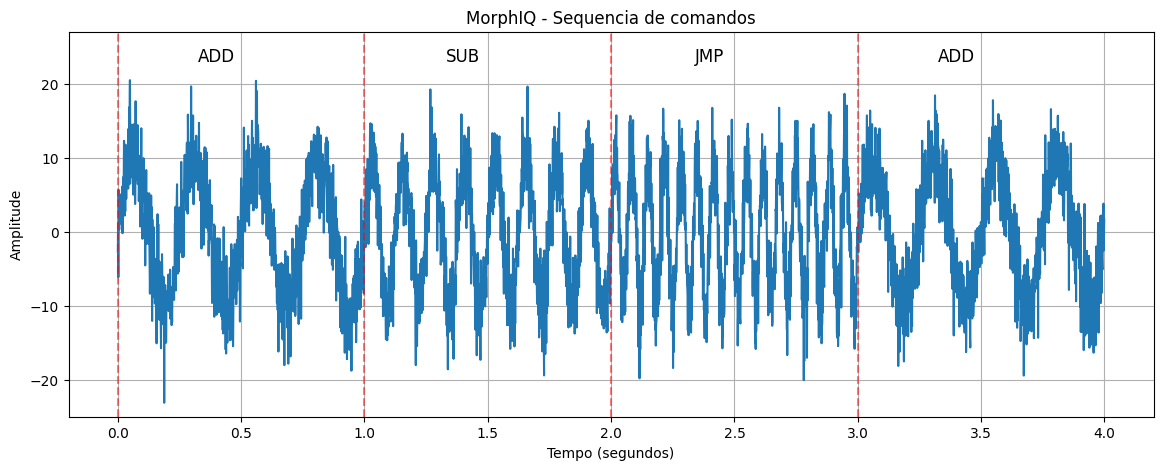


SEQUENCIA ORIGINAL:
ADD -> SUB -> JMP -> ADD

SEQUENCIA RECUPERADA:
ADD -> SUB -> JMP -> ADD

Acuracia: 100.0 %
RESULTADO: SEQUENCIA RECUPERADA COM SUCESSO


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 7
# TRANSMISSAO DE SEQUENCIA DE COMANDOS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

fs = 1000
duracao_comando = 1
amplitude = 10
ruido_intensidade = 3.5

dicionario = {
    "ADD": 4,
    "SUB": 8,
    "JMP": 15
}

sequencia_original = [
    "ADD", "SUB", "JMP", "ADD"
]

rng = np.random.default_rng(2026)

amostras = int(fs * duracao_comando)
tempo_bloco = np.arange(amostras) / fs

# Codificar cada comando
blocos = []

for comando in sequencia_original:
    frequencia = dicionario[comando]

    onda = amplitude * np.sin(
        2 * np.pi * frequencia * tempo_bloco
    )

    ruido = rng.normal(
        0, ruido_intensidade, amostras
    )

    blocos.append(onda + ruido)

# Unir sinais
sinal_completo = np.concatenate(blocos)

# Decodificar cada bloco
sequencia_recuperada = []

for i in range(len(sequencia_original)):

    inicio = i * amostras
    fim = inicio + amostras

    bloco = sinal_completo[inicio:fim]

    espectro = np.abs(np.fft.rfft(bloco))
    frequencias = np.fft.rfftfreq(
        len(bloco), d=1/fs
    )

    indice = np.argmax(espectro[1:]) + 1
    freq_detectada = frequencias[indice]

    comando_detectado = "DESCONHECIDO"

    for comando, frequencia in dicionario.items():
        if abs(freq_detectada - frequencia) <= 0.5:
            comando_detectado = comando
            break

    sequencia_recuperada.append(comando_detectado)

    print(
        f"Bloco {i+1}: "
        f"{freq_detectada:.1f} Hz -> "
        f"{comando_detectado}"
    )

# Grafico
tempo_total = np.arange(
    len(sinal_completo)
) / fs

plt.figure(figsize=(14, 5))

plt.plot(tempo_total, sinal_completo)

for i, comando in enumerate(sequencia_original):
    plt.axvline(
        i * duracao_comando,
        color="red",
        linestyle="--",
        alpha=0.5
    )

    plt.text(
        i * duracao_comando + 0.4,
        23,
        comando,
        ha="center",
        fontsize=12
    )

plt.ylim(-25, 27)
plt.title("MorphIQ - Sequencia de comandos")
plt.xlabel("Tempo (segundos)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

print("\nSEQUENCIA ORIGINAL:")
print(" -> ".join(sequencia_original))

print("\nSEQUENCIA RECUPERADA:")
print(" -> ".join(sequencia_recuperada))

acertos = sum(
    a == b for a, b in zip(
        sequencia_original,
        sequencia_recuperada
    )
)

print("\nAcuracia:", 100 * acertos / len(sequencia_original), "%")

if sequencia_original == sequencia_recuperada:
    print("RESULTADO: SEQUENCIA RECUPERADA COM SUCESSO")
else:
    print("RESULTADO: HOUVE ERROS NA DECODIFICACAO")


MORPHIQ - EXPERIMENTO 8
-----------------------
PC=0 | OP=ADD | ACUMULADOR=10
PC=1 | OP=SUB | ACUMULADOR=7
PC=2 | OP=JMP | ACUMULADOR=7
PC=4 | OP=ADD | ACUMULADOR=12

Resultado final: 12
RESULTADO: EXECUCAO SIMULADA CORRETA


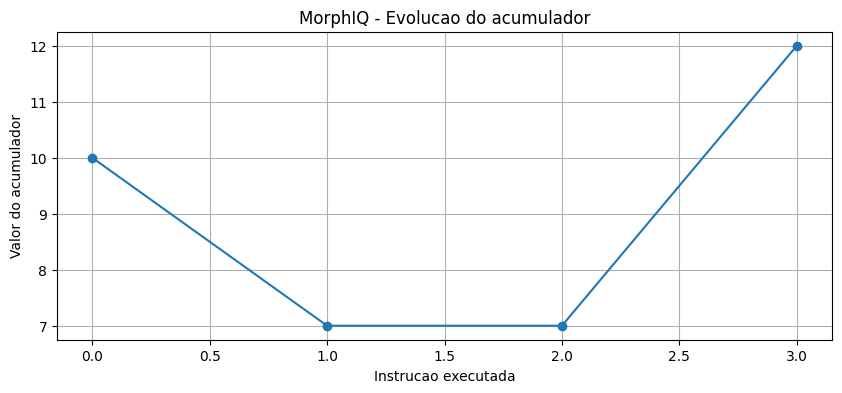

In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 8
# MORPHIQ-IR E EXECUCAO SIMULADA
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

fs = 1000
duracao = 1
amplitude = 10

frequencias = {
    "ADD": 4,
    "SUB": 8,
    "JMP": 15
}

# Programa em representacao intermediaria
morphiq_ir = [
    {"op": "ADD", "valor": 10},
    {"op": "SUB", "valor": 3},
    {"op": "JMP", "destino": 4},
    {"op": "ADD", "valor": 100},
    {"op": "ADD", "valor": 5}
]

# Gerar sinais para as instrucoes
tempo = np.arange(0, duracao, 1/fs)
rng = np.random.default_rng(2026)

sinais = []

for instrucao in morphiq_ir:
    freq = frequencias[instrucao["op"]]

    onda = amplitude * np.sin(
        2 * np.pi * freq * tempo
    )

    ruido = rng.normal(0, 3.5, len(tempo))
    sinais.append(onda + ruido)

# Decodificar ondas
operacoes_decodificadas = []

for sinal in sinais:
    espectro = np.abs(np.fft.rfft(sinal))
    eixo_freq = np.fft.rfftfreq(
        len(sinal), d=1/fs
    )

    indice = np.argmax(espectro[1:]) + 1
    freq_detectada = eixo_freq[indice]

    candidatos = [
        op for op, freq in frequencias.items()
        if abs(freq_detectada - freq) <= 0.5
    ]

    operacoes_decodificadas.append(
        candidatos[0] if candidatos else "INVALIDO"
    )

# Executar programa interpretado
acumulador = 0
pc = 0
passos = 0
historico = []

while pc < len(morphiq_ir) and passos < 20:

    instrucao = morphiq_ir[pc]
    op = operacoes_decodificadas[pc]

    # Verificar se a onda foi reconhecida
    if op == "INVALIDO":
        raise ValueError(
            f"Comando desconhecido na posicao {pc}"
        )

    # Verificar integridade da operacao
    if op != instrucao["op"]:
        raise ValueError(
            f"Operacao incorreta na posicao {pc}"
        )

    if op == "ADD":
        acumulador += instrucao["valor"]
        proximo_pc = pc + 1

    elif op == "SUB":
        acumulador -= instrucao["valor"]
        proximo_pc = pc + 1

    elif op == "JMP":
        proximo_pc = instrucao["destino"]

    else:
        raise ValueError("Operacao nao suportada")

    historico.append((pc, op, acumulador))
    pc = proximo_pc
    passos += 1

print("MORPHIQ - EXPERIMENTO 8")
print("-----------------------")

for posicao, op, valor in historico:
    print(
        f"PC={posicao} | "
        f"OP={op} | "
        f"ACUMULADOR={valor}"
    )

print("\nResultado final:", acumulador)

if acumulador == 12:
    print("RESULTADO: EXECUCAO SIMULADA CORRETA")
else:
    print("RESULTADO: VERIFICAR EXECUCAO")

# Grafico da evolucao do acumulador
plt.figure(figsize=(10, 4))
plt.plot(
    range(len(historico)),
    [item[2] for item in historico],
    marker="o"
)
plt.title("MorphIQ - Evolucao do acumulador")
plt.xlabel("Instrucao executada")
plt.ylabel("Valor do acumulador")
plt.grid(True)
plt.show()


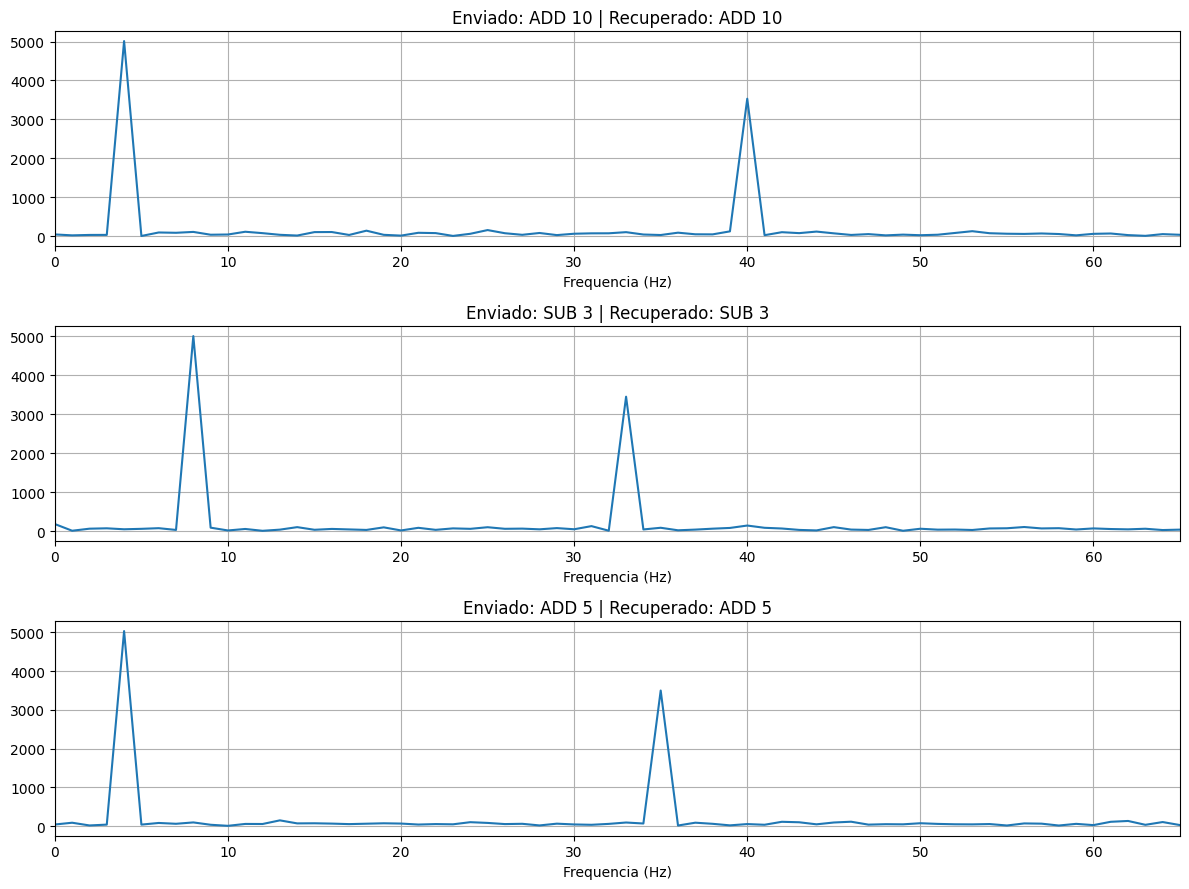

MORPHIQ - EXPERIMENTO 9
-----------------------
Programa original: [('ADD', 10), ('SUB', 3), ('ADD', 5)]
Programa recuperado: [('ADD', 10), ('SUB', 3), ('ADD', 5)]
RESULTADO: OPERACOES E VALORES RECUPERADOS


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 9
# CODIFICACAO DE OPERACOES E VALORES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

fs = 1000
duracao = 1
tempo = np.arange(0, duracao, 1/fs)

operacoes = {
    "ADD": 4,
    "SUB": 8,
    "JMP": 15
}

programa = [
    ("ADD", 10),
    ("SUB", 3),
    ("ADD", 5)
]

rng = np.random.default_rng(2026)

def codificar(op, valor):
    freq_op = operacoes[op]
    freq_valor = 30 + valor

    onda_op = 10 * np.sin(
        2 * np.pi * freq_op * tempo
    )

    onda_valor = 7 * np.sin(
        2 * np.pi * freq_valor * tempo
    )

    ruido = rng.normal(0, 2, len(tempo))

    return onda_op + onda_valor + ruido

def decodificar(sinal):
    espectro = np.abs(np.fft.rfft(sinal))
    freqs = np.fft.rfftfreq(len(sinal), 1/fs)

    # Canal de operacao: 1 a 20 Hz
    faixa_op = (freqs >= 1) & (freqs <= 20)
    indice_op = np.where(faixa_op)[0][
        np.argmax(espectro[faixa_op])
    ]

    freq_op = freqs[indice_op]

    op = "DESCONHECIDO"

    for nome, freq in operacoes.items():
        if abs(freq_op - freq) <= 0.5:
            op = nome
            break

    # Canal numerico: 30 a 100 Hz
    faixa_valor = (freqs >= 30) & (freqs <= 100)
    indice_valor = np.where(faixa_valor)[0][
        np.argmax(espectro[faixa_valor])
    ]

    freq_valor = freqs[indice_valor]
    valor = int(round(freq_valor - 30))

    return op, valor, espectro, freqs

programa_recuperado = []

fig, eixos = plt.subplots(
    len(programa), 1, figsize=(12, 9)
)

for i, (op, valor) in enumerate(programa):
    sinal = codificar(op, valor)

    op_rec, valor_rec, espectro, freqs = decodificar(
        sinal
    )

    programa_recuperado.append(
        (op_rec, valor_rec)
    )

    eixos[i].plot(freqs, espectro)
    eixos[i].set_xlim(0, 65)
    eixos[i].set_title(
        f"Enviado: {op} {valor} | "
        f"Recuperado: {op_rec} {valor_rec}"
    )
    eixos[i].set_xlabel("Frequencia (Hz)")
    eixos[i].grid(True)

plt.tight_layout()
plt.show()

print("MORPHIQ - EXPERIMENTO 9")
print("-----------------------")
print("Programa original:", programa)
print("Programa recuperado:", programa_recuperado)

if programa == programa_recuperado:
    print("RESULTADO: OPERACOES E VALORES RECUPERADOS")
else:
    print("RESULTADO: HOUVE ERROS NA RECUPERACAO")


Executado: ADD 10 | Acumulador: 10
Executado: SUB 3 | Acumulador: 7
Executado: ADD 5 | Acumulador: 12
Executado: SUB 2 | Acumulador: 10

MORPHIQ - EXPERIMENTO 10
--------------------------
Programa original: [('ADD', 10), ('SUB', 3), ('ADD', 5), ('SUB', 2)]
Programa decodificado: [('ADD', 10), ('SUB', 3), ('ADD', 5), ('SUB', 2)]
Resultado final: 10
RESULTADO: EXECUCAO CORRETA


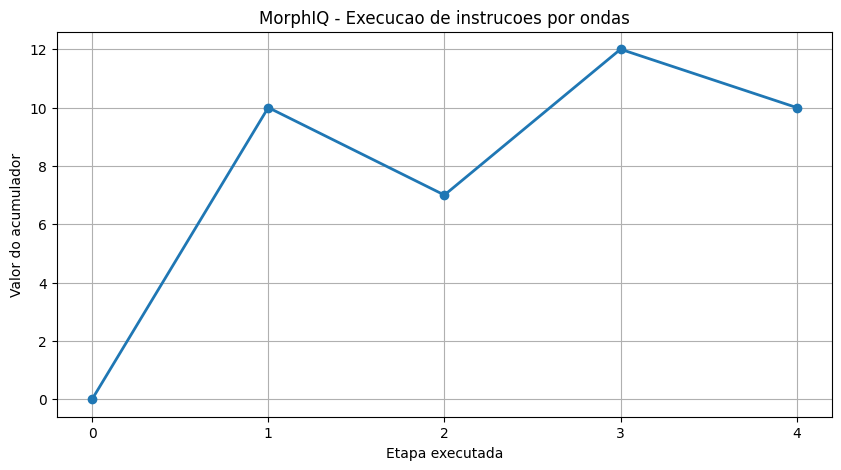

In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 10
# EXECUCAO A PARTIR DE ONDAS DECODIFICADAS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

fs = 1000
duracao = 1
amplitude_op = 10
amplitude_valor = 7

tempo = np.arange(0, duracao, 1/fs)
rng = np.random.default_rng(2026)

frequencias_op = {
    "ADD": 4,
    "SUB": 8,
    "JMP": 15
}

# Programa original
programa = [
    ("ADD", 10),
    ("SUB", 3),
    ("ADD", 5),
    ("SUB", 2)
]

# ETAPA 1 - CODIFICAR
sinais = []

for op, valor in programa:

    freq_op = frequencias_op[op]
    freq_valor = 30 + valor

    onda_op = amplitude_op * np.sin(
        2 * np.pi * freq_op * tempo
    )

    onda_valor = amplitude_valor * np.sin(
        2 * np.pi * freq_valor * tempo
    )

    ruido = rng.normal(0, 2, len(tempo))

    sinais.append(onda_op + onda_valor + ruido)

# ETAPA 2 - DECODIFICAR
programa_decodificado = []

for sinal in sinais:

    espectro = np.abs(np.fft.rfft(sinal))
    freqs = np.fft.rfftfreq(len(sinal), 1/fs)

    # Canal da operacao
    mascara_op = (freqs >= 1) & (freqs <= 20)
    indices_op = np.where(mascara_op)[0]

    indice_op = indices_op[
        np.argmax(espectro[mascara_op])
    ]

    freq_op = freqs[indice_op]

    op_detectada = min(
        frequencias_op,
        key=lambda nome: abs(
            frequencias_op[nome] - freq_op
        )
    )

    if abs(frequencias_op[op_detectada] - freq_op) > 0.5:
        raise ValueError("Operacao nao reconhecida")

    # Canal do valor
    mascara_valor = (freqs >= 30) & (freqs <= 100)
    indices_valor = np.where(mascara_valor)[0]

    indice_valor = indices_valor[
        np.argmax(espectro[mascara_valor])
    ]

    valor_detectado = int(
        round(freqs[indice_valor] - 30)
    )

    programa_decodificado.append(
        (op_detectada, valor_detectado)
    )

# ETAPA 3 - EXECUTAR
acumulador = 0
historico = [acumulador]

for op, valor in programa_decodificado:

    if op == "ADD":
        acumulador += valor

    elif op == "SUB":
        acumulador -= valor

    else:
        raise ValueError(
            "Operacao nao suportada neste teste"
        )

    historico.append(acumulador)

    print(
        f"Executado: {op} {valor} | "
        f"Acumulador: {acumulador}"
    )

# RESULTADOS
print("\nMORPHIQ - EXPERIMENTO 10")
print("--------------------------")
print("Programa original:", programa)
print("Programa decodificado:", programa_decodificado)
print("Resultado final:", acumulador)

if programa == programa_decodificado and acumulador == 10:
    print("RESULTADO: EXECUCAO CORRETA")
else:
    print("RESULTADO: VERIFICAR DECODIFICACAO")

# GRAFICO
plt.figure(figsize=(10, 5))
plt.plot(
    range(len(historico)),
    historico,
    marker="o",
    linewidth=2
)

plt.title("MorphIQ - Execucao de instrucoes por ondas")
plt.xlabel("Etapa executada")
plt.ylabel("Valor do acumulador")
plt.xticks(range(len(historico)))
plt.grid(True)
plt.show()


Ruido:  0 | Acertos: 100/100 | Taxa: 100.0%
Ruido:  2 | Acertos: 100/100 | Taxa: 100.0%
Ruido:  5 | Acertos: 100/100 | Taxa: 100.0%
Ruido: 10 | Acertos: 100/100 | Taxa: 100.0%
Ruido: 15 | Acertos: 100/100 | Taxa: 100.0%
Ruido: 20 | Acertos: 100/100 | Taxa: 100.0%
Ruido: 30 | Acertos: 98/100 | Taxa: 98.0%
Ruido: 40 | Acertos: 83/100 | Taxa: 83.0%
Ruido: 60 | Acertos: 38/100 | Taxa: 38.0%


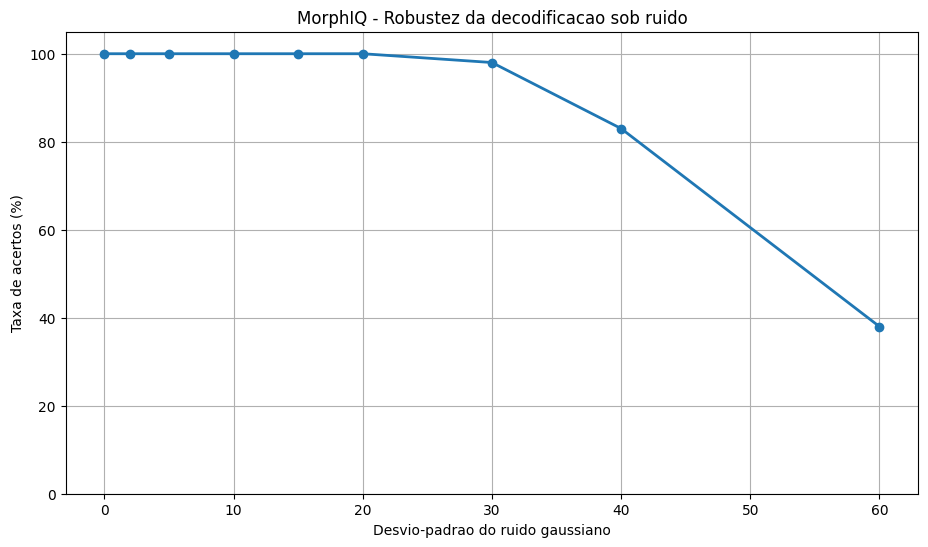


EXPERIMENTO 11 CONCLUIDO
Total de testes: 900


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 11
# RESISTENCIA A RUIDO E TAXA DE ACERTOS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

fs = 1000
duracao = 1
tempo = np.arange(0, duracao, 1/fs)

operacoes = {
    "ADD": 4,
    "SUB": 8,
    "JMP": 15
}

# Intensidades de ruido a testar
niveis_ruido = [0, 2, 5, 10, 15, 20, 30, 40, 60]

testes_por_nivel = 100
rng = np.random.default_rng(2026)

resultados = []

for nivel in niveis_ruido:

    acertos = 0

    for teste in range(testes_por_nivel):

        # Escolher comando e valor aleatorios
        op = rng.choice(list(operacoes.keys()))
        valor = int(rng.integers(1, 21))

        freq_op = operacoes[op]
        freq_valor = 30 + valor

        # Codificar
        onda_op = 10 * np.sin(
            2 * np.pi * freq_op * tempo
        )

        onda_valor = 7 * np.sin(
            2 * np.pi * freq_valor * tempo
        )

        ruido = rng.normal(
            0, nivel, len(tempo)
        )

        sinal = onda_op + onda_valor + ruido

        # Decodificar via FFT
        espectro = np.abs(np.fft.rfft(sinal))
        freqs = np.fft.rfftfreq(len(sinal), 1/fs)

        # Recuperar operacao
        mascara_op = (freqs >= 1) & (freqs <= 20)
        indices_op = np.where(mascara_op)[0]

        indice_op = indices_op[
            np.argmax(espectro[mascara_op])
        ]

        freq_detectada = freqs[indice_op]

        op_rec = min(
            operacoes,
            key=lambda nome: abs(
                operacoes[nome] - freq_detectada
            )
        )

        # Recuperar valor
        mascara_valor = (freqs >= 30) & (freqs <= 100)
        indices_valor = np.where(mascara_valor)[0]

        indice_valor = indices_valor[
            np.argmax(espectro[mascara_valor])
        ]

        valor_rec = int(
            round(freqs[indice_valor] - 30)
        )

        # Acerto somente se ambos corretos
        if op_rec == op and valor_rec == valor:
            acertos += 1

    taxa = 100 * acertos / testes_por_nivel
    resultados.append(taxa)

    print(
        f"Ruido: {nivel:>2} | "
        f"Acertos: {acertos}/{testes_por_nivel} | "
        f"Taxa: {taxa:.1f}%"
    )

# Grafico de robustez
plt.figure(figsize=(11, 6))

plt.plot(
    niveis_ruido,
    resultados,
    marker="o",
    linewidth=2
)

plt.title(
    "MorphIQ - Robustez da decodificacao sob ruido"
)
plt.xlabel("Desvio-padrao do ruido gaussiano")
plt.ylabel("Taxa de acertos (%)")
plt.ylim(0, 105)
plt.grid(True)
plt.show()

print("\nEXPERIMENTO 11 CONCLUIDO")
print("Total de testes:",
      len(niveis_ruido) * testes_por_nivel)


Bloco 1: Portadora=35 Hz | Detectada=50.0 Hz | Comando=JMP
Bloco 2: Portadora=50 Hz | Detectada=64.0 Hz | Comando=JMP
Bloco 3: Portadora=42 Hz | Detectada=56.0 Hz | Comando=JMP
Bloco 4: Portadora=65 Hz | Detectada=80.0 Hz | Comando=JMP
Bloco 5: Portadora=38 Hz | Detectada=52.0 Hz | Comando=JMP
Bloco 6: Portadora=55 Hz | Detectada=70.0 Hz | Comando=JMP


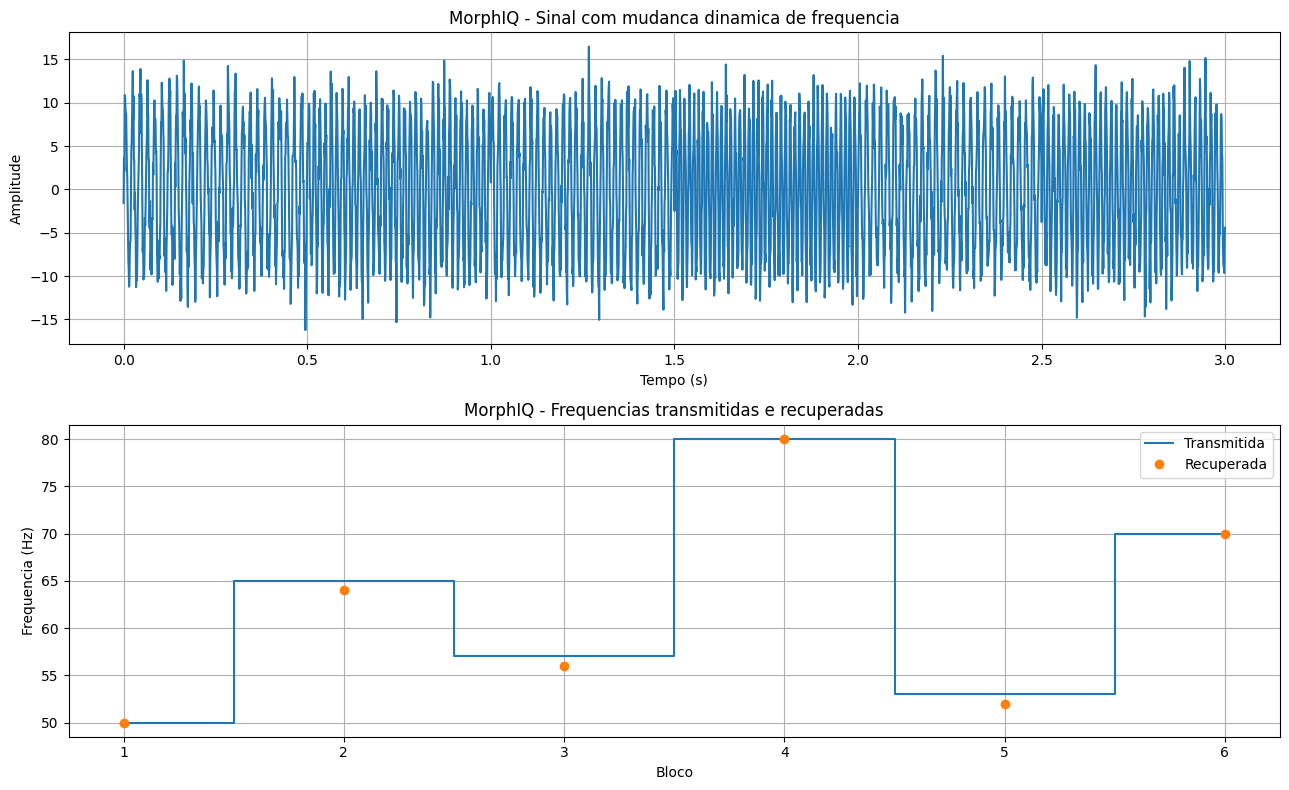


EXPERIMENTO 12
Comandos recuperados: ['JMP', 'JMP', 'JMP', 'JMP', 'JMP', 'JMP']
RESULTADO: SALTOS RECUPERADOS COM SUCESSO


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 12
# CAMUFLAGEM DINAMICA - FREQUENCY HOPPING
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

fs = 1000
duracao_bloco = 0.5
amplitude = 10

# Frequencias portadoras variaveis
saltos = [35, 50, 42, 65, 38, 55]

# Comando representado por deslocamento
frequencia_comando = 15  # JMP

rng = np.random.default_rng(2026)

amostras = int(fs * duracao_bloco)
tempo_bloco = np.arange(amostras) / fs

blocos = []
frequencias_transmitidas = []

for portadora in saltos:

    frequencia_total = portadora + frequencia_comando
    frequencias_transmitidas.append(frequencia_total)

    onda = amplitude * np.sin(
        2 * np.pi * frequencia_total * tempo_bloco
    )

    ruido = rng.normal(0, 2, amostras)

    blocos.append(onda + ruido)

sinal = np.concatenate(blocos)

# Decodificar usando a sequencia de saltos
frequencias_recuperadas = []
comandos_recuperados = []

for i, portadora in enumerate(saltos):

    bloco = blocos[i]

    espectro = np.abs(np.fft.rfft(bloco))
    freqs = np.fft.rfftfreq(len(bloco), 1/fs)

    indice = np.argmax(espectro[1:]) + 1
    frequencia_detectada = freqs[indice]

    frequencias_recuperadas.append(
        frequencia_detectada
    )

    deslocamento = frequencia_detectada - portadora

    if abs(deslocamento - 15) <= 1:
        comando = "JMP"
    else:
        comando = "DESCONHECIDO"

    comandos_recuperados.append(comando)

    print(
        f"Bloco {i+1}: "
        f"Portadora={portadora} Hz | "
        f"Detectada={frequencia_detectada:.1f} Hz | "
        f"Comando={comando}"
    )

# Graficos
tempo_total = np.arange(len(sinal)) / fs

fig, eixos = plt.subplots(2, 1, figsize=(13, 8))

eixos[0].plot(tempo_total, sinal)
eixos[0].set_title(
    "MorphIQ - Sinal com mudanca dinamica de frequencia"
)
eixos[0].set_xlabel("Tempo (s)")
eixos[0].set_ylabel("Amplitude")
eixos[0].grid(True)

eixos[1].step(
    range(1, len(frequencias_transmitidas)+1),
    frequencias_transmitidas,
    where="mid",
    label="Transmitida"
)

eixos[1].plot(
    range(1, len(frequencias_recuperadas)+1),
    frequencias_recuperadas,
    "o",
    label="Recuperada"
)

eixos[1].set_title(
    "MorphIQ - Frequencias transmitidas e recuperadas"
)
eixos[1].set_xlabel("Bloco")
eixos[1].set_ylabel("Frequencia (Hz)")
eixos[1].legend()
eixos[1].grid(True)

plt.tight_layout()
plt.show()

print("\nEXPERIMENTO 12")
print("Comandos recuperados:", comandos_recuperados)

if all(c == "JMP" for c in comandos_recuperados):
    print("RESULTADO: SALTOS RECUPERADOS COM SUCESSO")
else:
    print("RESULTADO: HOUVE ERROS")


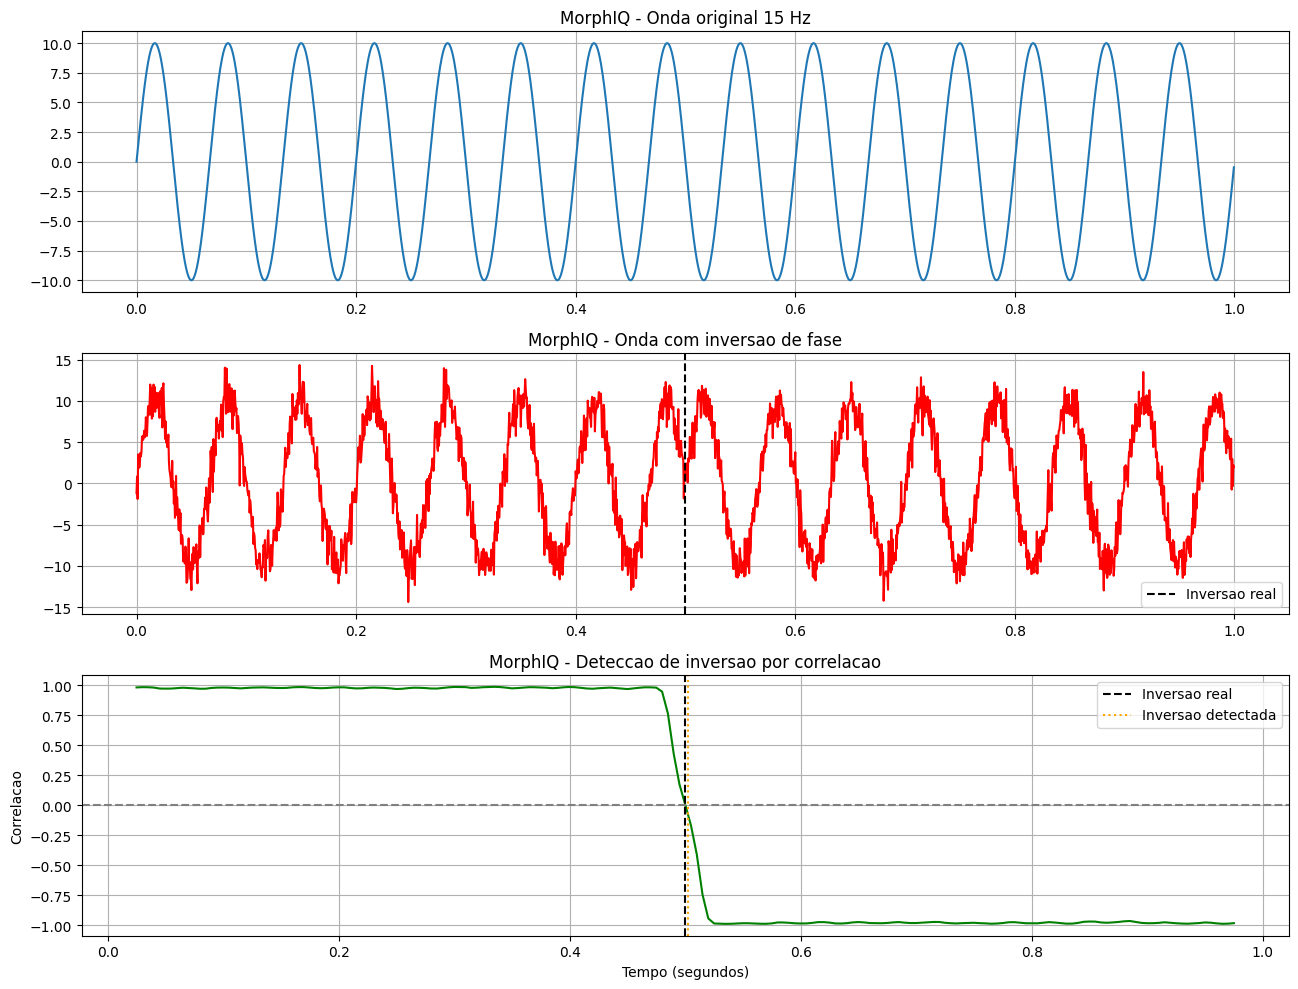

MORPHIQ - EXPERIMENTO 13
------------------------
Inversao real: 0.5 s
Inversao detectada: 0.5025
Erro temporal: 0.0025 s
RESULTADO: INVERSAO DETECTADA


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 13
# INVERSAO DE FASE E DETECCAO AUTOMATICA
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# Configuracoes
fs = 2000
duracao = 1
frequencia = 15
amplitude = 10
instante_inversao = 0.5

tempo = np.arange(0, duracao, 1/fs)

# Onda original
onda_original = amplitude * np.sin(
    2 * np.pi * frequencia * tempo
)

# Onda com inversao de fase
onda_modificada = onda_original.copy()

onda_modificada[
    tempo >= instante_inversao
] *= -1

# Adicionar ruido
rng = np.random.default_rng(2026)

onda_recebida = onda_modificada + rng.normal(
    0, 1.5, len(tempo)
)

# Deteccao por correlacao local
# Compara o sinal com uma referencia de 15 Hz
janela = 100
centros = []
correlacoes = []

for inicio in range(
    0, len(tempo) - janela + 1, 10
):
    fim = inicio + janela

    trecho = onda_recebida[inicio:fim]
    referencia = onda_original[inicio:fim]

    correlacao = np.dot(
        trecho, referencia
    ) / (
        np.linalg.norm(trecho)
        * np.linalg.norm(referencia)
        + 1e-12
    )

    centros.append(
        tempo[inicio + janela // 2]
    )
    correlacoes.append(correlacao)

centros = np.array(centros)
correlacoes = np.array(correlacoes)

# Detectar transicao positiva para negativa
mudancas = np.where(
    (correlacoes[:-1] >= 0) &
    (correlacoes[1:] < 0)
)[0]

if len(mudancas) > 0:
    indice = mudancas[0]
    tempo_detectado = (
        centros[indice] + centros[indice + 1]
    ) / 2
else:
    tempo_detectado = None

# Graficos
fig, eixos = plt.subplots(
    3, 1, figsize=(13, 10)
)

eixos[0].plot(tempo, onda_original)
eixos[0].set_title(
    "MorphIQ - Onda original 15 Hz"
)
eixos[0].grid(True)

eixos[1].plot(
    tempo, onda_recebida, color="red"
)
eixos[1].axvline(
    instante_inversao,
    color="black",
    linestyle="--",
    label="Inversao real"
)
eixos[1].set_title(
    "MorphIQ - Onda com inversao de fase"
)
eixos[1].legend()
eixos[1].grid(True)

eixos[2].plot(
    centros, correlacoes, color="green"
)
eixos[2].axhline(
    0, color="gray", linestyle="--"
)
eixos[2].axvline(
    instante_inversao,
    color="black",
    linestyle="--",
    label="Inversao real"
)

if tempo_detectado is not None:
    eixos[2].axvline(
        tempo_detectado,
        color="orange",
        linestyle=":",
        label="Inversao detectada"
    )

eixos[2].set_title(
    "MorphIQ - Deteccao de inversao por correlacao"
)
eixos[2].set_xlabel("Tempo (segundos)")
eixos[2].set_ylabel("Correlacao")
eixos[2].legend()
eixos[2].grid(True)

plt.tight_layout()
plt.show()

print("MORPHIQ - EXPERIMENTO 13")
print("------------------------")
print("Inversao real:", instante_inversao, "s")
print("Inversao detectada:", tempo_detectado)

if tempo_detectado is not None:
    erro = abs(
        tempo_detectado - instante_inversao
    )

    print("Erro temporal:", round(erro, 4), "s")

    if erro <= 0.05:
        print("RESULTADO: INVERSAO DETECTADA")
    else:
        print("RESULTADO: DETECCAO IMPRECISA")
else:
    print("RESULTADO: INVERSAO NAO DETECTADA")


Dispositivo 1: Taxa de aceitacao = 100.0%
Dispositivo 2: Taxa de aceitacao = 0.0%
Dispositivo 3: Taxa de aceitacao = 0.0%
Dispositivo 4: Taxa de aceitacao = 0.0%
Dispositivo 5: Taxa de aceitacao = 0.0%


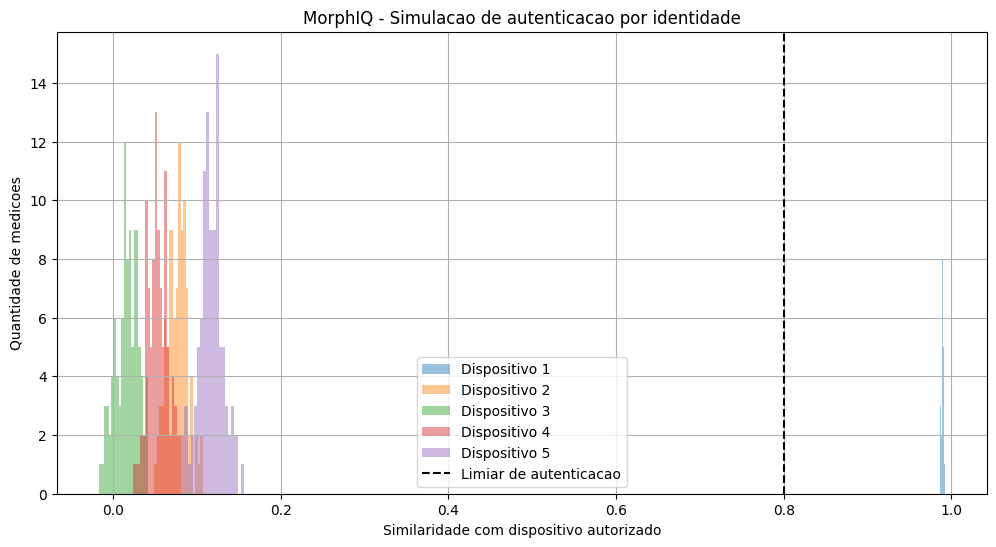


MORPHIQ - EXPERIMENTO 14
Dispositivo autorizado: 1
Limiar: 0.8
RESULTADO: IDENTIDADE SIMULADA RECONHECIDA


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 14
# SIMULACAO DE IDENTIDADE PUF
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

# Configuracoes
numero_dispositivos = 5
numero_caracteristicas = 128
numero_medicoes = 100
ruido_medicao = 0.15

# Identidades simuladas dos dispositivos
identidades = rng.normal(
    0, 1,
    (numero_dispositivos, numero_caracteristicas)
)

# Referencia cadastrada do dispositivo autorizado
referencia = identidades[0].copy()

# Funcao de medicao
def medir_dispositivo(indice):
    ruido = rng.normal(
        0,
        ruido_medicao,
        numero_caracteristicas
    )

    return identidades[indice] + ruido

# Funcao de similaridade
def similaridade(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) *
        np.linalg.norm(b) + 1e-12
    )

# Medir todos os dispositivos
resultados = []

for dispositivo in range(numero_dispositivos):

    similaridades = []

    for teste in range(numero_medicoes):
        medicao = medir_dispositivo(dispositivo)

        score = similaridade(
            referencia,
            medicao
        )

        similaridades.append(score)

    resultados.append(similaridades)

# Limiar de autenticacao ilustrativo
limiar = 0.80

# Avaliacao
aceitacoes = []

for dispositivo, scores in enumerate(resultados):

    taxa = np.mean(
        np.array(scores) >= limiar
    ) * 100

    aceitacoes.append(taxa)

    print(
        f"Dispositivo {dispositivo+1}: "
        f"Taxa de aceitacao = {taxa:.1f}%"
    )

# Graficos
plt.figure(figsize=(12, 6))

for i, scores in enumerate(resultados):
    plt.hist(
        scores,
        bins=20,
        alpha=0.45,
        label=f"Dispositivo {i+1}"
    )

plt.axvline(
    limiar,
    color="black",
    linestyle="--",
    label="Limiar de autenticacao"
)

plt.title(
    "MorphIQ - Simulacao de autenticacao por identidade"
)
plt.xlabel("Similaridade com dispositivo autorizado")
plt.ylabel("Quantidade de medicoes")
plt.legend()
plt.grid(True)
plt.show()

print("\nMORPHIQ - EXPERIMENTO 14")
print("Dispositivo autorizado: 1")
print("Limiar:", limiar)

if aceitacoes[0] >= 95 and all(
    taxa <= 5 for taxa in aceitacoes[1:]
):
    print("RESULTADO: IDENTIDADE SIMULADA RECONHECIDA")
else:
    print("RESULTADO: VERIFICAR SEPARACAO DAS IDENTIDADES")



Dispositivo: MorphIQ autorizado
Similaridade: 0.9896
Autorizado: True
Programa decodificado: [('ADD', 10), ('SUB', 3), ('ADD', 5), ('SUB', 2)]
Resultado final: 10

Dispositivo: Dispositivo nao autorizado
Similaridade: 0.0774
Autorizado: False
EXECUCAO BLOQUEADA

MORPHIQ - EXPERIMENTO 15
RESULTADO: INTEGRACAO SIMULADA CORRETA


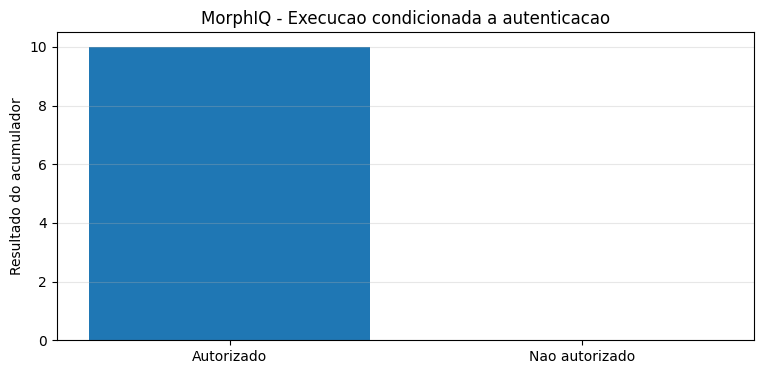

In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 15
# INTEGRACAO: ONDAS + RUIDO + AUTENTICACAO
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
tempo = np.arange(0, 1, 1/fs)

operacoes = {"ADD": 4, "SUB": 8}

programa = [
    ("ADD", 10),
    ("SUB", 3),
    ("ADD", 5),
    ("SUB", 2)
]

# 1 - GERAR IDENTIDADES SIMULADAS
identidade_autorizada = rng.normal(0, 1, 128)
identidade_intrusa = rng.normal(0, 1, 128)

referencia = identidade_autorizada.copy()
limiar = 0.80

def similaridade(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) *
        np.linalg.norm(b) + 1e-12
    )

def autenticar(identidade):
    medicao = identidade + rng.normal(
        0, 0.15, len(identidade)
    )

    score = similaridade(referencia, medicao)
    return score >= limiar, score

# 2 - CODIFICAR PROGRAMA EM ONDAS
sinais = []

for op, valor in programa:
    onda_op = 10 * np.sin(
        2 * np.pi * operacoes[op] * tempo
    )

    onda_valor = 7 * np.sin(
        2 * np.pi * (30 + valor) * tempo
    )

    ruido = rng.normal(0, 3.5, len(tempo))

    sinais.append(
        onda_op + onda_valor + ruido
    )

# 3 - DECODIFICAR PROGRAMA
def decodificar_programa(sinais):
    instrucoes = []

    for sinal in sinais:
        espectro = np.abs(np.fft.rfft(sinal))
        freqs = np.fft.rfftfreq(len(sinal), 1/fs)

        # Operacao
        faixa_op = (freqs >= 1) & (freqs <= 20)
        idx_op = np.where(faixa_op)[0][
            np.argmax(espectro[faixa_op])
        ]

        freq_op = freqs[idx_op]

        candidatos = [
            op for op, freq in operacoes.items()
            if abs(freq - freq_op) <= 0.5
        ]

        if not candidatos:
            raise ValueError("Operacao invalida")

        op = candidatos[0]

        # Valor
        faixa_valor = (freqs >= 30) & (freqs <= 100)
        idx_valor = np.where(faixa_valor)[0][
            np.argmax(espectro[faixa_valor])
        ]

        valor = int(round(freqs[idx_valor] - 30))
        instrucoes.append((op, valor))

    return instrucoes

# 4 - EXECUCAO CONDICIONADA
def executar_dispositivo(nome, identidade):
    autorizado, score = autenticar(identidade)

    print(f"\nDispositivo: {nome}")
    print(f"Similaridade: {score:.4f}")
    print(f"Autorizado: {autorizado}")

    if not autorizado:
        print("EXECUCAO BLOQUEADA")
        return None

    instrucoes = decodificar_programa(sinais)

    acumulador = 0

    for op, valor in instrucoes:
        if op == "ADD":
            acumulador += valor
        elif op == "SUB":
            acumulador -= valor

    print("Programa decodificado:", instrucoes)
    print("Resultado final:", acumulador)

    return acumulador

resultado_autorizado = executar_dispositivo(
    "MorphIQ autorizado",
    identidade_autorizada
)

resultado_intruso = executar_dispositivo(
    "Dispositivo nao autorizado",
    identidade_intrusa
)

print("\nMORPHIQ - EXPERIMENTO 15")

if resultado_autorizado == 10 and resultado_intruso is None:
    print("RESULTADO: INTEGRACAO SIMULADA CORRETA")
else:
    print("RESULTADO: VERIFICAR INTEGRACAO")

# 5 - VISUALIZACAO
plt.figure(figsize=(9, 4))

nomes = ["Autorizado", "Nao autorizado"]
valores = [
    resultado_autorizado if resultado_autorizado is not None else 0,
    resultado_intruso if resultado_intruso is not None else 0
]

plt.bar(nomes, valores)
plt.title("MorphIQ - Execucao condicionada a autenticacao")
plt.ylabel("Resultado do acumulador")
plt.grid(axis="y", alpha=0.3)
plt.show()


MORPHIQ - EXPERIMENTO 16
-----------------------------
Tentativas legitimas: 1000
Tentativas de intrusos: 1000
Falsas aceitacoes: 0
Falsas rejeicoes: 0
FAR observada: 0.00%
FRR observada: 0.00%


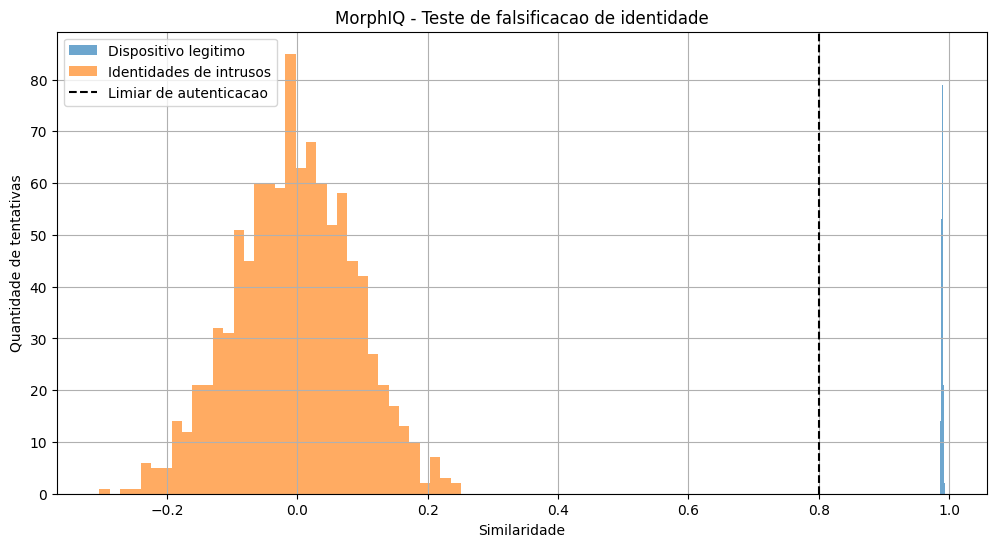

RESULTADO: NENHUM ERRO OBSERVADO


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 16
# TESTE DE FALSIFICACAO DE IDENTIDADE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

caracteristicas = 128
tentativas = 1000
limiar = 0.80
ruido = 0.15

# Identidade autorizada simulada
referencia = rng.normal(0, 1, caracteristicas)

def similaridade(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) *
        np.linalg.norm(b) + 1e-12
    )

scores_legitimos = []
scores_intrusos = []

for i in range(tentativas):

    # Medicao do dispositivo legitimo
    legitimo = referencia + rng.normal(
        0, ruido, caracteristicas
    )

    scores_legitimos.append(
        similaridade(referencia, legitimo)
    )

    # Identidade independente de intruso
    intruso = rng.normal(
        0, 1, caracteristicas
    )

    medicao_intruso = intruso + rng.normal(
        0, ruido, caracteristicas
    )

    scores_intrusos.append(
        similaridade(referencia, medicao_intruso)
    )

scores_legitimos = np.array(scores_legitimos)
scores_intrusos = np.array(scores_intrusos)

# Taxas de erro
falsas_aceitacoes = np.sum(
    scores_intrusos >= limiar
)

falsas_rejeicoes = np.sum(
    scores_legitimos < limiar
)

FAR = 100 * falsas_aceitacoes / tentativas
FRR = 100 * falsas_rejeicoes / tentativas

print("MORPHIQ - EXPERIMENTO 16")
print("-----------------------------")
print("Tentativas legitimas:", tentativas)
print("Tentativas de intrusos:", tentativas)
print("Falsas aceitacoes:", falsas_aceitacoes)
print("Falsas rejeicoes:", falsas_rejeicoes)
print(f"FAR observada: {FAR:.2f}%")
print(f"FRR observada: {FRR:.2f}%")

# Graficos
plt.figure(figsize=(12, 6))

plt.hist(
    scores_legitimos,
    bins=35,
    alpha=0.65,
    label="Dispositivo legitimo"
)

plt.hist(
    scores_intrusos,
    bins=35,
    alpha=0.65,
    label="Identidades de intrusos"
)

plt.axvline(
    limiar,
    color="black",
    linestyle="--",
    label="Limiar de autenticacao"
)

plt.title(
    "MorphIQ - Teste de falsificacao de identidade"
)

plt.xlabel("Similaridade")
plt.ylabel("Quantidade de tentativas")
plt.legend()
plt.grid(True)
plt.show()

if falsas_aceitacoes == 0 and falsas_rejeicoes == 0:
    print("RESULTADO: NENHUM ERRO OBSERVADO")
else:
    print("RESULTADO: ERROS OBSERVADOS")



Cenario: Normal
Instrucao recuperada: ADD 10
Integridade: True
Decisao: ACEITO

Cenario: Valor alterado
Instrucao recuperada: ADD 20
Integridade: False
Decisao: BLOQUEADO

Cenario: Operacao alterada
Instrucao recuperada: SUB 10
Integridade: False
Decisao: BLOQUEADO


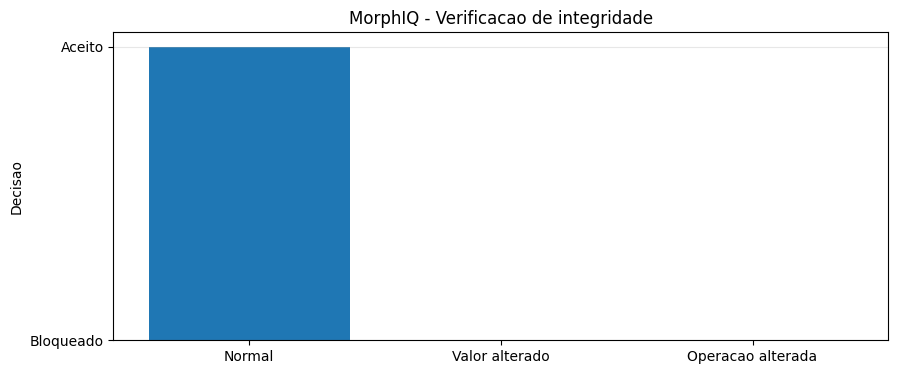


MORPHIQ - EXPERIMENTO 17
RESULTADO: ADULTERACOES DETECTADAS


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 17
# ADULTERACAO DE ONDAS E INTEGRIDADE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import hashlib
import hmac

fs = 1000
tempo = np.arange(0, 1, 1/fs)
rng = np.random.default_rng(2026)

operacoes = {"ADD": 4, "SUB": 8}
chave_teste = b"morphiq-chave-experimental"

# Codificacao das instrucoes em ondas
def codificar(op, valor):
    return (
        10 * np.sin(2*np.pi*operacoes[op]*tempo)
        + 7 * np.sin(2*np.pi*(30+valor)*tempo)
    )

# Decodificacao usando FFT
def decodificar(sinal):
    espectro = np.abs(np.fft.rfft(sinal))
    freqs = np.fft.rfftfreq(len(sinal), 1/fs)

    faixa_op = (freqs >= 1) & (freqs <= 20)
    faixa_valor = (freqs >= 30) & (freqs <= 100)

    freq_op = freqs[faixa_op][
        np.argmax(espectro[faixa_op])
    ]

    freq_valor = freqs[faixa_valor][
        np.argmax(espectro[faixa_valor])
    ]

    op = min(
        operacoes,
        key=lambda x: abs(operacoes[x]-freq_op)
    )

    valor = int(round(freq_valor - 30))
    return op, valor

# Etiqueta de integridade sobre a instrucao
def etiqueta(op, valor):
    mensagem = f"{op}:{valor}".encode()
    return hmac.new(
        chave_teste,
        mensagem,
        hashlib.sha256
    ).digest()

# Instrucao autorizada
original = ("ADD", 10)
etiqueta_original = etiqueta(*original)

# Sinais recebidos em tres cenarios
cenarios = {
    "Normal": codificar("ADD", 10),
    "Valor alterado": codificar("ADD", 20),
    "Operacao alterada": codificar("SUB", 10)
}

resultados = []

for nome, onda in cenarios.items():
    # Ruido de transmissao
    recebido = onda + rng.normal(
        0, 2, len(tempo)
    )

    op_rec, valor_rec = decodificar(recebido)

    # Comparar com a etiqueta original
    etiqueta_recebida = etiqueta(op_rec, valor_rec)

    integro = hmac.compare_digest(
        etiqueta_original,
        etiqueta_recebida
    )

    status = "ACEITO" if integro else "BLOQUEADO"

    resultados.append((nome, status))

    print(f"\nCenario: {nome}")
    print("Instrucao recuperada:", op_rec, valor_rec)
    print("Integridade:", integro)
    print("Decisao:", status)

# Grafico
nomes = [r[0] for r in resultados]
valores = [1 if r[1] == "ACEITO" else 0
           for r in resultados]

plt.figure(figsize=(10, 4))
plt.bar(nomes, valores)
plt.yticks([0, 1], ["Bloqueado", "Aceito"])
plt.title("MorphIQ - Verificacao de integridade")
plt.ylabel("Decisao")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("\nMORPHIQ - EXPERIMENTO 17")

esperado = [
    ("Normal", "ACEITO"),
    ("Valor alterado", "BLOQUEADO"),
    ("Operacao alterada", "BLOQUEADO")
]

if resultados == esperado:
    print("RESULTADO: ADULTERACOES DETECTADAS")
else:
    print("RESULTADO: VERIFICAR DETECCAO")


Ideal: 100/100 (100.0%)
Ruido intenso: 96/100 (96.0%)
Perda 20%: 100/100 (100.0%)
Interferencia 12 Hz: 32/100 (32.0%)
Desvio temporal: 100/100 (100.0%)


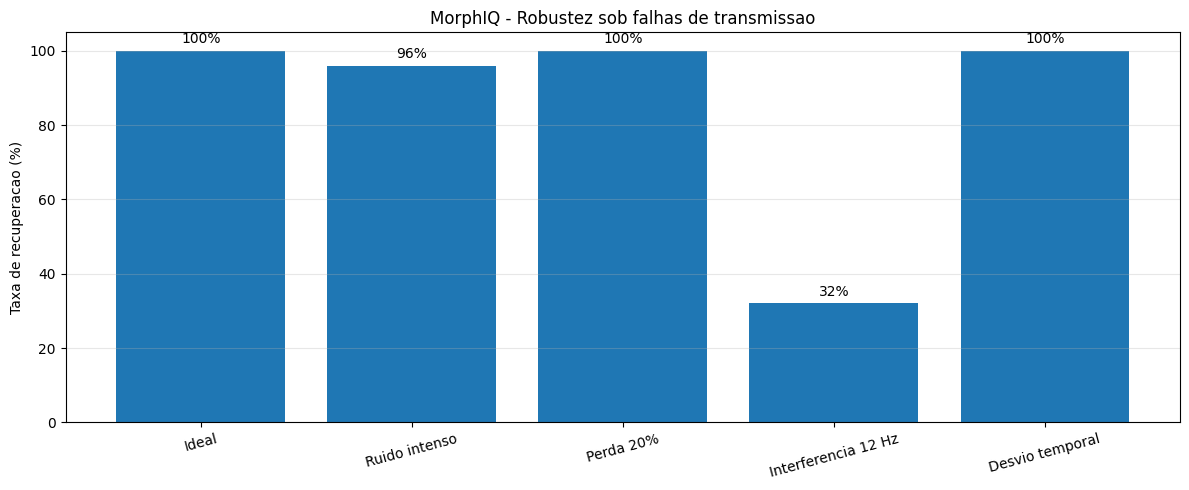


MORPHIQ - EXPERIMENTO 18
Total de testes: 500
Taxas obtidas: [100.0, 96.0, 100.0, 32.0, 100.0]


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 18
# ROBUSTEZ A FALHAS DE TRANSMISSAO
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 1000
tempo = np.arange(N) / fs

operacoes = {"ADD": 4, "SUB": 8, "JMP": 15}
nomes_operacoes = list(operacoes.keys())

testes_por_cenario = 100

cenarios = [
    "Ideal",
    "Ruido intenso",
    "Perda 20%",
    "Interferencia 12 Hz",
    "Desvio temporal"
]

def codificar(op, valor):
    return (
        10 * np.sin(2*np.pi*operacoes[op]*tempo)
        + 7 * np.sin(2*np.pi*(30+valor)*tempo)
    )

def aplicar_falha(sinal, cenario):

    s = sinal.copy()

    if cenario == "Ruido intenso":
        s += rng.normal(0, 35, N)

    elif cenario == "Perda 20%":
        indices = rng.choice(
            N, size=int(N*0.20), replace=False
        )
        s[indices] = 0

    elif cenario == "Interferencia 12 Hz":
        s += 12 * np.sin(
            2*np.pi*12*tempo
        )

    elif cenario == "Desvio temporal":
        # Deslocamento circular de 80 amostras
        s = np.roll(s, 80)

    return s

def decodificar(sinal):
    espectro = np.abs(np.fft.rfft(sinal))
    freqs = np.fft.rfftfreq(N, 1/fs)

    faixa_op = (freqs >= 1) & (freqs <= 20)
    faixa_valor = (freqs >= 30) & (freqs <= 60)

    freq_op = freqs[faixa_op][
        np.argmax(espectro[faixa_op])
    ]

    freq_valor = freqs[faixa_valor][
        np.argmax(espectro[faixa_valor])
    ]

    op = min(
        operacoes,
        key=lambda x: abs(operacoes[x]-freq_op)
    )

    valor = int(round(freq_valor - 30))

    return op, valor

taxas = []

for cenario in cenarios:

    acertos = 0

    for i in range(testes_por_cenario):

        op = rng.choice(nomes_operacoes)
        valor = int(rng.integers(1, 21))

        sinal = codificar(op, valor)
        recebido = aplicar_falha(
            sinal, cenario
        )

        op_rec, valor_rec = decodificar(
            recebido
        )

        if op_rec == op and valor_rec == valor:
            acertos += 1

    taxa = 100 * acertos / testes_por_cenario
    taxas.append(taxa)

    print(
        f"{cenario}: "
        f"{acertos}/{testes_por_cenario} "
        f"({taxa:.1f}%)"
    )

# GRAFICO
plt.figure(figsize=(12, 5))

barras = plt.bar(cenarios, taxas)

plt.ylim(0, 105)
plt.ylabel("Taxa de recuperacao (%)")
plt.title(
    "MorphIQ - Robustez sob falhas de transmissao"
)

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

for barra, taxa in zip(barras, taxas):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        taxa + 2,
        f"{taxa:.0f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 18")
print("Total de testes:",
      len(cenarios) * testes_por_cenario)
print("Taxas obtidas:", taxas)



Ideal
Decoder A: 100.0%
Decoder B: 100.0%

Ruido 35
Decoder A: 97.7%
Decoder B: 97.7%

Interferencia 12 Hz
Decoder A: 35.0%
Decoder B: 100.0%

Ruido + interferencia
Decoder A: 44.7%
Decoder B: 97.0%


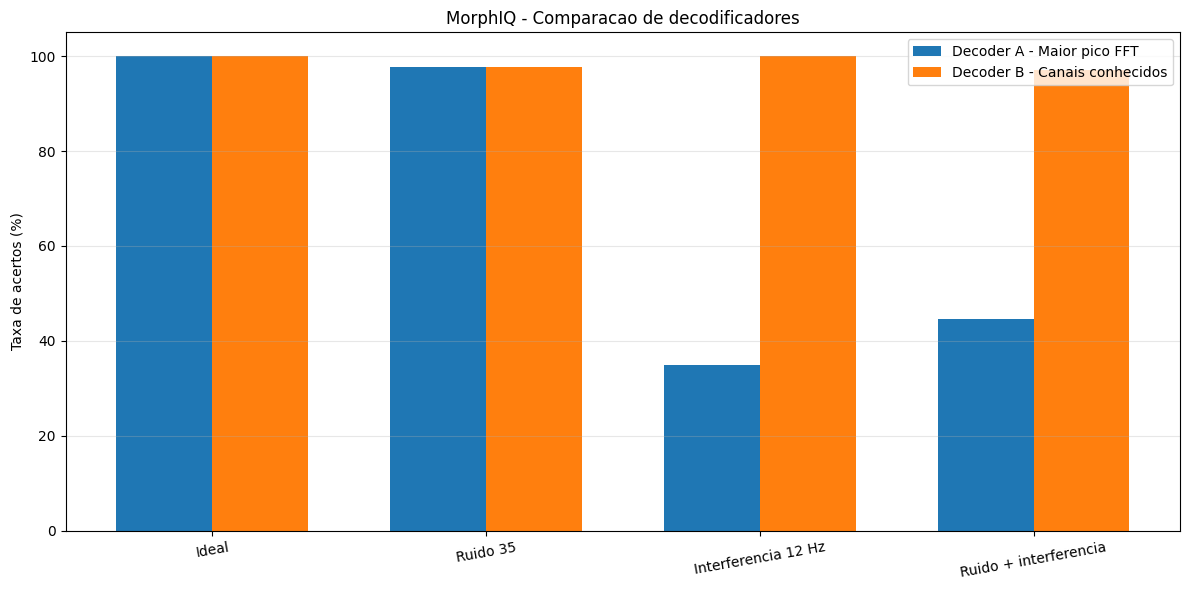


MORPHIQ - EXPERIMENTO 19
Total de sinais avaliados: 1200
Taxas A: [100.0, 97.66666666666667, 35.0, 44.666666666666664]
Taxas B: [100.0, 97.66666666666667, 100.0, 97.0]


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 19
# COMPARACAO DE DECODIFICADORES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 1000
tempo = np.arange(N) / fs

operacoes = {
    "ADD": 4,
    "SUB": 8,
    "JMP": 15
}

nomes = list(operacoes.keys())
n_testes = 300

cenarios = [
    "Ideal",
    "Ruido 35",
    "Interferencia 12 Hz",
    "Ruido + interferencia"
]

def codificar(op, valor):
    return (
        10*np.sin(2*np.pi*operacoes[op]*tempo)
        + 7*np.sin(2*np.pi*(30+valor)*tempo)
    )

def transmitir(sinal, cenario):
    s = sinal.copy()

    if cenario in [
        "Ruido 35",
        "Ruido + interferencia"
    ]:
        s += rng.normal(0, 35, N)

    if cenario in [
        "Interferencia 12 Hz",
        "Ruido + interferencia"
    ]:
        s += 12*np.sin(2*np.pi*12*tempo)

    return s

def decodificador_A(sinal):
    espectro = np.abs(np.fft.rfft(sinal))
    freqs = np.fft.rfftfreq(N, 1/fs)

    faixa_op = (freqs >= 1) & (freqs <= 20)
    freq_op = freqs[faixa_op][
        np.argmax(espectro[faixa_op])
    ]

    op = min(
        operacoes,
        key=lambda nome: abs(
            operacoes[nome] - freq_op
        )
    )

    faixa_valor = (freqs >= 30) & (freqs <= 50)
    freq_valor = freqs[faixa_valor][
        np.argmax(espectro[faixa_valor])
    ]

    return op, int(round(freq_valor - 30))

def decodificador_B(sinal):
    espectro = np.abs(np.fft.rfft(sinal))

    # Como N=fs, cada indice corresponde a 1 Hz
    op = max(
        operacoes,
        key=lambda nome: espectro[operacoes[nome]]
    )

    # Valores permitidos: 1 a 20
    valor = max(
        range(1, 21),
        key=lambda v: espectro[30+v]
    )

    return op, valor

taxas_A = []
taxas_B = []

for cenario in cenarios:

    acertos_A = 0
    acertos_B = 0

    for _ in range(n_testes):
        op = rng.choice(nomes)
        valor = int(rng.integers(1, 21))

        sinal = codificar(op, valor)
        recebido = transmitir(sinal, cenario)

        if decodificador_A(recebido) == (op, valor):
            acertos_A += 1

        if decodificador_B(recebido) == (op, valor):
            acertos_B += 1

    taxa_A = 100*acertos_A/n_testes
    taxa_B = 100*acertos_B/n_testes

    taxas_A.append(taxa_A)
    taxas_B.append(taxa_B)

    print(f"\n{cenario}")
    print(f"Decoder A: {taxa_A:.1f}%")
    print(f"Decoder B: {taxa_B:.1f}%")

# GRAFICO COMPARATIVO
x = np.arange(len(cenarios))
largura = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x-largura/2,
    taxas_A,
    largura,
    label="Decoder A - Maior pico FFT"
)

plt.bar(
    x+largura/2,
    taxas_B,
    largura,
    label="Decoder B - Canais conhecidos"
)

plt.xticks(x, cenarios, rotation=10)
plt.ylabel("Taxa de acertos (%)")
plt.ylim(0, 105)
plt.title(
    "MorphIQ - Comparacao de decodificadores"
)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 19")
print("Total de sinais avaliados:",
      len(cenarios)*n_testes)
print("Taxas A:", taxas_A)
print("Taxas B:", taxas_B)

Desvio 0.00 Hz | Fixo: 100.0% | Tolerante: 100.0%
Desvio 0.10 Hz | Fixo: 100.0% | Tolerante: 100.0%
Desvio 0.25 Hz | Fixo: 100.0% | Tolerante: 100.0%
Desvio 0.50 Hz | Fixo: 46.7% | Tolerante: 100.0%
Desvio 0.75 Hz | Fixo: 3.7% | Tolerante: 100.0%
Desvio 1.00 Hz | Fixo: 0.0% | Tolerante: 100.0%
Desvio 1.50 Hz | Fixo: 4.7% | Tolerante: 100.0%
Desvio 2.00 Hz | Fixo: 0.0% | Tolerante: 100.0%


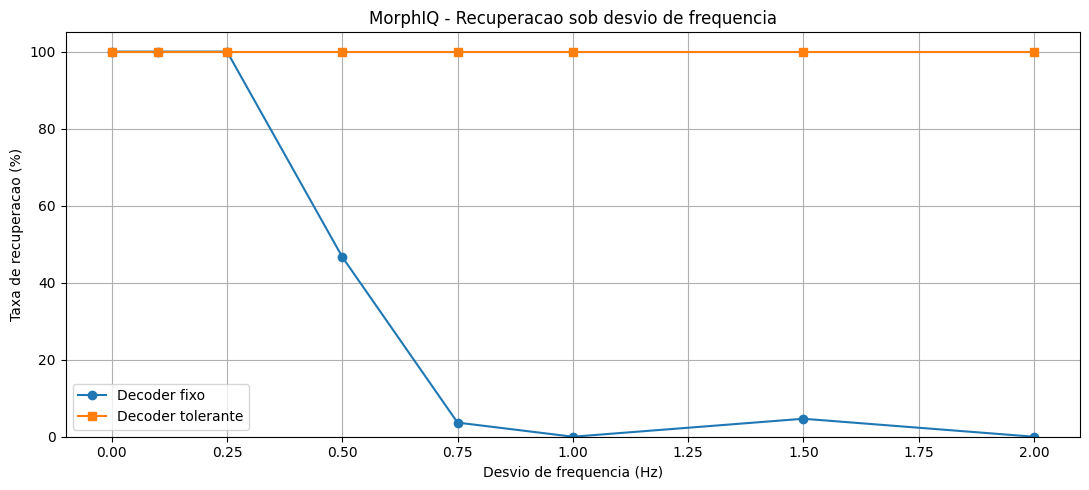


MORPHIQ - EXPERIMENTO 20
Total de testes: 2400
Taxas fixo: [100.0, 100.0, 100.0, 46.666666666666664, 3.6666666666666665, 0.0, 4.666666666666667, 0.0]
Taxas tolerante: [100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0]


In [ ]:

# ==========================================
# MORPHIQ - EXPERIMENTO 20
# DESVIO DE FREQUENCIA E SINCRONIZACAO
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 1000
t = np.arange(N) / fs

operacoes = {"ADD": 4, "SUB": 8, "JMP": 15}
nomes = list(operacoes)

desvios = [0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
testes_por_desvio = 300

def gerar_sinal(op, valor, desvio):
    # O mesmo desvio e aplicado aos dois canais
    freq_op = operacoes[op] + desvio
    freq_valor = 30 + valor + desvio

    return (
        10*np.sin(2*np.pi*freq_op*t)
        + 7*np.sin(2*np.pi*freq_valor*t)
        + rng.normal(0, 3, N)
    )

def decoder_fixo(s):
    espectro = np.abs(np.fft.rfft(s))

    op = max(
        operacoes,
        key=lambda x: espectro[operacoes[x]]
    )

    valor = max(
        range(1, 21),
        key=lambda v: espectro[30+v]
    )

    return op, valor

def decoder_tolerante(s):
    # Busca frequencias com resolucao refinada
    nfft = 16000

    espectro = np.abs(
        np.fft.rfft(s*np.hanning(N), n=nfft)
    )
    freqs = np.fft.rfftfreq(nfft, 1/fs)

    # Detecta operacao mais proxima
    faixa_op = (freqs >= 2) & (freqs <= 18)
    freq_op = freqs[faixa_op][
        np.argmax(espectro[faixa_op])
    ]

    op = min(
        operacoes,
        key=lambda x: abs(
            operacoes[x]-freq_op
        )
    )

    # Estima desvio pelo canal da operacao
    desvio_estimado = freq_op - operacoes[op]

    # Compensa o desvio no canal do valor
    candidatos = range(1, 21)

    def energia_valor(v):
        alvo = 30 + v + desvio_estimado
        indice = np.argmin(
            np.abs(freqs-alvo)
        )
        return espectro[indice]

    valor = max(candidatos, key=energia_valor)

    return op, valor

taxas_fixo = []
taxas_tolerante = []

for desvio in desvios:

    acertos_fixo = 0
    acertos_tolerante = 0

    for _ in range(testes_por_desvio):
        op = rng.choice(nomes)
        valor = int(rng.integers(1, 21))

        sinal = gerar_sinal(
            op, valor, desvio
        )

        if decoder_fixo(sinal) == (op, valor):
            acertos_fixo += 1

        if decoder_tolerante(sinal) == (op, valor):
            acertos_tolerante += 1

    taxa_fixo = 100*acertos_fixo/testes_por_desvio
    taxa_tol = 100*acertos_tolerante/testes_por_desvio

    taxas_fixo.append(taxa_fixo)
    taxas_tolerante.append(taxa_tol)

    print(
        f"Desvio {desvio:.2f} Hz | "
        f"Fixo: {taxa_fixo:.1f}% | "
        f"Tolerante: {taxa_tol:.1f}%"
    )

plt.figure(figsize=(11, 5))

plt.plot(
    desvios, taxas_fixo,
    marker="o",
    label="Decoder fixo"
)

plt.plot(
    desvios, taxas_tolerante,
    marker="s",
    label="Decoder tolerante"
)

plt.xlabel("Desvio de frequencia (Hz)")
plt.ylabel("Taxa de recuperacao (%)")
plt.title(
    "MorphIQ - Recuperacao sob desvio de frequencia"
)

plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 20")
print("Total de testes:",
      len(desvios)*testes_por_desvio)
print("Taxas fixo:", taxas_fixo)
print("Taxas tolerante:", taxas_tolerante)

Desvio independente +/-0.00 Hz | Acertos: 300/300 | Taxa: 100.0%
Desvio independente +/-0.10 Hz | Acertos: 300/300 | Taxa: 100.0%
Desvio independente +/-0.25 Hz | Acertos: 300/300 | Taxa: 100.0%
Desvio independente +/-0.50 Hz | Acertos: 226/300 | Taxa: 75.3%
Desvio independente +/-0.75 Hz | Acertos: 171/300 | Taxa: 57.0%
Desvio independente +/-1.00 Hz | Acertos: 142/300 | Taxa: 47.3%


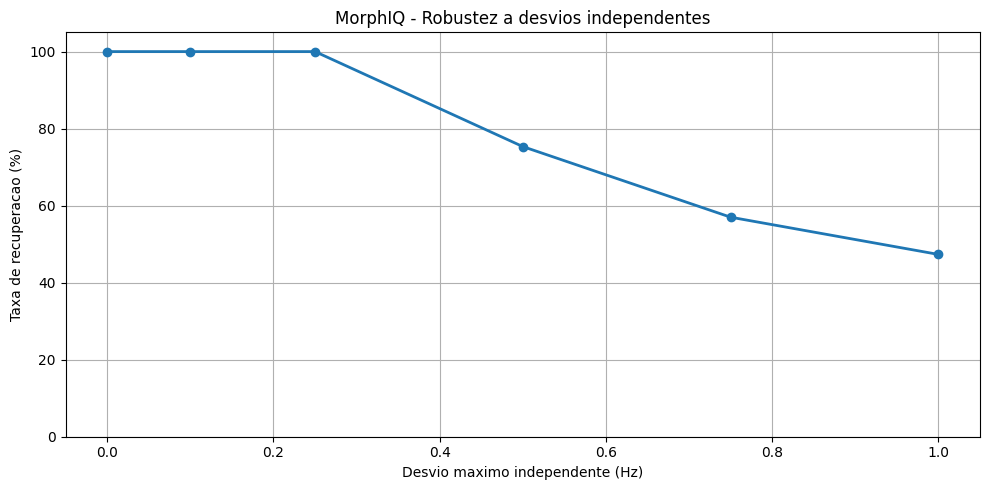


MORPHIQ - EXPERIMENTO 21
Total de testes: 1800
Taxas: [100.0, 100.0, 100.0, 75.33333333333333, 57.0, 47.333333333333336]


In [ ]:

# ============================================
# MORPHIQ - EXPERIMENTO 21
# DESVIOS INDEPENDENTES E INTERFERENCIA
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 1000
t = np.arange(N) / fs

operacoes = {"ADD": 4, "SUB": 8, "JMP": 15}
nomes = list(operacoes.keys())

n_testes = 300
desvios_maximos = [0, 0.1, 0.25, 0.5, 0.75, 1.0]

def gerar_sinal(op, valor, desvio_op, desvio_valor):
    freq_op = operacoes[op] + desvio_op
    freq_valor = 30 + valor + desvio_valor

    sinal = (
        10*np.sin(2*np.pi*freq_op*t)
        + 7*np.sin(2*np.pi*freq_valor*t)
    )

    # Ruido e interferencia adicional
    sinal += rng.normal(0, 5, N)
    sinal += 5*np.sin(2*np.pi*12*t)

    return sinal

def decodificar_tolerante(sinal):
    nfft = 16000

    espectro = np.abs(
        np.fft.rfft(sinal*np.hanning(N), n=nfft)
    )
    freqs = np.fft.rfftfreq(nfft, 1/fs)

    # Busca da frequencia de operacao
    faixa = (freqs >= 2) & (freqs <= 18)

    freq_detectada = freqs[faixa][
        np.argmax(espectro[faixa])
    ]

    op = min(
        operacoes,
        key=lambda x: abs(
            operacoes[x] - freq_detectada
        )
    )

    # Compensacao estimada pelo canal de operacao
    desvio_estimado = (
        freq_detectada - operacoes[op]
    )

    def energia_valor(v):
        alvo = 30 + v + desvio_estimado
        indice = np.argmin(
            np.abs(freqs - alvo)
        )
        return espectro[indice]

    valor = max(range(1, 21), key=energia_valor)

    return op, valor

taxas = []

for limite in desvios_maximos:

    acertos = 0

    for _ in range(n_testes):

        op = rng.choice(nomes)
        valor = int(rng.integers(1, 21))

        desvio_op = rng.uniform(-limite, limite)
        desvio_valor = rng.uniform(-limite, limite)

        sinal = gerar_sinal(
            op, valor, desvio_op, desvio_valor
        )

        recuperado = decodificar_tolerante(sinal)

        if recuperado == (op, valor):
            acertos += 1

    taxa = 100*acertos/n_testes
    taxas.append(taxa)

    print(
        f"Desvio independente +/-{limite:.2f} Hz "
        f"| Acertos: {acertos}/{n_testes} "
        f"| Taxa: {taxa:.1f}%"
    )

plt.figure(figsize=(10, 5))
plt.plot(
    desvios_maximos,
    taxas,
    marker="o",
    linewidth=2
)

plt.xlabel("Desvio maximo independente (Hz)")
plt.ylabel("Taxa de recuperacao (%)")
plt.title(
    "MorphIQ - Robustez a desvios independentes"
)
plt.ylim(0, 105)
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 21")
print("Total de testes:",
      len(desvios_maximos)*n_testes)
print("Taxas:", taxas)


Espaco 1 Hz | Desvio +/-0.00 Hz | Acertos 100.0%
Espaco 1 Hz | Desvio +/-0.25 Hz | Acertos 99.7%
Espaco 1 Hz | Desvio +/-0.50 Hz | Acertos 74.3%
Espaco 1 Hz | Desvio +/-0.75 Hz | Acertos 55.7%
Espaco 1 Hz | Desvio +/-1.00 Hz | Acertos 46.7%
Espaco 2 Hz | Desvio +/-0.00 Hz | Acertos 100.0%
Espaco 2 Hz | Desvio +/-0.25 Hz | Acertos 100.0%
Espaco 2 Hz | Desvio +/-0.50 Hz | Acertos 100.0%
Espaco 2 Hz | Desvio +/-0.75 Hz | Acertos 89.7%
Espaco 2 Hz | Desvio +/-1.00 Hz | Acertos 75.7%
Espaco 4 Hz | Desvio +/-0.00 Hz | Acertos 100.0%
Espaco 4 Hz | Desvio +/-0.25 Hz | Acertos 100.0%
Espaco 4 Hz | Desvio +/-0.50 Hz | Acertos 100.0%
Espaco 4 Hz | Desvio +/-0.75 Hz | Acertos 100.0%
Espaco 4 Hz | Desvio +/-1.00 Hz | Acertos 97.0%


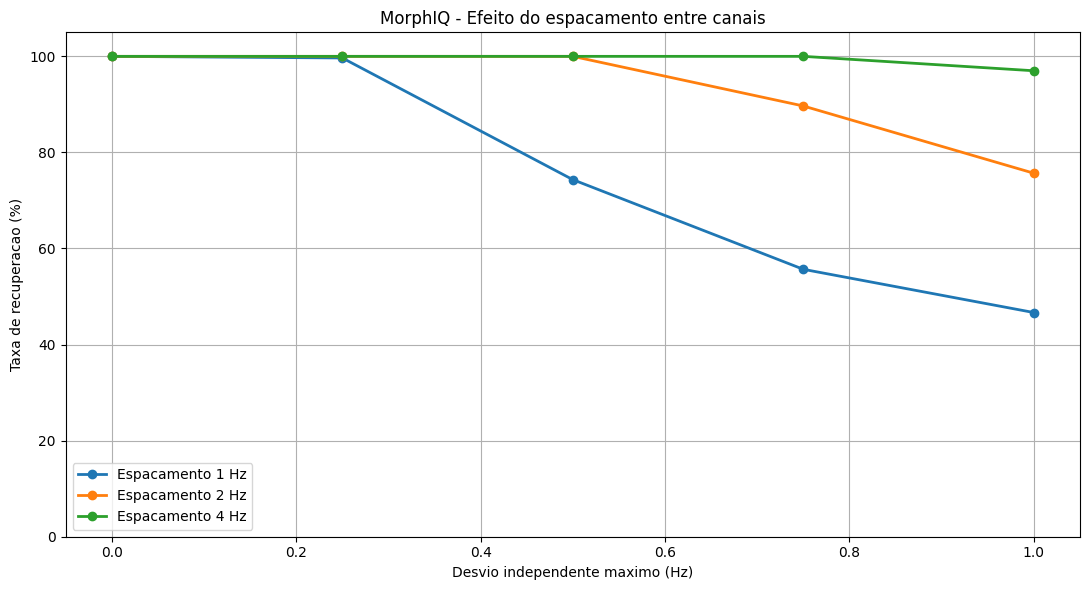


MORPHIQ - EXPERIMENTO 22
Total de transmissoes: 4500
Espacamento 1 Hz: [100.0, 99.66666666666667, 74.33333333333333, 55.666666666666664, 46.666666666666664]
Espacamento 2 Hz: [100.0, 100.0, 100.0, 89.66666666666667, 75.66666666666667]
Espacamento 4 Hz: [100.0, 100.0, 100.0, 100.0, 97.0]


In [ ]:

# ============================================
# MORPHIQ - EXPERIMENTO 22
# ESPACAMENTO DE FREQUENCIAS E ROBUSTEZ
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 1000
t = np.arange(N) / fs

operacoes = {"ADD": 4, "SUB": 8, "JMP": 15}
nomes = list(operacoes)

espacamentos = [1, 2, 4]
desvios = [0, 0.25, 0.5, 0.75, 1.0]
testes = 300

def gerar(op, valor, espaco, d_op, d_val):
    return (
        10*np.sin(
            2*np.pi*(operacoes[op]+d_op)*t
        )
        + 7*np.sin(
            2*np.pi*(30+espaco*valor+d_val)*t
        )
        + 5*np.sin(2*np.pi*12*t)
        + rng.normal(0, 5, N)
    )

def decodificar(sinal, espaco):
    nfft = 16000

    espectro = np.abs(
        np.fft.rfft(
            sinal*np.hanning(N),
            n=nfft
        )
    )

    freqs = np.fft.rfftfreq(nfft, 1/fs)

    # Canal da operacao
    faixa = (freqs >= 2) & (freqs <= 18)

    f_op = freqs[faixa][
        np.argmax(espectro[faixa])
    ]

    op = min(
        operacoes,
        key=lambda x: abs(operacoes[x]-f_op)
    )

    # Estimativa do desvio da operacao
    d_est = f_op - operacoes[op]

    # Canal do valor numerico
    def energia(v):
        alvo = 30 + espaco*v + d_est
        indice = np.argmin(
            np.abs(freqs-alvo)
        )
        return espectro[indice]

    valor = max(range(1, 21), key=energia)

    return op, valor

resultados = {}

for espaco in espacamentos:

    taxas = []

    for limite in desvios:

        acertos = 0

        for _ in range(testes):

            op = rng.choice(nomes)
            valor = int(rng.integers(1, 21))

            d_op = rng.uniform(-limite, limite)
            d_val = rng.uniform(-limite, limite)

            sinal = gerar(
                op, valor, espaco,
                d_op, d_val
            )

            recuperado = decodificar(
                sinal, espaco
            )

            if recuperado == (op, valor):
                acertos += 1

        taxa = 100*acertos/testes
        taxas.append(taxa)

        print(
            f"Espaco {espaco} Hz | "
            f"Desvio +/-{limite:.2f} Hz | "
            f"Acertos {taxa:.1f}%"
        )

    resultados[espaco] = taxas

plt.figure(figsize=(11, 6))

for espaco in espacamentos:
    plt.plot(
        desvios,
        resultados[espaco],
        marker="o",
        linewidth=2,
        label=f"Espacamento {espaco} Hz"
    )

plt.xlabel("Desvio independente maximo (Hz)")
plt.ylabel("Taxa de recuperacao (%)")
plt.title(
    "MorphIQ - Efeito do espacamento entre canais"
)
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 22")
print("Total de transmissoes:",
      len(espacamentos)*len(desvios)*testes)

for espaco in espacamentos:
    print(
        f"Espacamento {espaco} Hz:",
        resultados[espaco]
    )


Desvio +/-0.10 Hz | Espacamento escolhido: 1 Hz
  Fixo 1 Hz: 100.0%
  Fixo 2 Hz: 100.0%
  Fixo 4 Hz: 100.0%
  Adaptativo: 100.0%
Desvio +/-0.25 Hz | Espacamento escolhido: 1 Hz
  Fixo 1 Hz: 99.7%
  Fixo 2 Hz: 100.0%
  Fixo 4 Hz: 100.0%
  Adaptativo: 99.7%
Desvio +/-0.50 Hz | Espacamento escolhido: 2 Hz
  Fixo 1 Hz: 74.3%
  Fixo 2 Hz: 99.7%
  Fixo 4 Hz: 100.0%
  Adaptativo: 99.7%
Desvio +/-0.75 Hz | Espacamento escolhido: 4 Hz
  Fixo 1 Hz: 55.7%
  Fixo 2 Hz: 89.0%
  Fixo 4 Hz: 100.0%
  Adaptativo: 100.0%
Desvio +/-1.00 Hz | Espacamento escolhido: 4 Hz
  Fixo 1 Hz: 46.7%
  Fixo 2 Hz: 78.7%
  Fixo 4 Hz: 97.0%
  Adaptativo: 97.0%


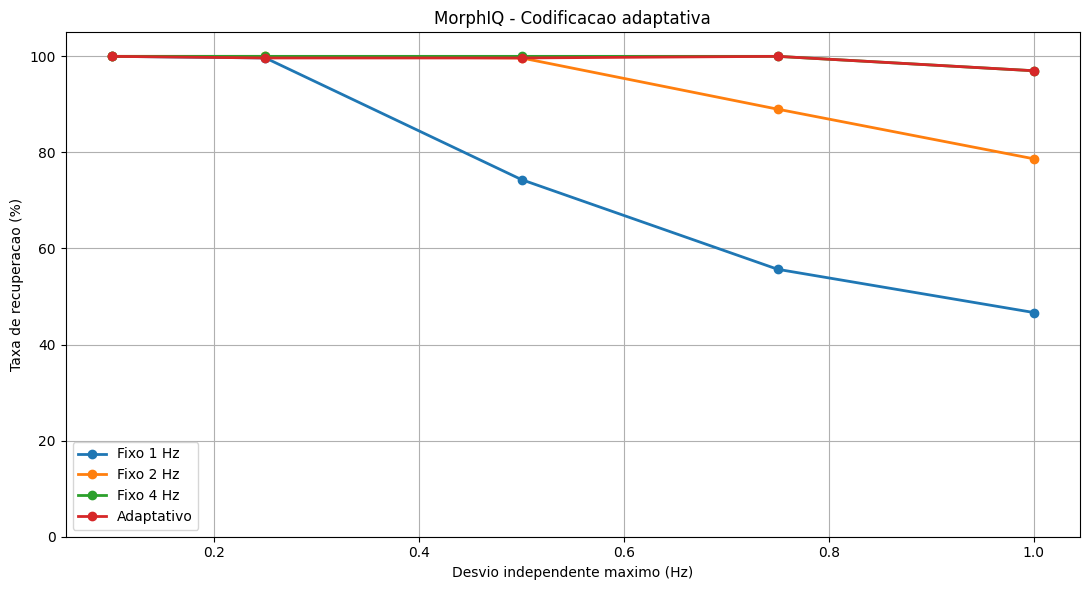

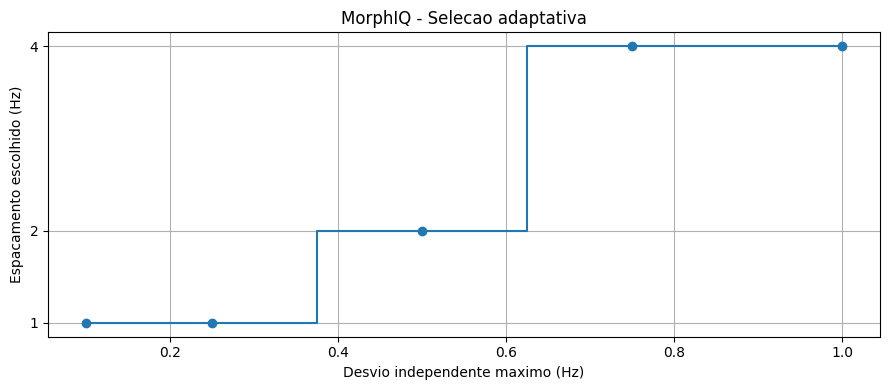


MORPHIQ - EXPERIMENTO 23
Total de cenarios de referencia: 1500
Espacamentos adaptativos: [1, 1, 2, 4, 4]


In [ ]:

# ============================================
# MORPHIQ - EXPERIMENTO 23
# CODIFICACAO ADAPTATIVA DE FREQUENCIAS
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 1000
t = np.arange(N) / fs
janela = np.hanning(N)

operacoes = {"ADD": 4, "SUB": 8, "JMP": 15}
nomes = list(operacoes.keys())

limites = [0.1, 0.25, 0.5, 0.75, 1.0]
espacamentos = [1, 2, 4]
testes = 300

nfft = 16000
freqs = np.fft.rfftfreq(nfft, 1/fs)

def gerar(op, valor, espaco, d_op, d_val, ruido):
    return (
        10*np.sin(2*np.pi*(operacoes[op]+d_op)*t)
        + 7*np.sin(2*np.pi*(30+espaco*valor+d_val)*t)
        + 5*np.sin(2*np.pi*12*t)
        + ruido
    )

def decodificar(sinal, espaco):
    espectro = np.abs(
        np.fft.rfft(sinal*janela, n=nfft)
    )

    faixa = (freqs >= 2) & (freqs <= 18)
    f_op = freqs[faixa][
        np.argmax(espectro[faixa])
    ]

    op = min(
        operacoes,
        key=lambda x: abs(operacoes[x]-f_op)
    )

    desvio_estimado = f_op - operacoes[op]

    def energia(v):
        alvo = 30 + espaco*v + desvio_estimado
        indice = np.argmin(np.abs(freqs-alvo))
        return espectro[indice]

    valor = max(range(1, 21), key=energia)
    return op, valor

def selecionar_espacamento(limite):
    # Regra experimental com qualidade conhecida
    if limite <= 0.25:
        return 1
    elif limite <= 0.5:
        return 2
    else:
        return 4

resultados = {
    "Fixo 1 Hz": [],
    "Fixo 2 Hz": [],
    "Fixo 4 Hz": [],
    "Adaptativo": []
}

espacos_escolhidos = []

for limite in limites:

    espaco_adaptativo = selecionar_espacamento(limite)
    espacos_escolhidos.append(espaco_adaptativo)

    acertos = {chave: 0 for chave in resultados}

    for _ in range(testes):
        op = rng.choice(nomes)
        valor = int(rng.integers(1, 21))

        d_op = rng.uniform(-limite, limite)
        d_val = rng.uniform(-limite, limite)
        ruido = rng.normal(0, 5, N)

        for espaco in espacamentos:
            sinal = gerar(
                op, valor, espaco,
                d_op, d_val, ruido
            )

            recuperado = decodificar(sinal, espaco)

            if recuperado == (op, valor):
                acertos[f"Fixo {espaco} Hz"] += 1

            if espaco == espaco_adaptativo:
                if recuperado == (op, valor):
                    acertos["Adaptativo"] += 1

    for chave in resultados:
        taxa = 100*acertos[chave]/testes
        resultados[chave].append(taxa)

    print(
        f"Desvio +/-{limite:.2f} Hz | "
        f"Espacamento escolhido: {espaco_adaptativo} Hz"
    )

    for chave in resultados:
        print(
            f"  {chave}: {resultados[chave][-1]:.1f}%"
        )

# GRAFICO DE RECUPERACAO
plt.figure(figsize=(11, 6))

for nome, taxas in resultados.items():
    plt.plot(
        limites, taxas,
        marker="o", linewidth=2,
        label=nome
    )

plt.xlabel("Desvio independente maximo (Hz)")
plt.ylabel("Taxa de recuperacao (%)")
plt.title("MorphIQ - Codificacao adaptativa")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# GRAFICO DO ESPACAMENTO ESCOLHIDO
plt.figure(figsize=(9, 4))
plt.step(
    limites, espacos_escolhidos,
    where="mid", marker="o"
)
plt.yticks([1, 2, 4])
plt.xlabel("Desvio independente maximo (Hz)")
plt.ylabel("Espacamento escolhido (Hz)")
plt.title("MorphIQ - Selecao adaptativa")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 23")
print("Total de cenarios de referencia:",
      len(limites)*testes)
print("Espacamentos adaptativos:",
      espacos_escolhidos)

MORPHIQ - EXPERIMENTO 24
----------------------------
Entrada A: 5 Hz
Entrada B: 3 Hz
Frequencia recuperada: 8.0 Hz
Resultado esperado: 8 Hz
Erro: 0.0 Hz
TESTE APROVADO


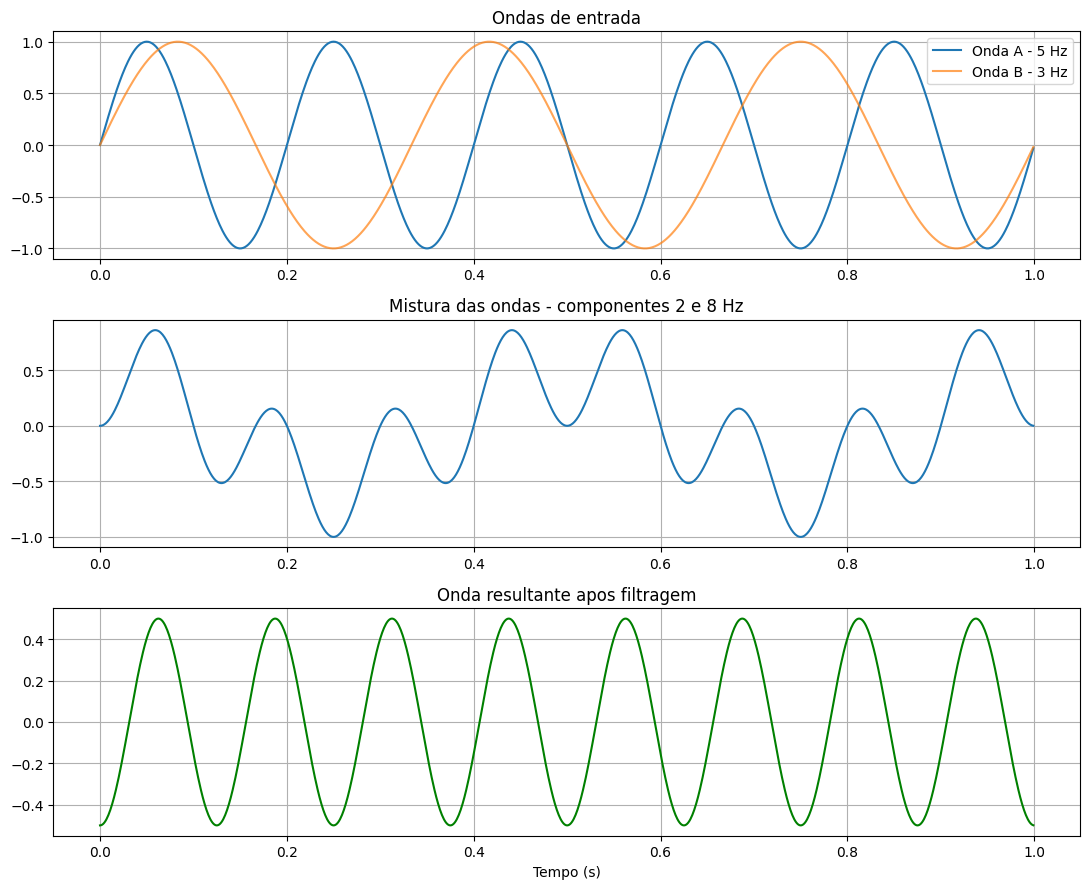

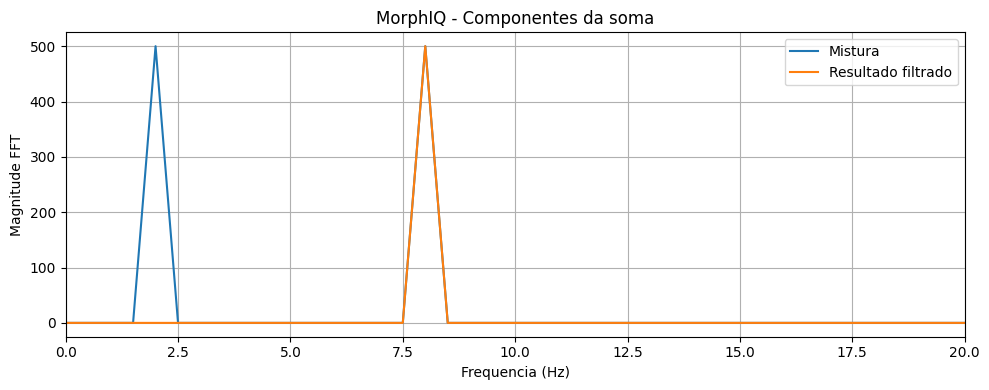

In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 24
# SOMA POR MISTURA DE ONDAS
# ============================================

import numpy as np
import matplotlib.pyplot as plt

# Configuracoes
fs = 1000
duracao = 2
t = np.arange(0, duracao, 1/fs)

# Numeros representados por frequencias
A = 5
B = 3

# Geracao das ondas
onda_A = np.sin(2*np.pi*A*t)
onda_B = np.sin(2*np.pi*B*t)

# Operacao sobre os sinais
# Um misturador analogico pode realizar
# esta multiplicacao fisicamente.
mistura = onda_A * onda_B

# Espectro da mistura
N = len(t)
freqs = np.fft.rfftfreq(N, 1/fs)
espectro = np.abs(np.fft.rfft(mistura))

# Filtro ideal em frequencia:
# mantem a componente acima de 6 Hz.
# O limite e conhecido neste teste.
espectro_complexo = np.fft.rfft(mistura)

mascara = freqs > 6
espectro_filtrado = (
    espectro_complexo * mascara
)

onda_resultado = np.fft.irfft(
    espectro_filtrado, n=N
)

# Medicao da frequencia resultante
espectro_resultado = np.abs(
    np.fft.rfft(onda_resultado)
)

indice = np.argmax(espectro_resultado[1:]) + 1
frequencia_resultado = freqs[indice]

print("MORPHIQ - EXPERIMENTO 24")
print("----------------------------")
print("Entrada A:", A, "Hz")
print("Entrada B:", B, "Hz")
print("Frequencia recuperada:",
      frequencia_resultado, "Hz")

# Apenas para verificar o resultado
esperado = A + B
erro = abs(frequencia_resultado - esperado)

print("Resultado esperado:", esperado, "Hz")
print("Erro:", erro, "Hz")

if erro < 0.01:
    print("TESTE APROVADO")
else:
    print("TESTE NAO APROVADO")

# Graficos
fig, axs = plt.subplots(3, 1, figsize=(11, 9))

trecho = t < 1

axs[0].plot(t[trecho], onda_A[trecho],
            label="Onda A - 5 Hz")
axs[0].plot(t[trecho], onda_B[trecho],
            label="Onda B - 3 Hz", alpha=0.7)
axs[0].set_title("Ondas de entrada")
axs[0].legend()
axs[0].grid(True)

axs[1].plot(t[trecho], mistura[trecho])
axs[1].set_title(
    "Mistura das ondas - componentes 2 e 8 Hz"
)
axs[1].grid(True)

axs[2].plot(
    t[trecho], onda_resultado[trecho],
    color="green"
)
axs[2].set_title(
    "Onda resultante apos filtragem"
)
axs[2].set_xlabel("Tempo (s)")
axs[2].grid(True)

plt.tight_layout()
plt.show()

# Espectro de frequencias
plt.figure(figsize=(10, 4))
plt.plot(freqs, espectro, label="Mistura")
plt.plot(
    freqs, espectro_resultado,
    label="Resultado filtrado"
)
plt.xlim(0, 20)
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude FFT")
plt.title("MorphIQ - Componentes da soma")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

MORPHIQ - EXPERIMENTO 25
-------------------------------
Total de testes: 100
Acertos: 100
Taxa de recuperacao: 100.0 %
Erro medio: 0.0 Hz
Erro maximo: 0.0 Hz


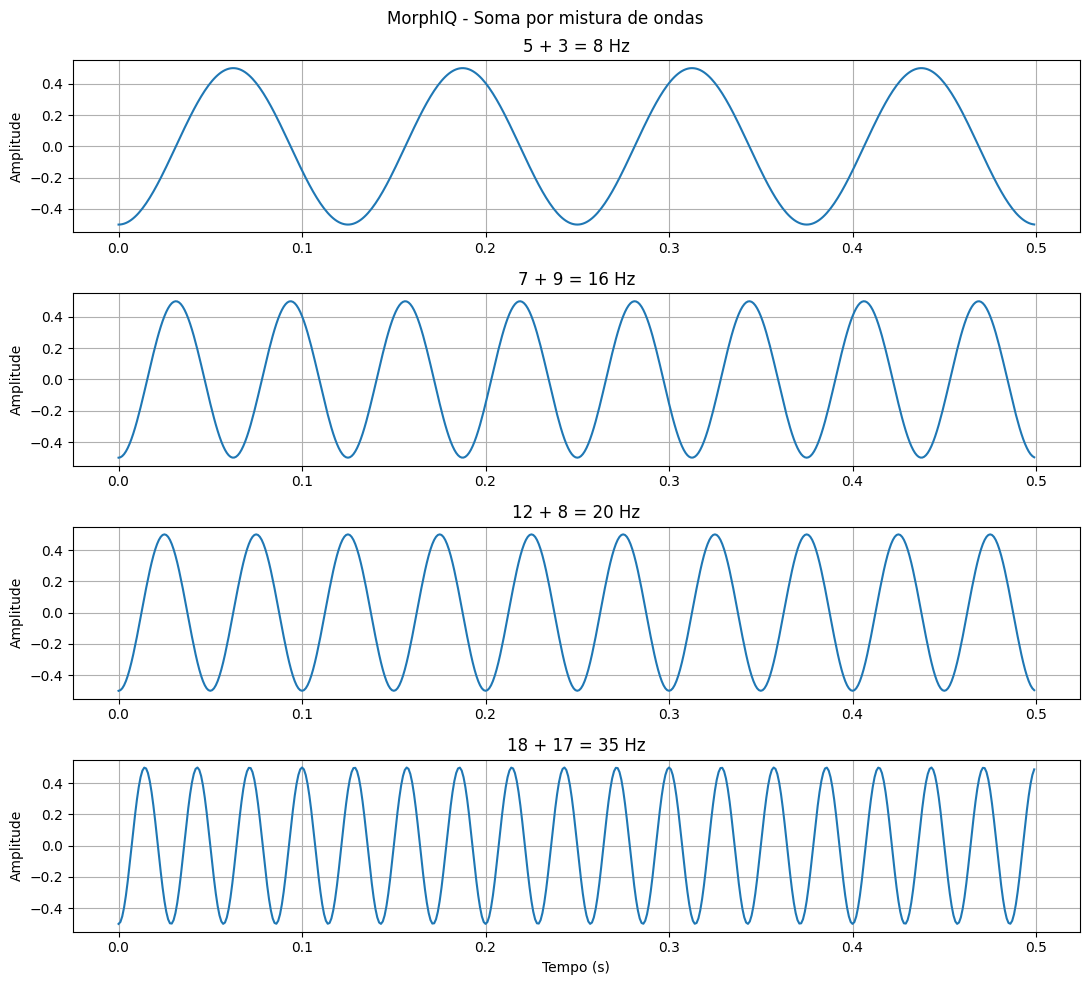

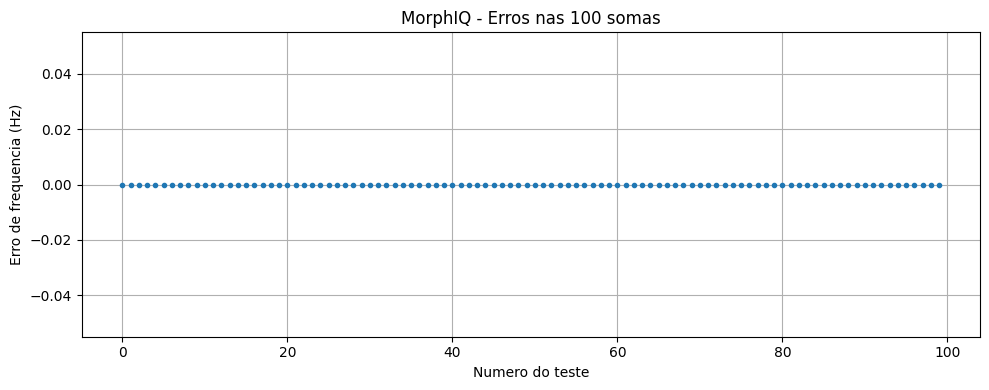

In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 25
# SOMA DE MULTIPLOS NUMEROS POR ONDAS
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
duracao = 2
t = np.arange(0, duracao, 1/fs)
N = len(t)

freqs = np.fft.rfftfreq(N, 1/fs)

def soma_por_ondas(a, b):
    # Cada numero e uma frequencia
    onda_a = np.sin(2*np.pi*a*t)
    onda_b = np.sin(2*np.pi*b*t)

    # Mistura dos sinais
    mistura = onda_a * onda_b

    # Analise espectral
    fft = np.fft.rfft(mistura)
    magnitude = np.abs(fft)

    # Identifica picos significativos
    limiar = 0.20 * np.max(magnitude)

    indices = np.where(
        (magnitude >= limiar) &
        (freqs > 0)
    )[0]

    # Seleciona a maior frequencia significativa
    indice_soma = indices[np.argmax(freqs[indices])]
    frequencia_soma = freqs[indice_soma]

    # Isola a onda correspondente a soma
    fft_filtrada = np.zeros_like(fft)
    fft_filtrada[indice_soma] = fft[indice_soma]

    onda_resultado = np.fft.irfft(
        fft_filtrada, n=N
    )

    return frequencia_soma, onda_resultado

# Testes
total = 100
acertos = 0
erros = []

for _ in range(total):
    a = int(rng.integers(1, 21))
    b = int(rng.integers(1, 21))

    resultado, onda = soma_por_ondas(a, b)
    esperado = a + b

    erro = abs(resultado - esperado)
    erros.append(erro)

    if erro < 0.01:
        acertos += 1

taxa = 100 * acertos / total

print("MORPHIQ - EXPERIMENTO 25")
print("-------------------------------")
print("Total de testes:", total)
print("Acertos:", acertos)
print("Taxa de recuperacao:", taxa, "%")
print("Erro medio:", np.mean(erros), "Hz")
print("Erro maximo:", np.max(erros), "Hz")

# Demonstracao com numeros diferentes
exemplos = [(5, 3), (7, 9), (12, 8), (18, 17)]

fig, axs = plt.subplots(
    len(exemplos), 1,
    figsize=(11, 10)
)

for i, (a, b) in enumerate(exemplos):
    resultado, onda = soma_por_ondas(a, b)

    trecho = t < 0.5

    axs[i].plot(t[trecho], onda[trecho])
    axs[i].set_title(
        f"{a} + {b} = {resultado:.0f} Hz"
    )
    axs[i].set_ylabel("Amplitude")
    axs[i].grid(True)

axs[-1].set_xlabel("Tempo (s)")

plt.suptitle(
    "MorphIQ - Soma por mistura de ondas"
)
plt.tight_layout()
plt.show()

# Grafico de erros
plt.figure(figsize=(10, 4))
plt.plot(erros, marker=".", linestyle="none")
plt.xlabel("Numero do teste")
plt.ylabel("Erro de frequencia (Hz)")
plt.title("MorphIQ - Erros nas 100 somas")
plt.grid(True)
plt.tight_layout()
plt.show()

MORPHIQ - EXPERIMENTO 26
-------------------------------
Total de testes: 100
Acertos: 100
Taxa de recuperacao: 100.0 %
Erro medio: 0.0 Hz
Erro maximo: 0.0 Hz


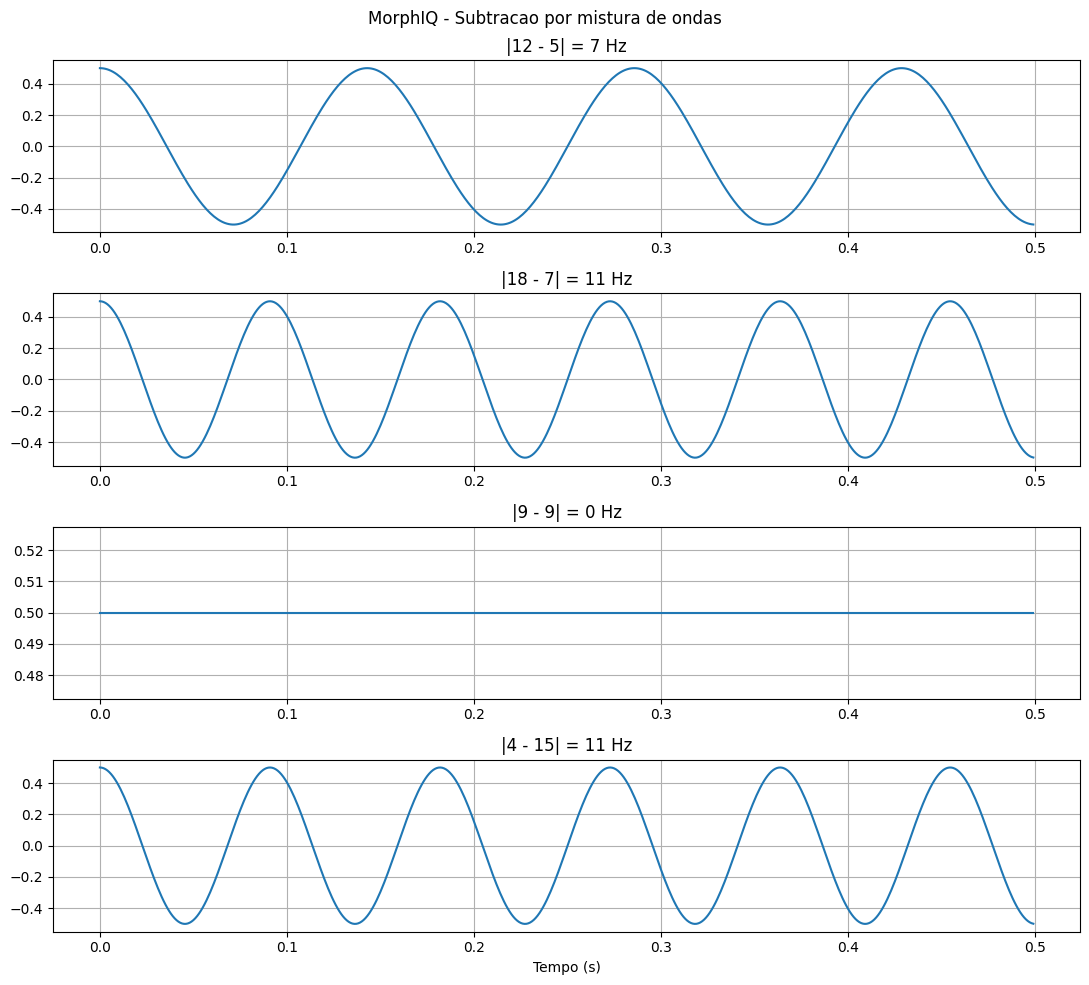

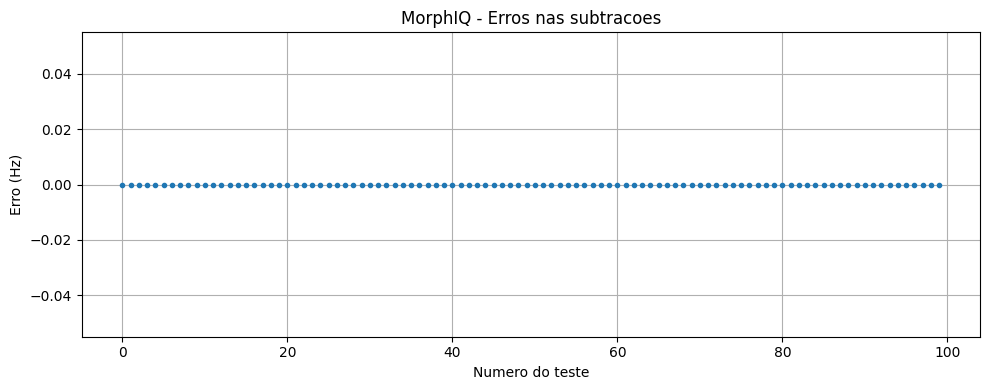

In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 26
# SUBTRACAO POR MISTURA DE ONDAS
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
duracao = 2
t = np.arange(0, duracao, 1/fs)
N = len(t)

freqs = np.fft.rfftfreq(N, 1/fs)

def subtracao_por_ondas(a, b):

    onda_a = np.sin(2*np.pi*a*t)
    onda_b = np.sin(2*np.pi*b*t)

    # Misturador de ondas
    mistura = onda_a * onda_b

    fft = np.fft.rfft(mistura)
    magnitude = np.abs(fft)

    # Identifica componentes significativas
    limiar = 0.20*np.max(magnitude)

    indices = np.where(
        magnitude >= limiar
    )[0]

    # Seleciona menor frequencia
    indice = indices[np.argmin(freqs[indices])]

    resultado = freqs[indice]

    # Isola a componente de diferenca
    fft_filtrada = np.zeros_like(fft)
    fft_filtrada[indice] = fft[indice]

    onda_resultado = np.fft.irfft(
        fft_filtrada, n=N
    )

    return resultado, onda_resultado

# Testes aleatorios
total = 100
acertos = 0
erros = []

for _ in range(total):

    a = int(rng.integers(1, 21))
    b = int(rng.integers(1, 21))

    resultado, onda = subtracao_por_ondas(a, b)

    # Diferenca absoluta de frequencias
    esperado = abs(a-b)

    erro = abs(resultado-esperado)
    erros.append(erro)

    if erro < 0.01:
        acertos += 1

print("MORPHIQ - EXPERIMENTO 26")
print("-------------------------------")
print("Total de testes:", total)
print("Acertos:", acertos)
print(
    "Taxa de recuperacao:",
    100*acertos/total, "%"
)
print("Erro medio:", np.mean(erros), "Hz")
print("Erro maximo:", np.max(erros), "Hz")

# Exemplos
exemplos = [(12, 5), (18, 7), (9, 9), (4, 15)]

fig, axs = plt.subplots(
    len(exemplos), 1,
    figsize=(11, 10)
)

for i, (a, b) in enumerate(exemplos):

    resultado, onda = subtracao_por_ondas(a, b)

    trecho = t < 0.5

    axs[i].plot(t[trecho], onda[trecho])

    axs[i].set_title(
        f"|{a} - {b}| = {resultado:.0f} Hz"
    )
    axs[i].grid(True)

axs[-1].set_xlabel("Tempo (s)")
plt.suptitle(
    "MorphIQ - Subtracao por mistura de ondas"
)
plt.tight_layout()
plt.show()

# Erros
plt.figure(figsize=(10, 4))
plt.plot(erros, marker=".", linestyle="none")
plt.xlabel("Numero do teste")
plt.ylabel("Erro (Hz)")
plt.title("MorphIQ - Erros nas subtracoes")
plt.grid(True)
plt.tight_layout()
plt.show()

MORPHIQ - EXPERIMENTO 27
-----------------------------
Total de testes: 100
Acertos: 100
Taxa de recuperacao: 100.0 %
Erro medio: 0.0 Hz
Erro maximo: 0.0 Hz


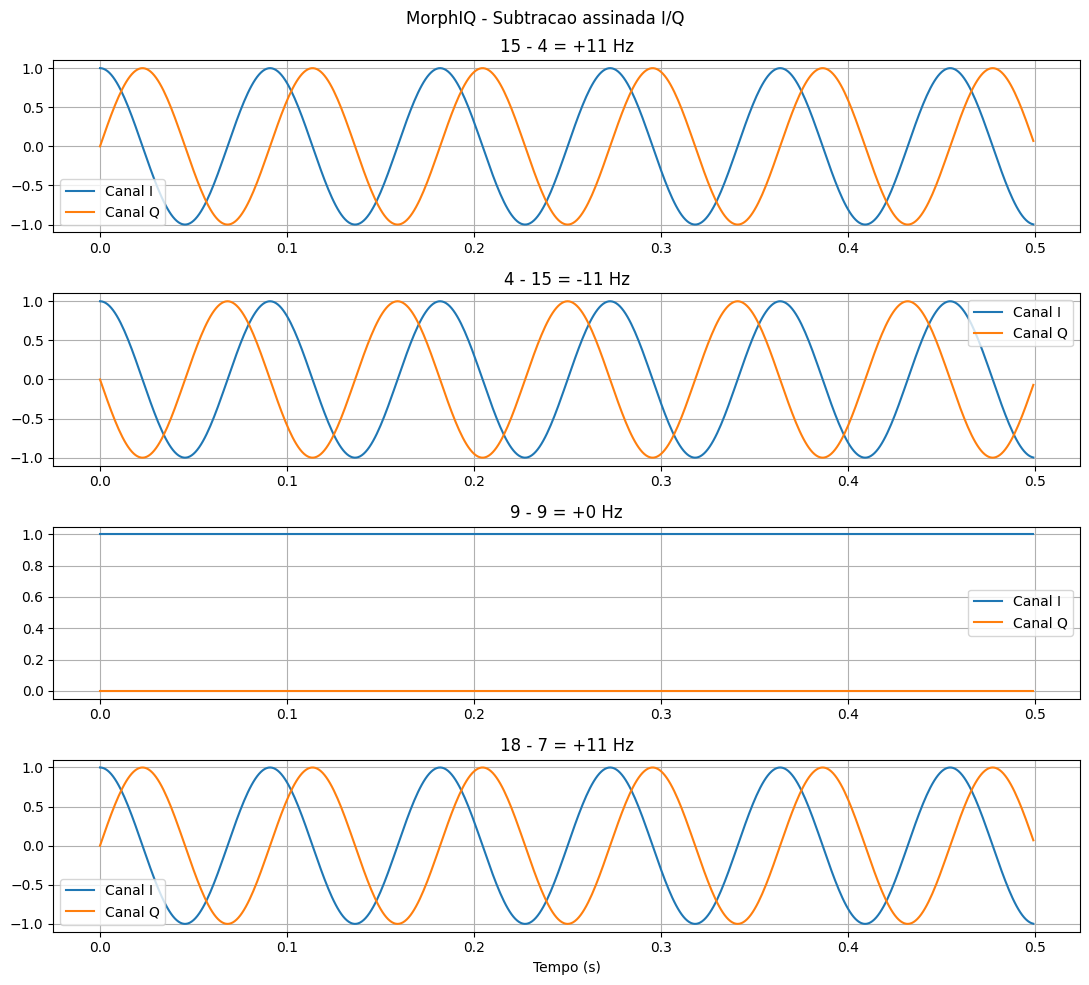

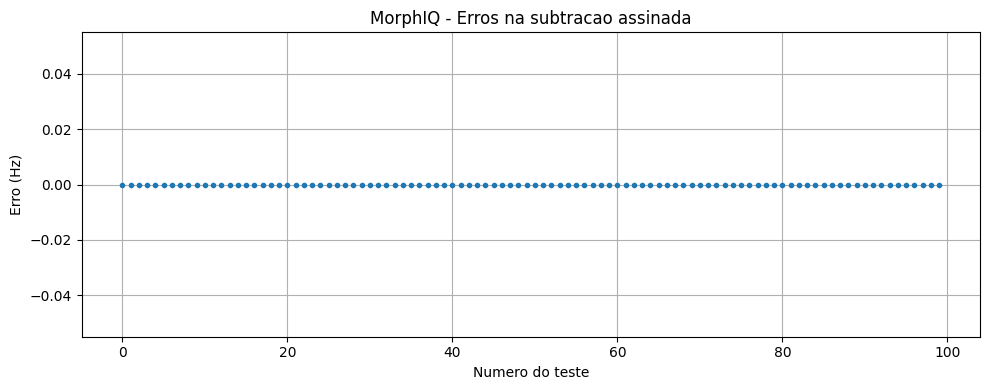

In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 27
# SUBTRACAO COM SINAL POR ONDAS I/Q
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
duracao = 2
t = np.arange(0, duracao, 1/fs)
N = len(t)

freqs = np.fft.fftfreq(N, 1/fs)

def subtracao_iq(a, b):

    # Ondas complexas em quadratura
    onda_a = np.exp(1j*2*np.pi*a*t)
    onda_b = np.exp(1j*2*np.pi*b*t)

    # Mistura com conjugacao
    # Produz frequencia assinada a-b
    mistura = onda_a * np.conj(onda_b)

    # Espectro bilateral
    espectro = np.abs(np.fft.fft(mistura))

    indice = np.argmax(espectro)
    resultado = freqs[indice]

    return resultado, mistura

# Testes aleatorios
total = 100
acertos = 0
erros = []

for _ in range(total):

    a = int(rng.integers(1, 21))
    b = int(rng.integers(1, 21))

    resultado, onda = subtracao_iq(a, b)
    esperado = a - b

    erro = abs(resultado - esperado)
    erros.append(erro)

    if erro < 0.01:
        acertos += 1

print("MORPHIQ - EXPERIMENTO 27")
print("-----------------------------")
print("Total de testes:", total)
print("Acertos:", acertos)
print(
    "Taxa de recuperacao:",
    100*acertos/total, "%"
)
print("Erro medio:", np.mean(erros), "Hz")
print("Erro maximo:", np.max(erros), "Hz")

# Demonstracao de sinais positivos e negativos
exemplos = [
    (15, 4),
    (4, 15),
    (9, 9),
    (18, 7)
]

fig, axs = plt.subplots(
    len(exemplos), 1,
    figsize=(11, 10)
)

for i, (a, b) in enumerate(exemplos):

    resultado, onda = subtracao_iq(a, b)

    trecho = t < 0.5

    axs[i].plot(
        t[trecho],
        np.real(onda[trecho]),
        label="Canal I"
    )

    axs[i].plot(
        t[trecho],
        np.imag(onda[trecho]),
        label="Canal Q"
    )

    axs[i].set_title(
        f"{a} - {b} = {resultado:+.0f} Hz"
    )
    axs[i].legend()
    axs[i].grid(True)

axs[-1].set_xlabel("Tempo (s)")

plt.suptitle(
    "MorphIQ - Subtracao assinada I/Q"
)
plt.tight_layout()
plt.show()

# Erros
plt.figure(figsize=(10, 4))
plt.plot(erros, marker=".", linestyle="none")
plt.xlabel("Numero do teste")
plt.ylabel("Erro (Hz)")
plt.title("MorphIQ - Erros na subtracao assinada")
plt.grid(True)
plt.tight_layout()
plt.show()

Ideal: 100.0% | Erro medio: 0.000 Hz
Ruido leve: 100.0% | Erro medio: 0.000 Hz
Ruido forte: 100.0% | Erro medio: 0.000 Hz
Erro de fase: 100.0% | Erro medio: 0.000 Hz
Desvio 0.25 Hz: 100.0% | Erro medio: 0.112 Hz
Desvio 0.75 Hz: 75.7% | Erro medio: 0.480 Hz


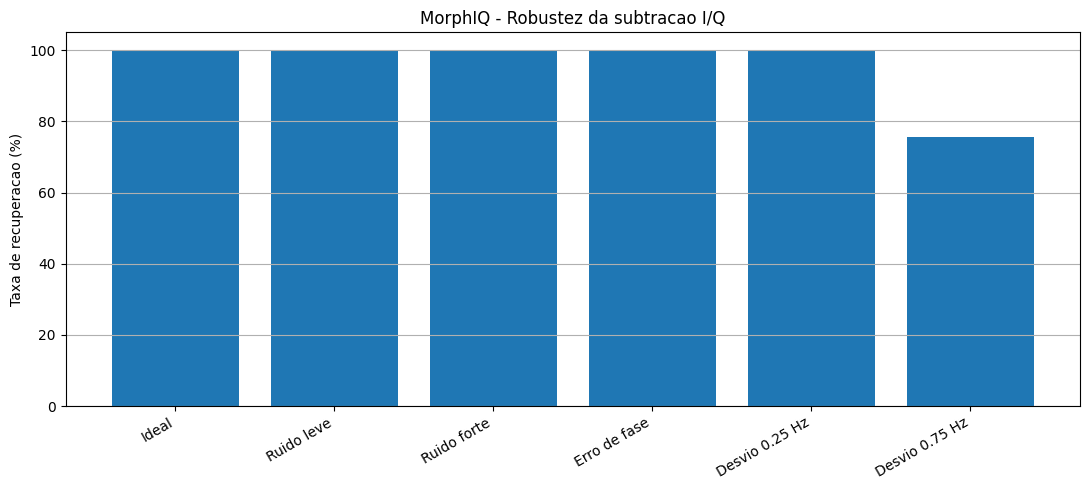


MORPHIQ - EXPERIMENTO 28
Total de testes: 1800


In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 28
# ROBUSTEZ DA SUBTRACAO I/Q
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
duracao = 2
t = np.arange(0, duracao, 1/fs)
N = len(t)

freqs = np.fft.fftfreq(N, 1/fs)

cenarios = {
    "Ideal": (0, 0, 0),
    "Ruido leve": (0.2, 0, 0),
    "Ruido forte": (1.0, 0, 0),
    "Erro de fase": (0.2, np.pi/2, 0),
    "Desvio 0.25 Hz": (0.2, 0, 0.25),
    "Desvio 0.75 Hz": (0.2, 0, 0.75)
}

testes = 300
resultados = {}

def gerar_sinal(f, fase, ruido):
    onda = np.exp(
        1j*(2*np.pi*f*t + fase)
    )

    ruido_complexo = (
        rng.normal(0, ruido, N)
        + 1j*rng.normal(0, ruido, N)
    )

    return onda + ruido_complexo

def decodificar_diferenca(a, b, ruido, fase, desvio):

    d_a = rng.uniform(-desvio, desvio)
    d_b = rng.uniform(-desvio, desvio)

    onda_a = gerar_sinal(
        a+d_a, fase, ruido
    )

    onda_b = gerar_sinal(
        b+d_b, 0, ruido
    )

    mistura = onda_a*np.conj(onda_b)

    espectro = np.abs(
        np.fft.fft(mistura)
    )

    indice = np.argmax(espectro)
    return freqs[indice]

for nome, (ruido, fase, desvio) in cenarios.items():

    acertos = 0
    erros = []

    for _ in range(testes):

        a = int(rng.integers(1, 21))
        b = int(rng.integers(1, 21))

        resultado = decodificar_diferenca(
            a, b, ruido, fase, desvio
        )

        esperado = a-b
        erro = abs(resultado-esperado)

        erros.append(erro)

        if erro < 0.51:
            acertos += 1

    taxa = 100*acertos/testes
    resultados[nome] = taxa

    print(
        f"{nome}: {taxa:.1f}% "
        f"| Erro medio: {np.mean(erros):.3f} Hz"
    )

plt.figure(figsize=(11, 5))
plt.bar(resultados.keys(), resultados.values())
plt.xticks(rotation=30, ha="right")
plt.ylabel("Taxa de recuperacao (%)")
plt.title(
    "MorphIQ - Robustez da subtracao I/Q"
)
plt.ylim(0, 105)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 28")
print("Total de testes:",
      len(cenarios)*testes)

Desvio +/-0.00 Hz | FFT: 100.0% | Fase: 23.7%
Desvio +/-0.10 Hz | FFT: 73.7% | Fase: 16.7%
Desvio +/-0.25 Hz | FFT: 40.3% | Fase: 21.0%
Desvio +/-0.50 Hz | FFT: 35.0% | Fase: 20.3%
Desvio +/-0.75 Hz | FFT: 44.0% | Fase: 18.3%
Desvio +/-1.00 Hz | FFT: 36.7% | Fase: 15.3%


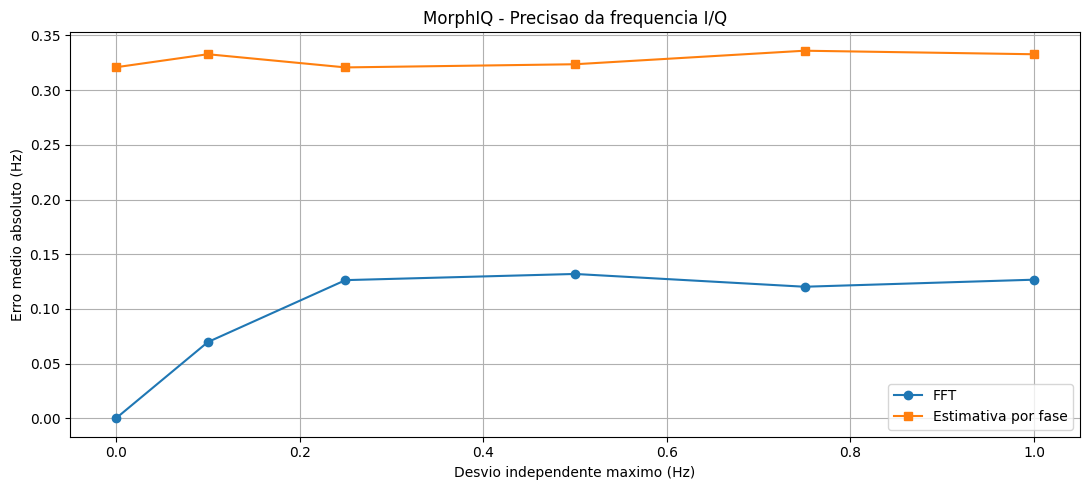

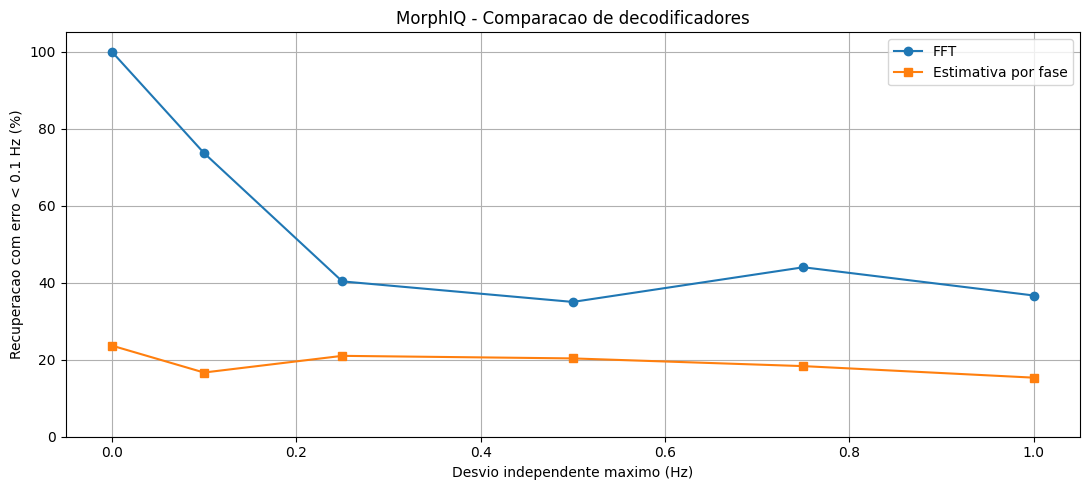


MORPHIQ - EXPERIMENTO 29
Total de testes: 1800
Erros medios FFT: [np.float64(0.0), np.float64(0.06967329373879094), np.float64(0.1263362107638819), np.float64(0.13197606325589187), np.float64(0.12029378471654653), np.float64(0.12673898319191357)]
Erros medios fase: [np.float64(0.3209152973091568), np.float64(0.332828023311068), np.float64(0.32077618071382424), np.float64(0.32366599370849514), np.float64(0.33603662250384336), np.float64(0.3328001502710832)]


In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 29
# FFT VERSUS ESTIMATIVA POR FASE I/Q
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
duracao = 2
t = np.arange(0, duracao, 1/fs)
N = len(t)

freqs = np.fft.fftfreq(N, 1/fs)

desvios = [0, 0.1, 0.25, 0.5, 0.75, 1.0]
testes = 300

def gerar_onda(f, ruido=0.2):
    sinal = np.exp(1j*2*np.pi*f*t)

    perturbacao = (
        rng.normal(0, ruido, N)
        + 1j*rng.normal(0, ruido, N)
    )

    return sinal + perturbacao

def decoder_fft(sinal):
    espectro = np.abs(np.fft.fft(sinal))
    indice = np.argmax(espectro)
    return freqs[indice]

def decoder_fase(sinal):
    # Estima frequencia pela variacao
    # de fase entre amostras consecutivas
    produtos = sinal[1:] * np.conj(sinal[:-1])

    fase_media = np.angle(np.sum(produtos))

    return fase_media * fs / (2*np.pi)

taxas_fft = []
taxas_fase = []
erros_fft = []
erros_fase = []

for limite in desvios:

    acertos_fft = 0
    acertos_fase = 0

    lista_fft = []
    lista_fase = []

    for _ in range(testes):

        a = int(rng.integers(1, 21))
        b = int(rng.integers(1, 21))

        d_a = rng.uniform(-limite, limite)
        d_b = rng.uniform(-limite, limite)

        onda_a = gerar_onda(a+d_a)
        onda_b = gerar_onda(b+d_b)

        mistura = onda_a*np.conj(onda_b)

        esperado = (a+d_a)-(b+d_b)

        resultado_fft = decoder_fft(mistura)
        resultado_fase = decoder_fase(mistura)

        erro_fft = abs(resultado_fft-esperado)
        erro_fase = abs(resultado_fase-esperado)

        lista_fft.append(erro_fft)
        lista_fase.append(erro_fase)

        if erro_fft < 0.1:
            acertos_fft += 1

        if erro_fase < 0.1:
            acertos_fase += 1

    taxas_fft.append(100*acertos_fft/testes)
    taxas_fase.append(100*acertos_fase/testes)

    erros_fft.append(np.mean(lista_fft))
    erros_fase.append(np.mean(lista_fase))

    print(
        f"Desvio +/-{limite:.2f} Hz | "
        f"FFT: {taxas_fft[-1]:.1f}% | "
        f"Fase: {taxas_fase[-1]:.1f}%"
    )

# GRAFICO 1 - PRECISAO
plt.figure(figsize=(11, 5))
plt.plot(
    desvios, erros_fft,
    marker="o", label="FFT"
)
plt.plot(
    desvios, erros_fase,
    marker="s", label="Estimativa por fase"
)
plt.xlabel("Desvio independente maximo (Hz)")
plt.ylabel("Erro medio absoluto (Hz)")
plt.title("MorphIQ - Precisao da frequencia I/Q")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# GRAFICO 2 - TAXA DE ACERTOS
plt.figure(figsize=(11, 5))
plt.plot(
    desvios, taxas_fft,
    marker="o", label="FFT"
)
plt.plot(
    desvios, taxas_fase,
    marker="s", label="Estimativa por fase"
)
plt.xlabel("Desvio independente maximo (Hz)")
plt.ylabel("Recuperacao com erro < 0.1 Hz (%)")
plt.title("MorphIQ - Comparacao de decodificadores")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 29")
print("Total de testes:", len(desvios)*testes)
print("Erros medios FFT:", erros_fft)
print("Erros medios fase:", erros_fase)


Desvio +/-0.00 Hz
FFT: 100.0% | Erro medio: 0.0000 Hz
Fase atraso 1: 23.7% | Erro medio: 0.3209 Hz
Fase atraso 10: 97.3% | Erro medio: 0.0368 Hz

Desvio +/-0.10 Hz
FFT: 73.7% | Erro medio: 0.0697 Hz
Fase atraso 1: 16.7% | Erro medio: 0.3328 Hz
Fase atraso 10: 99.0% | Erro medio: 0.0325 Hz

Desvio +/-0.25 Hz
FFT: 40.3% | Erro medio: 0.1263 Hz
Fase atraso 1: 21.0% | Erro medio: 0.3208 Hz
Fase atraso 10: 99.0% | Erro medio: 0.0356 Hz

Desvio +/-0.50 Hz
FFT: 35.0% | Erro medio: 0.1320 Hz
Fase atraso 1: 20.3% | Erro medio: 0.3237 Hz
Fase atraso 10: 98.0% | Erro medio: 0.0354 Hz

Desvio +/-0.75 Hz
FFT: 44.0% | Erro medio: 0.1203 Hz
Fase atraso 1: 18.3% | Erro medio: 0.3360 Hz
Fase atraso 10: 97.7% | Erro medio: 0.0346 Hz

Desvio +/-1.00 Hz
FFT: 36.7% | Erro medio: 0.1267 Hz
Fase atraso 1: 15.3% | Erro medio: 0.3328 Hz
Fase atraso 10: 98.7% | Erro medio: 0.0330 Hz


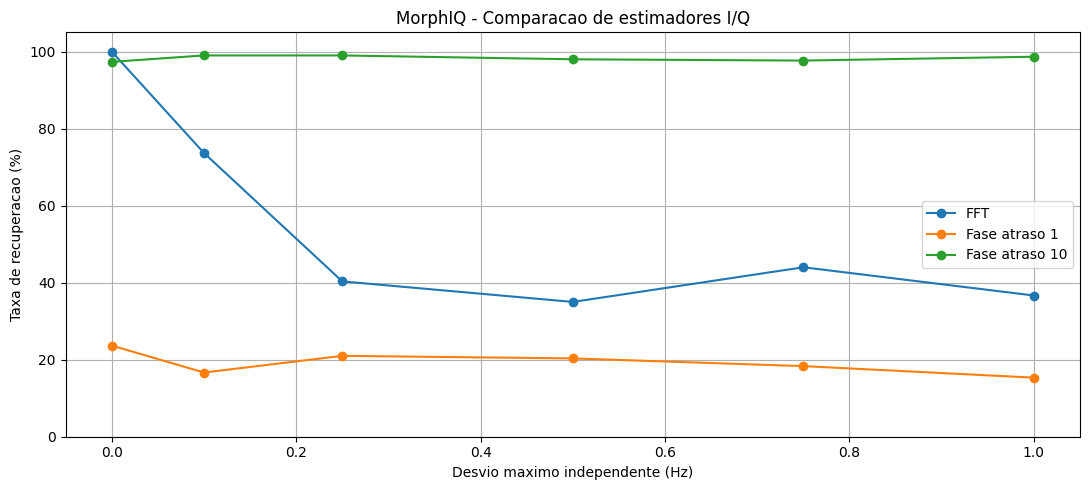

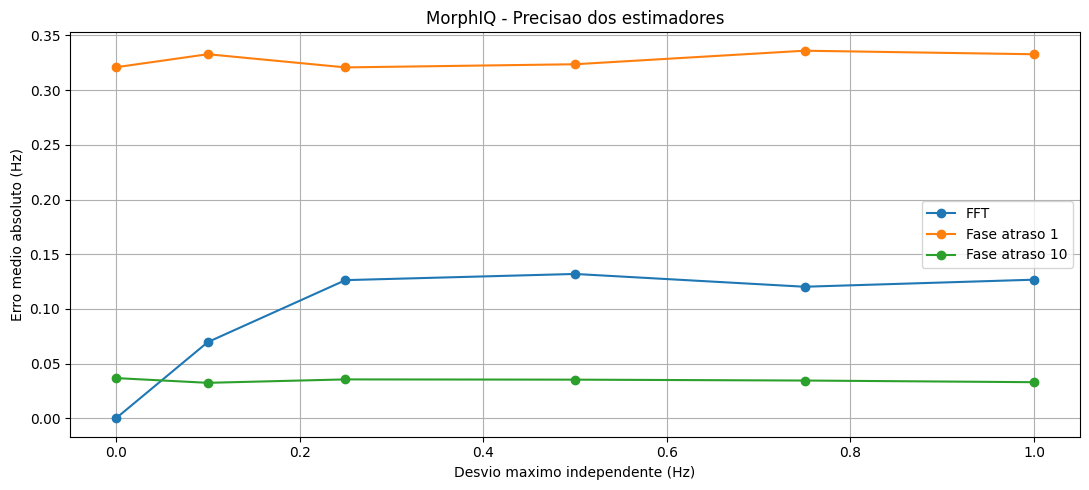


MORPHIQ - EXPERIMENTO 30
Total de testes: 1800


In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 30
# OTIMIZACAO DA ESTIMATIVA DE FASE I/Q
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
duracao = 2
t = np.arange(0, duracao, 1/fs)
N = len(t)

freqs = np.fft.fftfreq(N, 1/fs)

desvios = [0, 0.1, 0.25, 0.5, 0.75, 1.0]
testes = 300

def gerar_onda(f, ruido=0.2):
    sinal = np.exp(1j*2*np.pi*f*t)

    perturbacao = (
        rng.normal(0, ruido, N)
        + 1j*rng.normal(0, ruido, N)
    )

    return sinal + perturbacao

def decoder_fft(sinal):
    espectro = np.abs(np.fft.fft(sinal))
    indice = np.argmax(espectro)
    return freqs[indice]

def decoder_fase(sinal, atraso=1):
    produtos = (
        sinal[atraso:]
        * np.conj(sinal[:-atraso])
    )

    fase_media = np.angle(np.sum(produtos))

    return (
        fase_media*fs
        /(2*np.pi*atraso)
    )

resultados = {
    "FFT": [],
    "Fase atraso 1": [],
    "Fase atraso 10": []
}

erros_medios = {
    chave: [] for chave in resultados
}

for limite in desvios:

    acertos = {chave: 0 for chave in resultados}
    erros = {chave: [] for chave in resultados}

    for _ in range(testes):

        a = int(rng.integers(1, 21))
        b = int(rng.integers(1, 21))

        d_a = rng.uniform(-limite, limite)
        d_b = rng.uniform(-limite, limite)

        onda_a = gerar_onda(a+d_a)
        onda_b = gerar_onda(b+d_b)

        mistura = onda_a*np.conj(onda_b)

        esperado = (a+d_a)-(b+d_b)

        estimativas = {
            "FFT": decoder_fft(mistura),
            "Fase atraso 1": decoder_fase(
                mistura, 1
            ),
            "Fase atraso 10": decoder_fase(
                mistura, 10
            )
        }

        for nome, estimado in estimativas.items():

            erro = abs(estimado-esperado)
            erros[nome].append(erro)

            if erro < 0.1:
                acertos[nome] += 1

    for nome in resultados:
        resultados[nome].append(
            100*acertos[nome]/testes
        )
        erros_medios[nome].append(
            np.mean(erros[nome])
        )

    print(f"\nDesvio +/-{limite:.2f} Hz")

    for nome in resultados:
        print(
            f"{nome}: "
            f"{resultados[nome][-1]:.1f}% "
            f"| Erro medio: "
            f"{erros_medios[nome][-1]:.4f} Hz"
        )

# GRAFICO 1
plt.figure(figsize=(11, 5))

for nome, taxas in resultados.items():
    plt.plot(
        desvios, taxas,
        marker="o", label=nome
    )

plt.xlabel("Desvio maximo independente (Hz)")
plt.ylabel("Taxa de recuperacao (%)")
plt.title("MorphIQ - Comparacao de estimadores I/Q")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# GRAFICO 2
plt.figure(figsize=(11, 5))

for nome, erros in erros_medios.items():
    plt.plot(
        desvios, erros,
        marker="o", label=nome
    )

plt.xlabel("Desvio maximo independente (Hz)")
plt.ylabel("Erro medio absoluto (Hz)")
plt.title("MorphIQ - Precisao dos estimadores")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 30")
print("Total de testes:", len(desvios)*testes)

MORPHIQ - EXPERIMENTO 31
--------------------------------

Operacao: ADD
Acertos: 300
Taxa: 100.0 %
Erro medio: 0.0172 Hz

Operacao: SUB
Acertos: 300
Taxa: 100.0 %
Erro medio: 0.0166 Hz

EXEMPLOS DE EXECUCAO
ADD(18,4) | Esperado: +22 | Medido: +21.985 Hz
ADD(20,4) | Esperado: +24 | Medido: +23.977 Hz
ADD(9,6) | Esperado: +15 | Medido: +15.004 Hz
ADD(13,6) | Esperado: +19 | Medido: +18.975 Hz
SUB(18,4) | Esperado: +14 | Medido: +13.987 Hz
SUB(19,10) | Esperado: +9 | Medido: +9.005 Hz
SUB(5,4) | Esperado: +1 | Medido: +0.996 Hz
SUB(13,8) | Esperado: +5 | Medido: +4.996 Hz


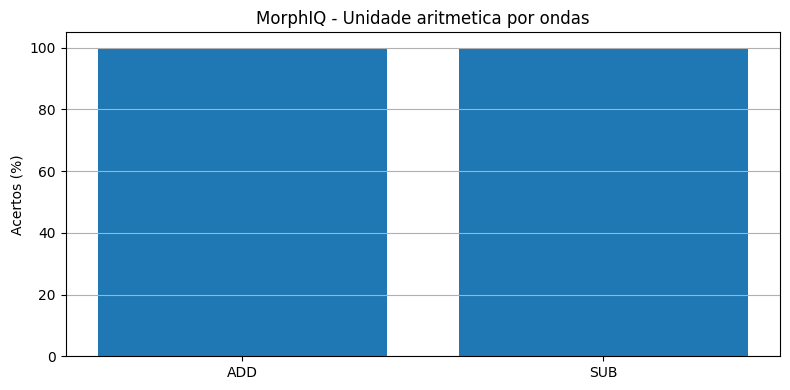

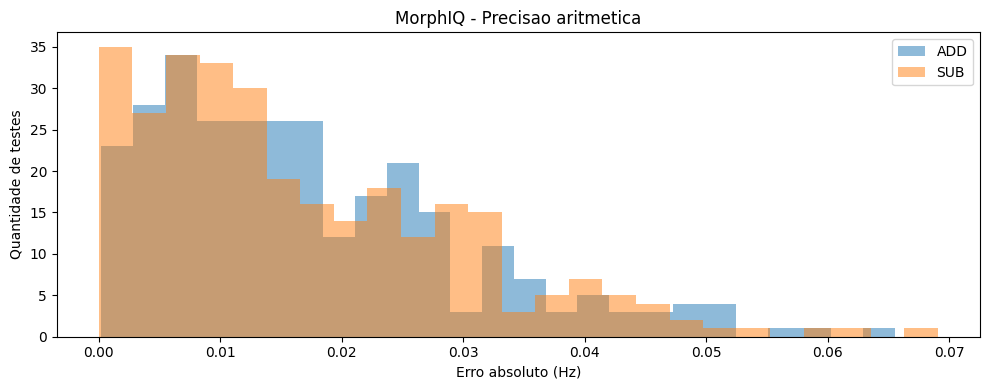


Total de operacoes testadas: 600


In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 31
# UNIDADE ARITMETICA EXPERIMENTAL POR ONDAS
# SOMA E SUBTRACAO I/Q
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 2000
t = np.arange(N) / fs

testes = 300
atraso = 10

def gerar_onda(valor):
    return np.exp(1j * 2*np.pi*valor*t)

def unidade_morphiq(onda_a, onda_b, comando):

    if comando == "ADD":
        # Mistura que gera frequencia soma
        return onda_a * onda_b

    elif comando == "SUB":
        # Mistura que gera diferenca assinada
        return onda_a * np.conj(onda_b)

    else:
        raise ValueError("Comando desconhecido")

def estimar_frequencia(sinal):
    produtos = (
        sinal[atraso:]
        * np.conj(sinal[:-atraso])
    )

    fase = np.angle(np.sum(produtos))

    return fase * fs / (2*np.pi*atraso)

acertos = {"ADD": 0, "SUB": 0}
erros = {"ADD": [], "SUB": []}
exemplos = []

for comando in ["ADD", "SUB"]:

    for i in range(testes):

        a = int(rng.integers(1, 21))
        b = int(rng.integers(1, 21))

        onda_a = gerar_onda(a)
        onda_b = gerar_onda(b)

        resultado_onda = unidade_morphiq(
            onda_a, onda_b, comando
        )

        # Ruido aplicado na saida da unidade
        ruido = 0.2 * (
            rng.normal(size=N)
            + 1j*rng.normal(size=N)
        )

        sinal_recebido = resultado_onda + ruido

        frequencia = estimar_frequencia(
            sinal_recebido
        )

        # Referencia para verificar o teste
        esperado = (
            a+b if comando == "ADD"
            else a-b
        )

        erro = abs(frequencia-esperado)
        erros[comando].append(erro)

        # Criterio: resultado inteiro correto
        recuperado = int(np.rint(frequencia))

        if recuperado == esperado:
            acertos[comando] += 1

        if i < 4:
            exemplos.append(
                (comando, a, b, esperado,
                 frequencia)
            )

print("MORPHIQ - EXPERIMENTO 31")
print("--------------------------------")

for comando in ["ADD", "SUB"]:
    taxa = 100*acertos[comando]/testes

    print(f"\nOperacao: {comando}")
    print("Acertos:", acertos[comando])
    print("Taxa:", round(taxa, 2), "%")
    print(
        "Erro medio:",
        round(np.mean(erros[comando]), 4),
        "Hz"
    )

print("\nEXEMPLOS DE EXECUCAO")

for comando, a, b, esperado, freq in exemplos:
    print(
        f"{comando}({a},{b}) "
        f"| Esperado: {esperado:+d} "
        f"| Medido: {freq:+.3f} Hz"
    )

# GRAFICO DE ACERTOS
taxas = [
    100*acertos[c]/testes
    for c in ["ADD", "SUB"]
]

plt.figure(figsize=(8, 4))
plt.bar(["ADD", "SUB"], taxas)
plt.ylim(0, 105)
plt.ylabel("Acertos (%)")
plt.title(
    "MorphIQ - Unidade aritmetica por ondas"
)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# GRAFICO DE ERROS
plt.figure(figsize=(10, 4))

for comando in ["ADD", "SUB"]:
    plt.hist(
        erros[comando],
        bins=25,
        alpha=0.5,
        label=comando
    )

plt.xlabel("Erro absoluto (Hz)")
plt.ylabel("Quantidade de testes")
plt.title("MorphIQ - Precisao aritmetica")
plt.legend()
plt.tight_layout()
plt.show()

print("\nTotal de operacoes testadas:",
      2*testes)

MORPHIQ - EXPERIMENTO 32
--------------------------------

Comando: ADD
Acertos: 300
Taxa: 100.0 %
Erro medio: 0.1407 Hz

Comando: SUB
Acertos: 300
Taxa: 100.0 %
Erro medio: 0.1286 Hz

Total de testes: 600
Falhas: 0


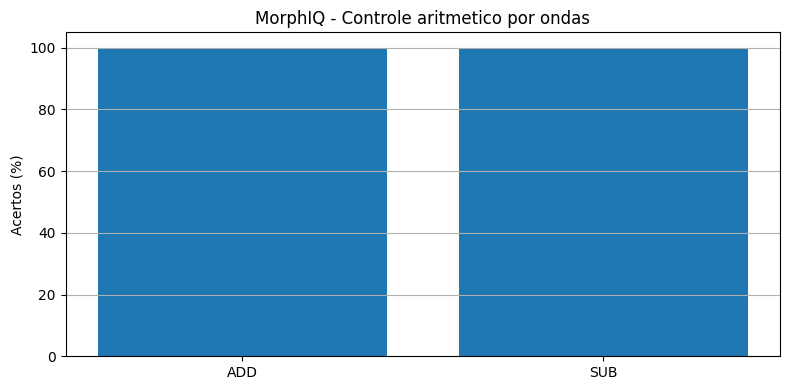

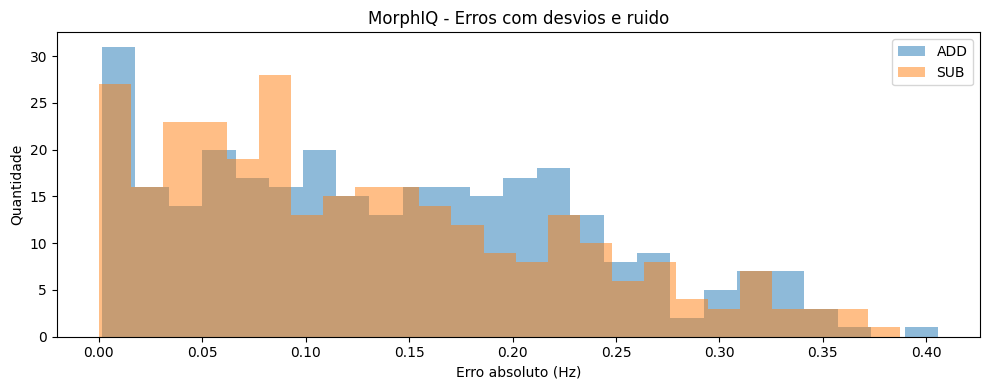

In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 32
# UNIDADE ARITMETICA COM COMANDO POR ONDA
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 2000
t = np.arange(N) / fs
atraso = 10
testes = 300

comandos = {"ADD": 4, "SUB": 8}

def onda_iq(f):
    return np.exp(1j * 2*np.pi*f*t)

def onda_comando(comando):
    return np.sin(
        2*np.pi*comandos[comando]*t
    )

def ler_comando(sinal):
    espectro = np.abs(np.fft.rfft(sinal))
    freqs = np.fft.rfftfreq(N, 1/fs)

    energias = {
        nome: espectro[np.argmin(
            abs(freqs-f)
        )]
        for nome, f in comandos.items()
    }

    return max(energias, key=energias.get)

def executar(onda_a, onda_b, comando):
    if comando == "ADD":
        return onda_a * onda_b
    return onda_a * np.conj(onda_b)

def medir_frequencia(sinal):
    produtos = (
        sinal[atraso:]
        * np.conj(sinal[:-atraso])
    )
    fase = np.angle(np.sum(produtos))
    return fase*fs/(2*np.pi*atraso)

acertos = {"ADD": 0, "SUB": 0}
erros = {"ADD": [], "SUB": []}
falhas = []

for comando_original in comandos:

    for _ in range(testes):
        a = int(rng.integers(-15, 16))
        b = int(rng.integers(-15, 16))

        # Pequenos desvios independentes
        da = rng.uniform(-0.2, 0.2)
        db = rng.uniform(-0.2, 0.2)

        entrada_a = onda_iq(a+da)
        entrada_b = onda_iq(b+db)

        controle = onda_comando(
            comando_original
        )

        # Ruido na onda de controle
        controle += rng.normal(
            0, 0.2, N
        )

        comando_lido = ler_comando(controle)

        saida = executar(
            entrada_a, entrada_b,
            comando_lido
        )

        # Ruido na saida aritmetica
        saida += 0.2 * (
            rng.normal(size=N)
            + 1j*rng.normal(size=N)
        )

        medido = medir_frequencia(saida)

        esperado = (
            a+b if comando_original == "ADD"
            else a-b
        )

        recuperado = int(np.rint(medido))
        erro = abs(medido-esperado)

        erros[comando_original].append(erro)

        correto = (
            comando_lido == comando_original
            and recuperado == esperado
        )

        if correto:
            acertos[comando_original] += 1
        else:
            falhas.append((
                comando_original,
                comando_lido,
                a, b, esperado, medido
            ))

print("MORPHIQ - EXPERIMENTO 32")
print("--------------------------------")

for comando in comandos:
    taxa = 100*acertos[comando]/testes

    print("\nComando:", comando)
    print("Acertos:", acertos[comando])
    print("Taxa:", round(taxa, 2), "%")
    print(
        "Erro medio:",
        round(np.mean(erros[comando]), 4),
        "Hz"
    )

print("\nTotal de testes:", 2*testes)
print("Falhas:", len(falhas))

if falhas:
    print("Exemplos de falhas:")
    for falha in falhas[:5]:
        print(falha)

plt.figure(figsize=(8, 4))

plt.bar(
    ["ADD", "SUB"],
    [100*acertos[c]/testes for c in comandos]
)

plt.ylim(0, 105)
plt.ylabel("Acertos (%)")
plt.title(
    "MorphIQ - Controle aritmetico por ondas"
)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))

for comando in comandos:
    plt.hist(
        erros[comando],
        bins=25,
        alpha=0.5,
        label=comando
    )

plt.xlabel("Erro absoluto (Hz)")
plt.ylabel("Quantidade")
plt.title(
    "MorphIQ - Erros com desvios e ruido"
)
plt.legend()
plt.tight_layout()
plt.show()

MORPHIQ - EXPERIMENTO 33
--------------------------------
Programas: 100
Instrucoes: 800
Acertos por instrucao: 800
Taxa por instrucao: 100.0 %
Programas inteiramente corretos: 100
Taxa de programas: 100.0 %
Erro medio final: 0.0162 Hz

EXEMPLO DE PROGRAMA
Inicio: 7
1. ADD 1 | Esperado: 8 | Medido: 8.030
2. SUB 4 | Esperado: 4 | Medido: 4.009
3. ADD 4 | Esperado: 8 | Medido: 8.008
4. ADD 2 | Esperado: 10 | Medido: 9.975
5. SUB 4 | Esperado: 6 | Medido: 6.010
6. SUB 3 | Esperado: 3 | Medido: 3.016
7. ADD 3 | Esperado: 6 | Medido: 6.022
8. SUB 3 | Esperado: 3 | Medido: 3.026


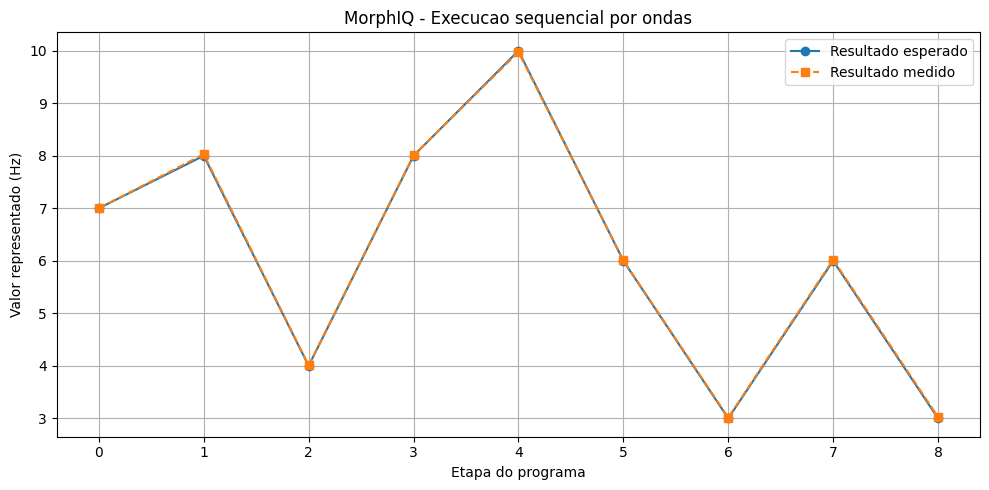

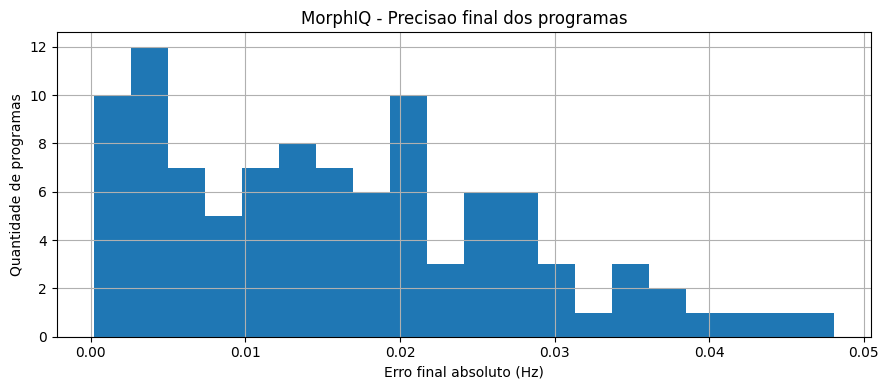

In [ ]:


# ==========================================
# MORPHIQ - EXPERIMENTO 33
# EXECUCAO SEQUENCIAL POR ONDAS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 2000
t = np.arange(N) / fs

programas = 100
instrucoes = 8
atraso = 10

freq_comandos = {"ADD": 4, "SUB": 8}

def onda_iq(f):
    return np.exp(1j*2*np.pi*f*t)

def codificar_comando(op):
    f = freq_comandos[op]
    return (
        np.sin(2*np.pi*f*t)
        + rng.normal(0, 0.2, N)
    )

def decodificar_comando(s):
    fft = np.abs(np.fft.rfft(s))
    freqs = np.fft.rfftfreq(N, 1/fs)

    return max(
        freq_comandos,
        key=lambda op: fft[
            np.argmin(abs(
                freqs-freq_comandos[op]
            ))
        ]
    )

def operar(acc, operando, op):
    if op == "ADD":
        return acc*operando
    elif op == "SUB":
        return acc*np.conj(operando)
    raise ValueError("Comando invalido")

def medir(s):
    p = s[atraso:]*np.conj(s[:-atraso])
    return (
        np.angle(np.sum(p))*fs
        /(2*np.pi*atraso)
    )

acertos_programas = 0
acertos_instrucoes = 0
total_instrucoes = 0
erros_finais = []
exemplo = None

for k in range(programas):

    inicial = int(rng.integers(-10, 11))
    esperado = inicial

    # Estado inicial como onda
    acumulador = onda_iq(inicial)

    historico = [esperado]
    medicoes = [medir(acumulador)]
    programa_correto = True
    passos = []

    for j in range(instrucoes):

        op = str(rng.choice(["ADD", "SUB"]))
        valor = int(rng.integers(1, 6))

        # Comando transmitido como onda
        controle = codificar_comando(op)
        op_lida = decodificar_comando(controle)

        # Operando transmitido como onda
        operando = onda_iq(valor)

        # Executa a operacao diretamente
        # sobre o estado ondulatorio
        acumulador = operar(
            acumulador, operando, op_lida
        )

        # Atualiza apenas a referencia
        # usada para validar o experimento
        if op == "ADD":
            esperado += valor
        else:
            esperado -= valor

        # Medicao com ruido, sem alterar
        # o estado interno do acumulador
        ruido = 0.2*(
            rng.normal(size=N)
            + 1j*rng.normal(size=N)
        )
        medido = medir(acumulador+ruido)

        correto = (
            op_lida == op
            and int(np.rint(medido)) == esperado
        )

        total_instrucoes += 1

        if correto:
            acertos_instrucoes += 1
        else:
            programa_correto = False

        historico.append(esperado)
        medicoes.append(medido)
        passos.append((op, valor))

    if programa_correto:
        acertos_programas += 1

    erros_finais.append(
        abs(medicoes[-1]-esperado)
    )

    if k == 0:
        exemplo = (
            inicial, passos,
            historico, medicoes
        )

print("MORPHIQ - EXPERIMENTO 33")
print("--------------------------------")
print("Programas:", programas)
print("Instrucoes:", total_instrucoes)
print(
    "Acertos por instrucao:",
    acertos_instrucoes
)
print(
    "Taxa por instrucao:",
    round(
        100*acertos_instrucoes/total_instrucoes,
        2
    ), "%"
)
print(
    "Programas inteiramente corretos:",
    acertos_programas
)
print(
    "Taxa de programas:",
    round(
        100*acertos_programas/programas, 2
    ), "%"
)
print(
    "Erro medio final:",
    round(np.mean(erros_finais), 4),
    "Hz"
)

inicial, passos, historico, medicoes = exemplo

print("\nEXEMPLO DE PROGRAMA")
print("Inicio:", inicial)

for i, (op, valor) in enumerate(passos):
    print(
        f"{i+1}. {op} {valor} "
        f"| Esperado: {historico[i+1]} "
        f"| Medido: {medicoes[i+1]:.3f}"
    )

plt.figure(figsize=(10, 5))
plt.plot(
    historico,
    marker="o",
    label="Resultado esperado"
)
plt.plot(
    medicoes,
    marker="s",
    linestyle="--",
    label="Resultado medido"
)
plt.xlabel("Etapa do programa")
plt.ylabel("Valor representado (Hz)")
plt.title(
    "MorphIQ - Execucao sequencial por ondas"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.hist(erros_finais, bins=20)
plt.xlabel("Erro final absoluto (Hz)")
plt.ylabel("Quantidade de programas")
plt.title(
    "MorphIQ - Precisao final dos programas"
)
plt.grid(True)
plt.tight_layout()
plt.show()

Desvio +/-0.00 Hz | Programas: 100.0% | Instrucoes: 100.0% | Erro final: 0.0193 Hz
Desvio +/-0.10 Hz | Programas: 100.0% | Instrucoes: 100.0% | Erro final: 0.1297 Hz
Desvio +/-0.30 Hz | Programas: 48.0% | Instrucoes: 81.1% | Erro final: 0.4254 Hz
Desvio +/-0.60 Hz | Programas: 6.0% | Instrucoes: 59.6% | Erro final: 0.7049 Hz


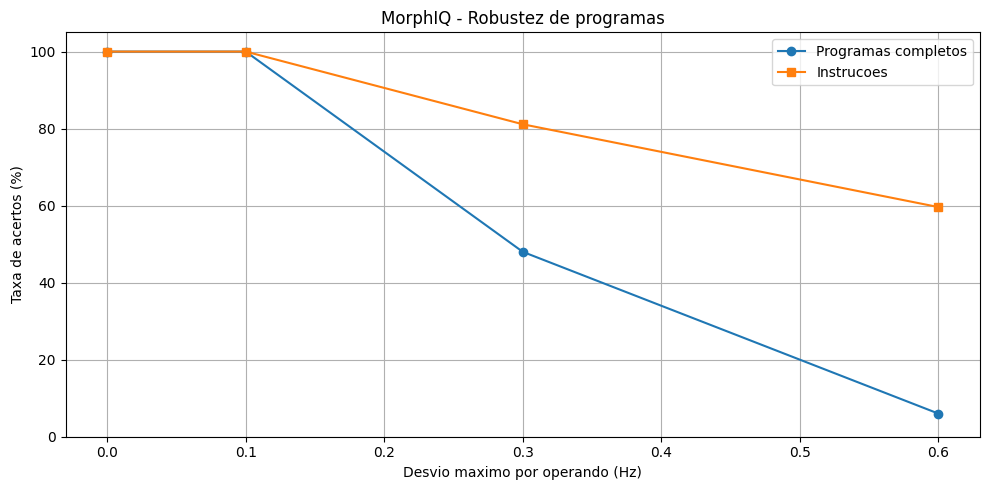

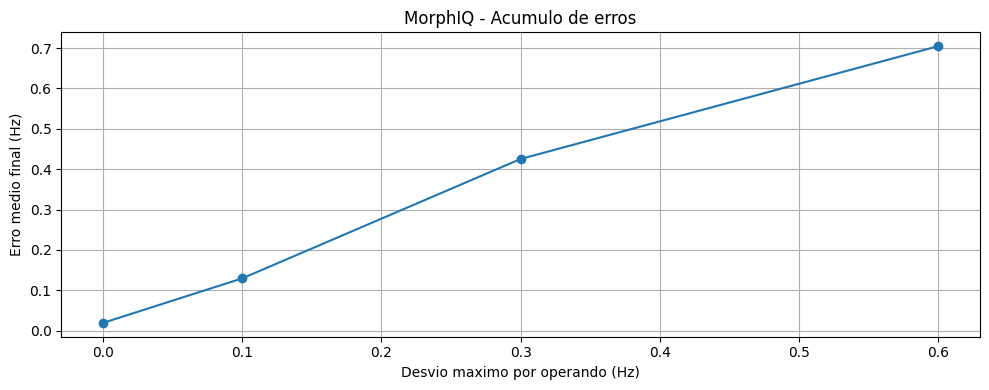


MORPHIQ - EXPERIMENTO 34
Programas testados: 400
Instrucoes executadas: 3200


In [ ]:


# ============================================
# MORPHIQ - EXPERIMENTO 34
# ACUMULO DE ERROS NO ESTADO ONDULATORIO
# ============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

fs = 1000
N = 2000
t = np.arange(N) / fs
atraso = 10

programas = 100
passos = 8
desvios = [0, 0.1, 0.3, 0.6]

def onda(f):
    return np.exp(1j*2*np.pi*f*t)

def medir(s):
    p = s[atraso:] * np.conj(s[:-atraso])
    return np.angle(np.sum(p))*fs/(2*np.pi*atraso)

def ruido_complexo(intensidade):
    return intensidade * (
        rng.normal(size=N)
        + 1j*rng.normal(size=N)
    )

taxas_programas = []
taxas_passos = []
erros_finais = []

for limite in desvios:

    programas_ok = 0
    passos_ok = 0
    erros = []

    for _ in range(programas):

        inicial = int(rng.integers(-5, 6))
        esperado = inicial
        estado = onda(inicial)
        programa_correto = True

        for _ in range(passos):

            op = rng.choice(["ADD", "SUB"])
            valor = int(rng.integers(1, 6))

            # Desvio do oscilador do operando
            delta = rng.uniform(-limite, limite)
            operando = onda(valor + delta)

            if op == "ADD":
                estado = estado * operando
                esperado += valor
            else:
                estado = estado * np.conj(operando)
                esperado -= valor

            # Perturbacao incorporada ao estado
            # e propagada nas etapas seguintes
            estado = estado + ruido_complexo(0.02)

            # Medicao independente, com ruido
            medido = medir(
                estado + ruido_complexo(0.2)
            )

            correto = int(np.rint(medido)) == esperado

            if correto:
                passos_ok += 1
            else:
                programa_correto = False

        if programa_correto:
            programas_ok += 1

        erros.append(abs(medido-esperado))

    taxa_p = 100*programas_ok/programas
    taxa_i = 100*passos_ok/(programas*passos)

    taxas_programas.append(taxa_p)
    taxas_passos.append(taxa_i)
    erros_finais.append(np.mean(erros))

    print(
        f"Desvio +/-{limite:.2f} Hz | "
        f"Programas: {taxa_p:.1f}% | "
        f"Instrucoes: {taxa_i:.1f}% | "
        f"Erro final: {np.mean(erros):.4f} Hz"
    )

plt.figure(figsize=(10, 5))
plt.plot(
    desvios, taxas_programas,
    marker="o", label="Programas completos"
)
plt.plot(
    desvios, taxas_passos,
    marker="s", label="Instrucoes"
)
plt.xlabel("Desvio maximo por operando (Hz)")
plt.ylabel("Taxa de acertos (%)")
plt.title("MorphIQ - Robustez de programas")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(desvios, erros_finais, marker="o")
plt.xlabel("Desvio maximo por operando (Hz)")
plt.ylabel("Erro medio final (Hz)")
plt.title("MorphIQ - Acumulo de erros")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 34")
print("Programas testados:",
      programas*len(desvios))
print("Instrucoes executadas:",
      programas*passos*len(desvios))

Desvio +/-0.00 Hz | Livre: 100.0% | Estabilizado: 100.0%
Desvio +/-0.10 Hz | Livre: 100.0% | Estabilizado: 100.0%
Desvio +/-0.30 Hz | Livre: 53.0% | Estabilizado: 100.0%
Desvio +/-0.60 Hz | Livre: 9.0% | Estabilizado: 34.0%


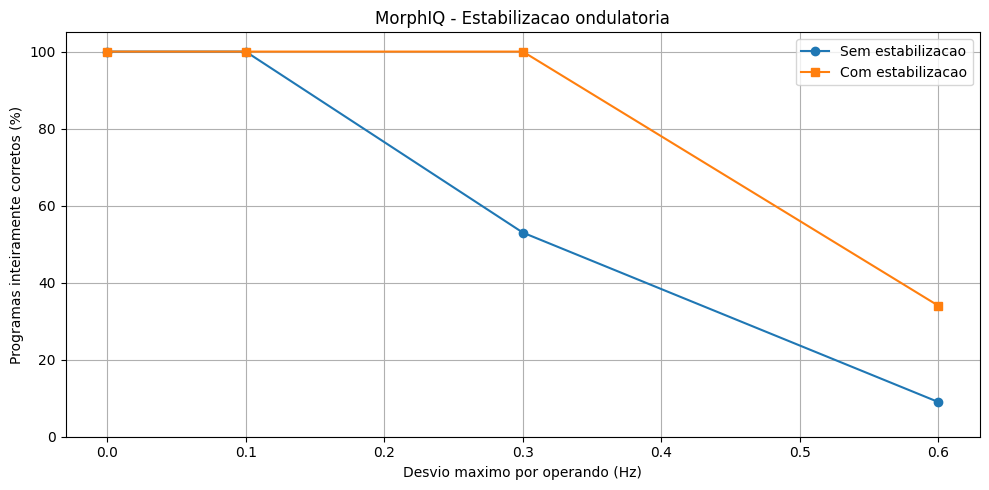

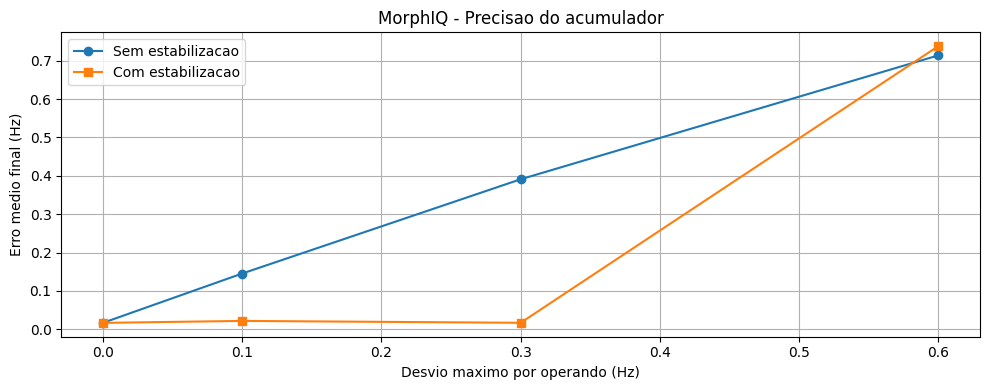


MORPHIQ - EXPERIMENTO 35
Programas por configuracao: 100
Total de execucoes: 800
Total de instrucoes: 6400


In [ ]:


# ==========================================
# MORPHIQ - EXPERIMENTO 35
# ESTABILIZACAO DO ESTADO ONDULATORIO
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2035)

fs = 1000
N = 2000
t = np.arange(N) / fs
atraso = 10

programas = 100
passos = 8
desvios = [0, 0.1, 0.3, 0.6]

def onda(f):
    return np.exp(1j * 2*np.pi*f*t)

def medir(s):
    produto = s[atraso:] * np.conj(s[:-atraso])
    return np.angle(np.sum(produto))*fs/(2*np.pi*atraso)

def ruido(nivel):
    return nivel * (
        rng.normal(size=N)
        + 1j*rng.normal(size=N)
    )

def estabilizar(estado):
    frequencia = medir(estado)
    canal = np.rint(frequencia)

    # Corrige o desvio de frequencia
    # mantendo a fase e a amplitude do estado
    correcao = np.exp(
        -1j*2*np.pi*(frequencia-canal)*t
    )
    return estado * correcao

taxas_livre = []
taxas_estavel = []
erros_livre = []
erros_estavel = []

for limite in desvios:

    corretos_livre = 0
    corretos_estavel = 0
    erros_l = []
    erros_e = []

    for _ in range(programas):

        inicial = int(rng.integers(-5, 6))

        estado_livre = onda(inicial)
        estado_estavel = onda(inicial)

        esperado = inicial
        ok_livre = True
        ok_estavel = True

        for _ in range(passos):

            op = rng.choice(["ADD", "SUB"])
            valor = int(rng.integers(1, 6))
            delta = rng.uniform(-limite, limite)

            operando = onda(valor + delta)

            if op == "ADD":
                estado_livre *= operando
                estado_estavel *= operando
                esperado += valor
            else:
                estado_livre *= np.conj(operando)
                estado_estavel *= np.conj(operando)
                esperado -= valor

            # Ruido incorporado ao estado
            perturbacao = ruido(0.02)

            estado_livre = (
                estado_livre + perturbacao
            )
            estado_estavel = (
                estado_estavel + perturbacao
            )

            # Apenas um dos caminhos
            # recebe estabilizacao
            estado_estavel = estabilizar(
                estado_estavel
            )

            # Mesmo ruido de leitura
            leitura = ruido(0.2)

            med_l = medir(estado_livre + leitura)
            med_e = medir(estado_estavel + leitura)

            if int(np.rint(med_l)) != esperado:
                ok_livre = False

            if int(np.rint(med_e)) != esperado:
                ok_estavel = False

        corretos_livre += int(ok_livre)
        corretos_estavel += int(ok_estavel)

        erros_l.append(abs(med_l-esperado))
        erros_e.append(abs(med_e-esperado))

    taxa_l = 100*corretos_livre/programas
    taxa_e = 100*corretos_estavel/programas

    taxas_livre.append(taxa_l)
    taxas_estavel.append(taxa_e)

    erros_livre.append(np.mean(erros_l))
    erros_estavel.append(np.mean(erros_e))

    print(
        f"Desvio +/-{limite:.2f} Hz | "
        f"Livre: {taxa_l:.1f}% | "
        f"Estabilizado: {taxa_e:.1f}%"
    )

plt.figure(figsize=(10, 5))
plt.plot(
    desvios, taxas_livre,
    "o-", label="Sem estabilizacao"
)
plt.plot(
    desvios, taxas_estavel,
    "s-", label="Com estabilizacao"
)
plt.xlabel("Desvio maximo por operando (Hz)")
plt.ylabel("Programas inteiramente corretos (%)")
plt.title("MorphIQ - Estabilizacao ondulatoria")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(
    desvios, erros_livre,
    "o-", label="Sem estabilizacao"
)
plt.plot(
    desvios, erros_estavel,
    "s-", label="Com estabilizacao"
)
plt.xlabel("Desvio maximo por operando (Hz)")
plt.ylabel("Erro medio final (Hz)")
plt.title("MorphIQ - Precisao do acumulador")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 35")
print("Programas por configuracao:", programas)
print("Total de execucoes:",
      programas*len(desvios)*2)
print("Total de instrucoes:",
      programas*len(desvios)*2*passos)


Desvio +/-0.00 Hz
Livre: 100.0% | Erro final: 0.0021 Hz
Piloto: 100.0% | Erro final: 0.0050 Hz

Desvio +/-0.10 Hz
Livre: 100.0% | Erro final: 0.1221 Hz
Piloto: 100.0% | Erro final: 0.0055 Hz

Desvio +/-0.30 Hz
Livre: 50.0% | Erro final: 0.3600 Hz
Piloto: 100.0% | Erro final: 0.0050 Hz

Desvio +/-0.60 Hz
Livre: 8.0% | Erro final: 0.7205 Hz
Piloto: 100.0% | Erro final: 0.0051 Hz

Desvio +/-1.00 Hz
Livre: 0.0% | Erro final: 1.3842 Hz
Piloto: 100.0% | Erro final: 0.0052 Hz


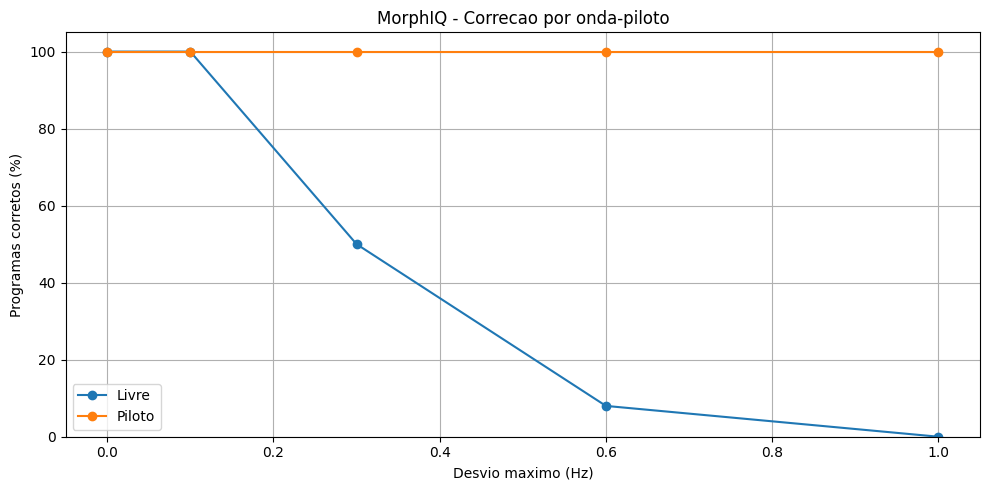

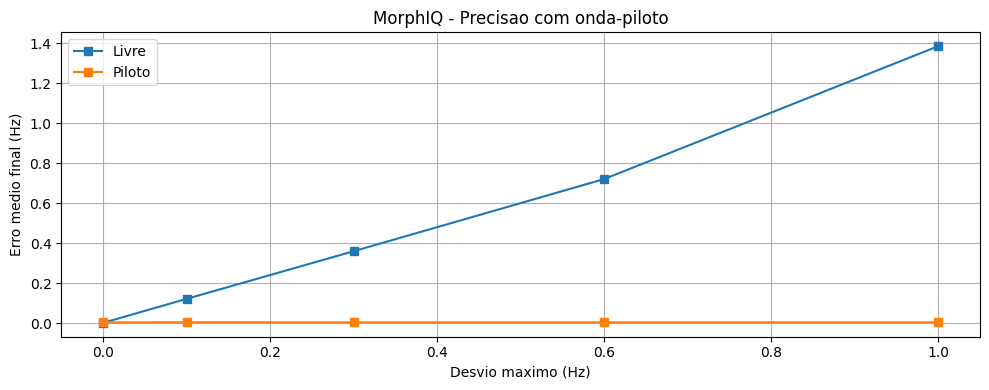


MORPHIQ - EXPERIMENTO 36
Total de programas simulados: 1000
Total de instrucoes: 8000


In [ ]:


# MORPHIQ - EXPERIMENTO 36
# CORRECAO POR ONDA-PILOTO

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2036)

fs = 1000
N = 2000
t = np.arange(N) / fs
atraso = 10

programas = 100
passos = 8
desvios = [0, 0.1, 0.3, 0.6, 1.0]

def onda(f):
    return np.exp(1j*2*np.pi*f*t)

def medir(s):
    p = s[atraso:]*np.conj(s[:-atraso])
    return np.angle(np.sum(p))*fs/(2*np.pi*atraso)

def ruido(nivel):
    return nivel*(rng.normal(size=N)
                  + 1j*rng.normal(size=N))

resultados = {"Livre": [], "Piloto": []}
erros = {"Livre": [], "Piloto": []}

for limite in desvios:
    acertos = {"Livre": 0, "Piloto": 0}
    erros_cenario = {"Livre": [], "Piloto": []}

    for _ in range(programas):
        inicial = int(rng.integers(-5, 6))
        estados = {
            "Livre": onda(inicial),
            "Piloto": onda(inicial)
        }
        esperado = inicial
        correto = {"Livre": True, "Piloto": True}

        for _ in range(passos):
            op = rng.choice(["ADD", "SUB"])
            valor = int(rng.integers(1, 6))
            delta = rng.uniform(-limite, limite)

            # Operando com desvio
            operando = onda(valor + delta)

            # Piloto de 20 Hz no mesmo oscilador
            piloto = onda(20 + delta)
            piloto += ruido(0.05)

            # Estima o desvio sem consultar
            # o resultado esperado
            delta_estimado = medir(piloto) - 20

            # Compensacao de fase
            operando_corrigido = operando * np.exp(
                -1j*2*np.pi*delta_estimado*t
            )

            for metodo in estados:
                entrada = (
                    operando if metodo == "Livre"
                    else operando_corrigido
                )

                if op == "ADD":
                    estados[metodo] *= entrada
                else:
                    estados[metodo] *= np.conj(entrada)

                estados[metodo] += ruido(0.02)

            esperado += valor if op == "ADD" else -valor

            leitura = ruido(0.2)

            for metodo in estados:
                medido = medir(estados[metodo] + leitura)

                if int(np.rint(medido)) != esperado:
                    correto[metodo] = False

        for metodo in estados:
            acertos[metodo] += int(correto[metodo])
            erros_cenario[metodo].append(
                abs(medir(estados[metodo])-esperado)
            )

    print(f"\nDesvio +/-{limite:.2f} Hz")

    for metodo in resultados:
        taxa = 100*acertos[metodo]/programas
        erro = np.mean(erros_cenario[metodo])

        resultados[metodo].append(taxa)
        erros[metodo].append(erro)

        print(
            f"{metodo}: {taxa:.1f}% | "
            f"Erro final: {erro:.4f} Hz"
        )

plt.figure(figsize=(10, 5))

for metodo in resultados:
    plt.plot(
        desvios, resultados[metodo],
        marker="o", label=metodo
    )

plt.xlabel("Desvio maximo (Hz)")
plt.ylabel("Programas corretos (%)")
plt.title("MorphIQ - Correcao por onda-piloto")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))

for metodo in erros:
    plt.plot(
        desvios, erros[metodo],
        marker="s", label=metodo
    )

plt.xlabel("Desvio maximo (Hz)")
plt.ylabel("Erro medio final (Hz)")
plt.title("MorphIQ - Precisao com onda-piloto")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 36")
print("Total de programas simulados:",
      programas*len(desvios)*2)
print("Total de instrucoes:",
      programas*len(desvios)*2*passos)

Diferenca +/-0.00 Hz | Programas: 100.0% | Erro final: 0.0187 Hz
Diferenca +/-0.05 Hz | Programas: 100.0% | Erro final: 0.0676 Hz
Diferenca +/-0.10 Hz | Programas: 100.0% | Erro final: 0.1308 Hz
Diferenca +/-0.20 Hz | Programas: 82.0% | Erro final: 0.2710 Hz
Diferenca +/-0.40 Hz | Programas: 36.0% | Erro final: 0.5390 Hz
Diferenca +/-0.80 Hz | Programas: 2.0% | Erro final: 1.0438 Hz


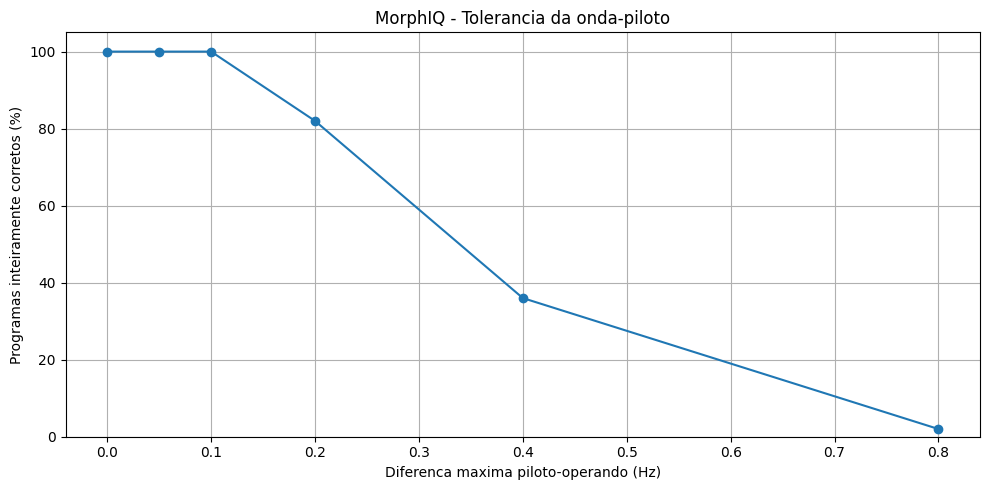

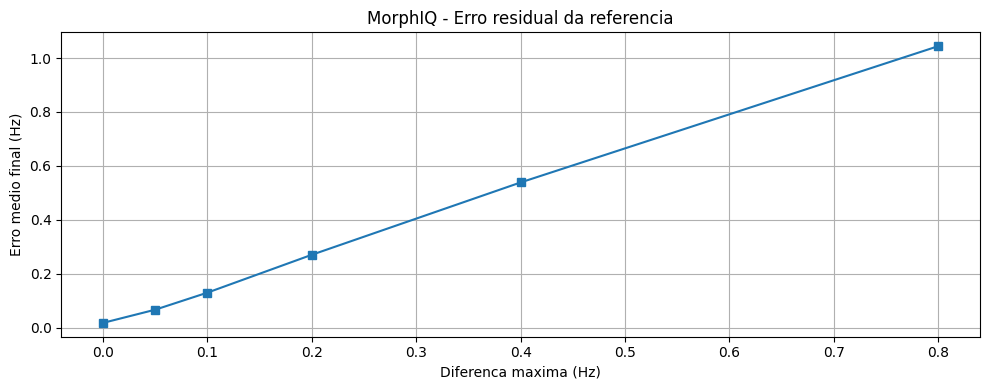


MORPHIQ - EXPERIMENTO 37
Programas testados: 600
Instrucoes executadas: 4800


In [ ]:


# MORPHIQ - EXPERIMENTO 37
# IMPERFEICOES DA ONDA-PILOTO

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2037)

fs = 1000
N = 2000
t = np.arange(N) / fs
atraso = 10

programas = 100
passos = 8
desvio_operando = 1.0
diferencas = [0, 0.05, 0.1, 0.2, 0.4, 0.8]

def onda(f):
    return np.exp(1j*2*np.pi*f*t)

def medir(s):
    p = s[atraso:]*np.conj(s[:-atraso])
    return np.angle(np.sum(p))*fs/(2*np.pi*atraso)

def ruido(nivel):
    return nivel*(rng.normal(size=N)
                  + 1j*rng.normal(size=N))

taxas = []
erros = []

for diferenca in diferencas:

    programas_ok = 0
    erros_finais = []

    for _ in range(programas):

        inicial = int(rng.integers(-5, 6))
        estado = onda(inicial)
        esperado = inicial
        correto = True

        for _ in range(passos):

            op = rng.choice(["ADD", "SUB"])
            valor = int(rng.integers(1, 6))

            delta = rng.uniform(
                -desvio_operando,
                desvio_operando
            )

            # Erro independente entre piloto
            # e operando
            erro_piloto = rng.uniform(
                -diferenca, diferenca
            )

            operando = onda(valor + delta)

            piloto = onda(
                20 + delta + erro_piloto
            ) + ruido(0.05)

            delta_estimado = medir(piloto)-20

            operando_corrigido = operando*np.exp(
                -1j*2*np.pi*delta_estimado*t
            )

            if op == "ADD":
                estado *= operando_corrigido
                esperado += valor
            else:
                estado *= np.conj(
                    operando_corrigido
                )
                esperado -= valor

            estado += ruido(0.02)

            medido = medir(
                estado + ruido(0.2)
            )

            if int(np.rint(medido)) != esperado:
                correto = False

        programas_ok += int(correto)
        erros_finais.append(
            abs(medido-esperado)
        )

    taxa = 100*programas_ok/programas
    erro_medio = np.mean(erros_finais)

    taxas.append(taxa)
    erros.append(erro_medio)

    print(
        f"Diferenca +/-{diferenca:.2f} Hz | "
        f"Programas: {taxa:.1f}% | "
        f"Erro final: {erro_medio:.4f} Hz"
    )

plt.figure(figsize=(10, 5))
plt.plot(diferencas, taxas, marker="o")
plt.xlabel("Diferenca maxima piloto-operando (Hz)")
plt.ylabel("Programas inteiramente corretos (%)")
plt.title("MorphIQ - Tolerancia da onda-piloto")
plt.ylim(0, 105)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(diferencas, erros, marker="s")
plt.xlabel("Diferenca maxima (Hz)")
plt.ylabel("Erro medio final (Hz)")
plt.title("MorphIQ - Erro residual da referencia")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 37")
print("Programas testados:",
      programas*len(diferencas))
print("Instrucoes executadas:",
      programas*passos*len(diferencas))


Desvio +/-0.00 Hz
livre         | Acertos: 100.0% | Erro medio: 0.0000 Hz
imperfeita    | Acertos: 100.0% | Erro medio: 0.0030 Hz
independente  | Acertos: 100.0% | Erro medio: 0.0218 Hz

Desvio +/-0.10 Hz
livre         | Acertos: 100.0% | Erro medio: 0.1123 Hz
imperfeita    | Acertos: 100.0% | Erro medio: 0.1415 Hz
independente  | Acertos: 100.0% | Erro medio: 0.1386 Hz

Desvio +/-0.30 Hz
livre         | Acertos:  65.0% | Erro medio: 0.4027 Hz
imperfeita    | Acertos:  76.0% | Erro medio: 0.3547 Hz
independente  | Acertos:  63.0% | Erro medio: 0.4072 Hz

Desvio +/-0.60 Hz
livre         | Acertos:  39.0% | Erro medio: 0.7992 Hz
imperfeita    | Acertos:  30.0% | Erro medio: 0.8458 Hz
independente  | Acertos:  36.0% | Erro medio: 0.8051 Hz

Desvio +/-1.00 Hz
livre         | Acertos:  27.0% | Erro medio: 1.2221 Hz
imperfeita    | Acertos:  16.0% | Erro medio: 1.5560 Hz
independente  | Acertos:  26.0% | Erro medio: 1.2130 Hz


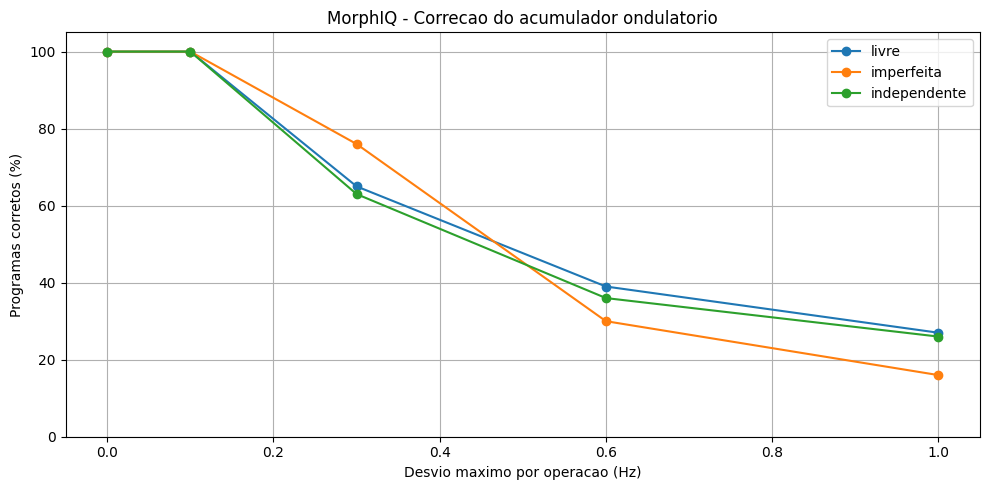

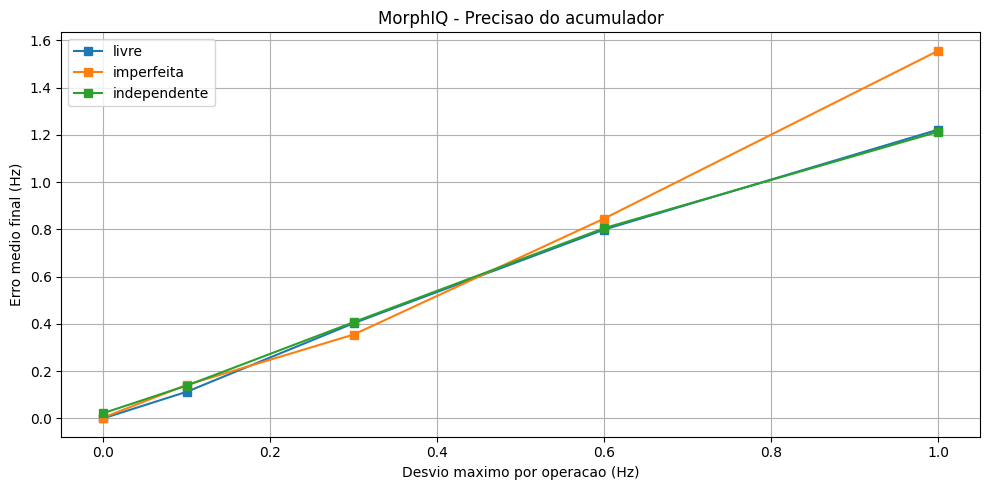


MORPHIQ - EXPERIMENTO 38
Programas por configuracao: 100
Instrucoes por programa: 8
Total de execucoes: 1500
Total de instrucoes: 12000
Intervalo de correcao: 2


In [ ]:


# ==============================================
# MORPHIQ - EXPERIMENTO 38
# CORRECAO DO ACUMULADOR ONDULATORIO
# COM REFERENCIA INDEPENDENTE
# ==============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2038)

# Configuracao do sistema
fs = 1000
N = 1000
t = np.arange(N) / fs

programas = 100
passos = 8

desvios = [0.0, 0.1, 0.3, 0.6, 1.0]

# Referencia independente
erro_referencia = 0.02

# Frequencia de verificacao
intervalo_correcao = 2

# Ondas usadas para representar valores
def onda(freq, ruido=0.0):
    sinal = np.cos(2*np.pi*freq*t)

    if ruido > 0:
        sinal += rng.normal(0, ruido, N)

    return sinal

# Estimador de frequencia por correlacao
# com seno e cosseno
def estimar_freq(sinal, minimo=0, maximo=60):

    frequencias = np.arange(
        minimo, maximo + 0.001, 0.05
    )

    # Estimacao independente do resultado esperado
    espectro = np.abs(
        np.fft.rfft(sinal, n=20000)
    )

    eixos = np.fft.rfftfreq(
        20000, 1/fs
    )

    indices = np.where(
        (eixos >= minimo) &
        (eixos <= maximo)
    )[0]

    indice = indices[
        np.argmax(espectro[indices])
    ]

    return eixos[indice]

# Geracao de programas
def gerar_programa():

    inicio = int(rng.integers(10, 21))
    comandos = []
    estado = inicio

    for _ in range(passos):

        op = rng.choice(["ADD", "SUB"])
        valor = int(rng.integers(1, 5))

        # Mantem frequencias positivas
        if estado - valor < 5:
            op = "ADD"

        if estado + valor > 45:
            op = "SUB"

        estado += valor if op == "ADD" else -valor

        comandos.append((op, valor))

    return inicio, comandos, estado

# Execucao simulada do acumulador
def executar(inicio, comandos, desvio, modo):

    # Frequencia fisica representando o estado
    acumulador = float(inicio)

    # A referencia tem erro proprio, independente
    erro_ref = rng.normal(
        0, erro_referencia
    )

    historico = [acumulador]

    for i, (op, valor) in enumerate(comandos):

        # Desvio independente por operacao
        erro_operando = rng.uniform(
            -desvio, desvio
        )

        # Valor representado por frequencia
        freq_operando = valor + erro_operando

        if op == "ADD":
            acumulador += freq_operando
        else:
            acumulador -= freq_operando

        # Correcao por referencia periodica
        if (i + 1) % intervalo_correcao == 0:

            if modo == "imperfeita":
                # Referencia compartilha parte
                # do erro do sistema
                erro_local = rng.uniform(
                    -desvio, desvio
                )

                sinal = onda(
                    acumulador + erro_local,
                    ruido=0.02
                )

                medida = estimar_freq(sinal)

                # Realimentacao parcial
                acumulador += 0.5 * (
                    medida - acumulador
                )

            elif modo == "independente":
                # Referencia independente mede
                # o estado, mas nao conhece
                # o resultado esperado
                sinal = onda(
                    acumulador + erro_ref,
                    ruido=0.02
                )

                medida = estimar_freq(sinal)

                # Realimentacao parcial
                acumulador += 0.5 * (
                    medida - acumulador
                )

        historico.append(acumulador)

    return acumulador, historico

# ==============================================
# SIMULACOES
# ==============================================

modos = [
    "livre",
    "imperfeita",
    "independente"
]

taxas = {m: [] for m in modos}
erros = {m: [] for m in modos}

for desvio in desvios:

    acertos = {m: 0 for m in modos}
    erros_locais = {m: [] for m in modos}

    for _ in range(programas):

        inicio, comandos, esperado = gerar_programa()

        for modo in modos:

            final, historico = executar(
                inicio,
                comandos,
                desvio,
                modo
            )

            erro = abs(final - esperado)

            erros_locais[modo].append(erro)

            # Resultado aceito dentro
            # de uma tolerancia de 0.5 Hz
            if erro < 0.5:
                acertos[modo] += 1

    print(f"\nDesvio +/-{desvio:.2f} Hz")

    for modo in modos:

        taxa = 100 * acertos[modo] / programas
        erro_medio = np.mean(erros_locais[modo])

        taxas[modo].append(taxa)
        erros[modo].append(erro_medio)

        print(
            f"{modo:13s} | "
            f"Acertos: {taxa:5.1f}% | "
            f"Erro medio: {erro_medio:.4f} Hz"
        )

# ==============================================
# GRAFICO 1 - PROGRAMAS CORRETOS
# ==============================================

plt.figure(figsize=(10, 5))

for modo in modos:
    plt.plot(
        desvios,
        taxas[modo],
        marker="o",
        label=modo
    )

plt.xlabel("Desvio maximo por operacao (Hz)")
plt.ylabel("Programas corretos (%)")
plt.title(
    "MorphIQ - Correcao do acumulador ondulatorio"
)
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ==============================================
# GRAFICO 2 - ERRO FINAL
# ==============================================

plt.figure(figsize=(10, 5))

for modo in modos:
    plt.plot(
        desvios,
        erros[modo],
        marker="s",
        label=modo
    )

plt.xlabel("Desvio maximo por operacao (Hz)")
plt.ylabel("Erro medio final (Hz)")
plt.title(
    "MorphIQ - Precisao do acumulador"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 38")
print("Programas por configuracao:", programas)
print("Instrucoes por programa:", passos)
print("Total de execucoes:",
      programas * len(desvios) * len(modos))
print("Total de instrucoes:",
      programas * len(desvios) * len(modos) * passos)
print("Intervalo de correcao:",
      intervalo_correcao)


DESVIO +/-0.00 Hz
Livre                 | Acertos: 100.0% | Erro medio: 0.0043 Hz
Piloto compartilhado  | Acertos: 100.0% | Erro medio: 0.0059 Hz
Piloto imperfeito     | Acertos: 100.0% | Erro medio: 0.0066 Hz

DESVIO +/-0.10 Hz
Livre                 | Acertos: 100.0% | Erro medio: 0.1325 Hz
Piloto compartilhado  | Acertos: 100.0% | Erro medio: 0.0062 Hz
Piloto imperfeito     | Acertos: 100.0% | Erro medio: 0.0357 Hz

DESVIO +/-0.30 Hz
Livre                 | Acertos:  75.0% | Erro medio: 0.3769 Hz
Piloto compartilhado  | Acertos: 100.0% | Erro medio: 0.0062 Hz
Piloto imperfeito     | Acertos: 100.0% | Erro medio: 0.0988 Hz

DESVIO +/-0.60 Hz
Livre                 | Acertos:  41.0% | Erro medio: 0.7968 Hz
Piloto compartilhado  | Acertos: 100.0% | Erro medio: 0.0061 Hz
Piloto imperfeito     | Acertos:  94.0% | Erro medio: 0.1865 Hz

DESVIO +/-1.00 Hz
Livre                 | Acertos:  19.0% | Erro medio: 1.3324 Hz
Piloto compartilhado  | Acertos: 100.0% | Erro medio: 0.0060 Hz
Piloto im

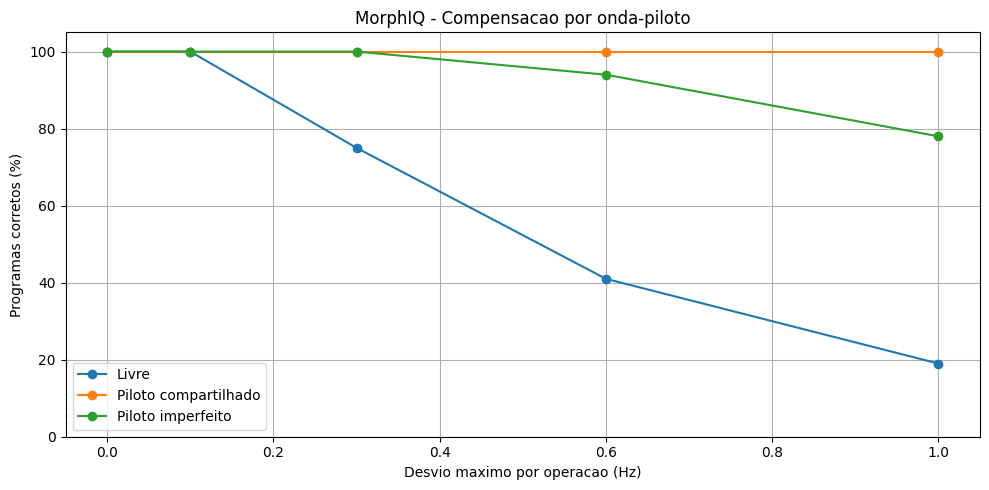

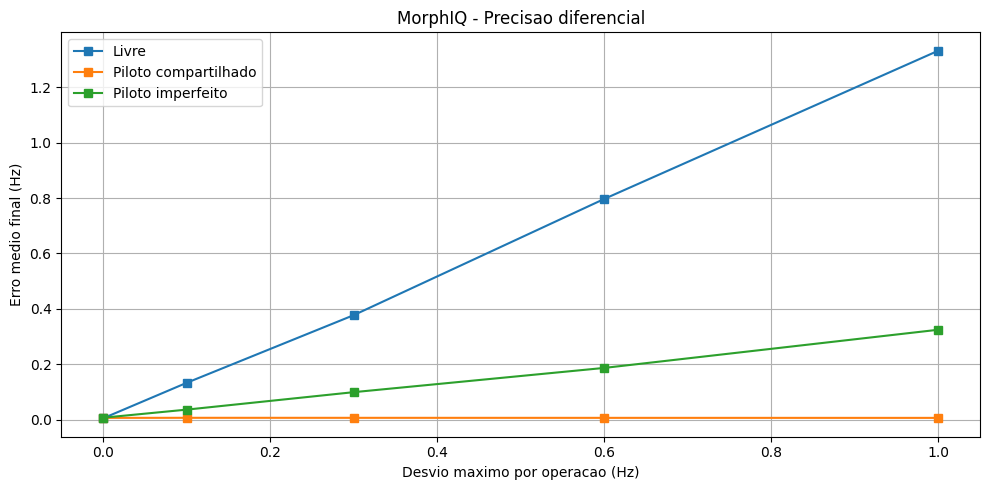


MORPHIQ - EXPERIMENTO 39
Programas por configuracao: 100
Instrucoes por programa: 8
Total de execucoes: 1500
Total de instrucoes: 12000
Piloto nominal: 70.0 Hz
Ruido aplicado: 0.05


In [ ]:


# ==============================================
# MORPHIQ - EXPERIMENTO 39
# COMPENSACAO DIFERENCIAL POR ONDA-PILOTO
# ==============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2039)

fs = 1000
N = 1000
t = np.arange(N) / fs

programas = 100
passos = 8
desvios = [0.0, 0.1, 0.3, 0.6, 1.0]

F_PILOTO = 70.0
RUIDO = 0.05

modos = [
    "Livre",
    "Piloto compartilhado",
    "Piloto imperfeito"
]

# Frequencia estimada por FFT com interpolacao
def medir_frequencia(sinal, fmin, fmax):
    nfft = 20000
    janela = np.hanning(len(sinal))
    espectro = np.abs(
        np.fft.rfft(sinal * janela, n=nfft)
    )
    frequencias = np.fft.rfftfreq(nfft, 1/fs)

    faixa = np.where(
        (frequencias >= fmin) &
        (frequencias <= fmax)
    )[0]

    indice = faixa[np.argmax(espectro[faixa])]

    # Interpolacao parabolica do pico
    if 0 < indice < len(espectro) - 1:
        a = espectro[indice - 1]
        b = espectro[indice]
        c = espectro[indice + 1]
        denominador = a - 2*b + c

        if abs(denominador) > 1e-12:
            deslocamento = 0.5 * (a-c)/denominador
            return frequencias[indice] + (
                deslocamento * fs/nfft
            )

    return frequencias[indice]

# Programa de instrucoes
def gerar_programa():
    inicio = int(rng.integers(12, 25))
    estado = inicio
    comandos = []

    for _ in range(passos):
        valor = int(rng.integers(1, 5))
        op = rng.choice(["ADD", "SUB"])

        if estado - valor < 5:
            op = "ADD"

        if estado + valor > 45:
            op = "SUB"

        estado += valor if op == "ADD" else -valor
        comandos.append((op, valor))

    return inicio, comandos, estado

# Geracao de sinais simultaneos
def gerar_sinais(valor, desvio, diferenca_piloto):

    # Desvio principal de cada operacao
    erro = rng.uniform(-desvio, desvio)

    # Operando e piloto em canais distintos
    f_operando = 10.0 + valor + erro
    f_piloto = F_PILOTO + erro + diferenca_piloto

    fase_op = rng.uniform(0, 2*np.pi)
    fase_pil = rng.uniform(0, 2*np.pi)

    operando = np.cos(
        2*np.pi*f_operando*t + fase_op
    ) + rng.normal(0, RUIDO, N)

    piloto = np.cos(
        2*np.pi*f_piloto*t + fase_pil
    ) + rng.normal(0, RUIDO, N)

    return operando, piloto

# Executa um programa
def executar(inicio, comandos, desvio, modo):

    acumulador = float(inicio)
    historico = [acumulador]

    for op, valor in comandos:

        diferenca = 0.0

        if modo == "Piloto imperfeito":
            # Piloto possui erro adicional
            diferenca = rng.uniform(
                -0.25*desvio,
                0.25*desvio
            )

        sinal_op, sinal_pil = gerar_sinais(
            valor, desvio, diferenca
        )

        freq_op = medir_frequencia(
            sinal_op, 9, 16
        )

        # Valor codificado na faixa 11-14 Hz
        valor_medido = freq_op - 10.0

        if modo != "Livre":

            freq_pil = medir_frequencia(
                sinal_pil, 68, 72
            )

            desvio_estimado = (
                freq_pil - F_PILOTO
            )

            valor_medido -= desvio_estimado

        if op == "ADD":
            acumulador += valor_medido
        else:
            acumulador -= valor_medido

        historico.append(acumulador)

    return acumulador, historico

# ==============================================
# TESTES
# ==============================================

taxas = {m: [] for m in modos}
erros = {m: [] for m in modos}

for desvio in desvios:

    acertos = {m: 0 for m in modos}
    erros_locais = {m: [] for m in modos}

    # Mesmos programas para todos os modos
    conjunto = [
        gerar_programa()
        for _ in range(programas)
    ]

    for inicio, comandos, esperado in conjunto:

        for modo in modos:

            resultado, historico = executar(
                inicio, comandos, desvio, modo
            )

            erro_final = abs(resultado - esperado)
            erros_locais[modo].append(erro_final)

            if erro_final < 0.5:
                acertos[modo] += 1

    print(f"\nDESVIO +/-{desvio:.2f} Hz")

    for modo in modos:
        taxa = 100 * acertos[modo]/programas
        erro_medio = np.mean(erros_locais[modo])

        taxas[modo].append(taxa)
        erros[modo].append(erro_medio)

        print(
            f"{modo:21s} | "
            f"Acertos: {taxa:5.1f}% | "
            f"Erro medio: {erro_medio:.4f} Hz"
        )

# ==============================================
# GRAFICO 1 - ACERTOS
# ==============================================

plt.figure(figsize=(10, 5))

for modo in modos:
    plt.plot(
        desvios,
        taxas[modo],
        marker="o",
        label=modo
    )

plt.title("MorphIQ - Compensacao por onda-piloto")
plt.xlabel("Desvio maximo por operacao (Hz)")
plt.ylabel("Programas corretos (%)")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ==============================================
# GRAFICO 2 - ERRO FINAL
# ==============================================

plt.figure(figsize=(10, 5))

for modo in modos:
    plt.plot(
        desvios,
        erros[modo],
        marker="s",
        label=modo
    )

plt.title("MorphIQ - Precisao diferencial")
plt.xlabel("Desvio maximo por operacao (Hz)")
plt.ylabel("Erro medio final (Hz)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nMORPHIQ - EXPERIMENTO 39")
print("Programas por configuracao:", programas)
print("Instrucoes por programa:", passos)
print("Total de execucoes:",
      programas * len(desvios) * len(modos))
print("Total de instrucoes:",
      programas * len(desvios) * len(modos) * passos)
print("Piloto nominal:", F_PILOTO, "Hz")
print("Ruido aplicado:", RUIDO)


Ruido: 0.00 | Desvio: +/-0.00 Hz
ADD: 100.0% | Erro medio: 0.0000 Hz
SUB: 100.0% | Erro medio: 0.0000 Hz

Ruido: 0.00 | Desvio: +/-0.10 Hz
ADD: 100.0% | Erro medio: 0.0698 Hz
SUB: 100.0% | Erro medio: 0.0697 Hz

Ruido: 0.00 | Desvio: +/-0.25 Hz
ADD: 100.0% | Erro medio: 0.1696 Hz
SUB: 100.0% | Erro medio: 0.1618 Hz

Ruido: 0.00 | Desvio: +/-0.50 Hz
ADD: 74.0% | Erro medio: 0.3440 Hz
SUB: 74.5% | Erro medio: 0.3478 Hz

Ruido: 0.05 | Desvio: +/-0.00 Hz
ADD: 100.0% | Erro medio: 0.0011 Hz
SUB: 100.0% | Erro medio: 0.0010 Hz

Ruido: 0.05 | Desvio: +/-0.10 Hz
ADD: 100.0% | Erro medio: 0.0625 Hz
SUB: 100.0% | Erro medio: 0.0710 Hz

Ruido: 0.05 | Desvio: +/-0.25 Hz
ADD: 100.0% | Erro medio: 0.1764 Hz
SUB: 100.0% | Erro medio: 0.1719 Hz

Ruido: 0.05 | Desvio: +/-0.50 Hz
ADD: 74.0% | Erro medio: 0.3445 Hz
SUB: 74.5% | Erro medio: 0.3439 Hz

Ruido: 0.15 | Desvio: +/-0.00 Hz
ADD: 100.0% | Erro medio: 0.0035 Hz
SUB: 100.0% | Erro medio: 0.0034 Hz

Ruido: 0.15 | Desvio: +/-0.10 Hz
ADD: 100.0% | Er

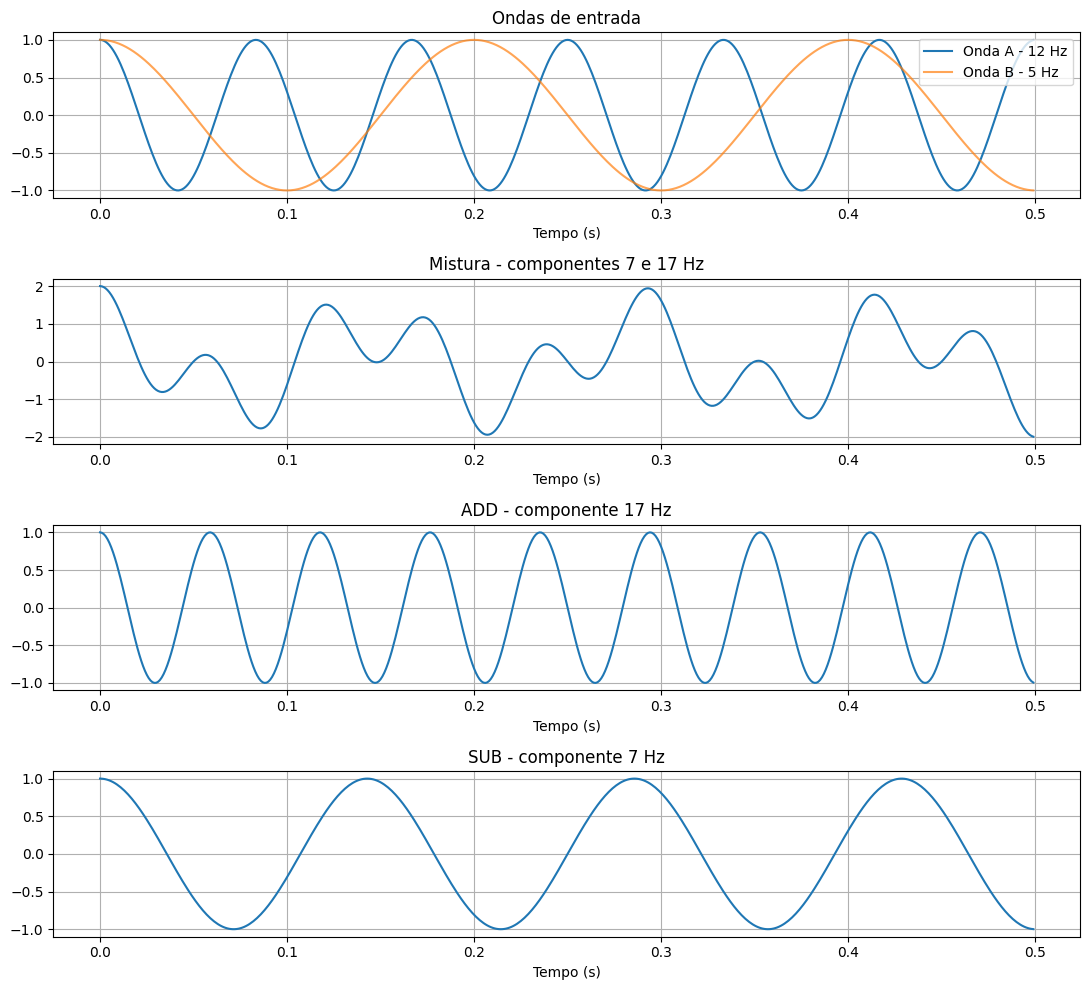

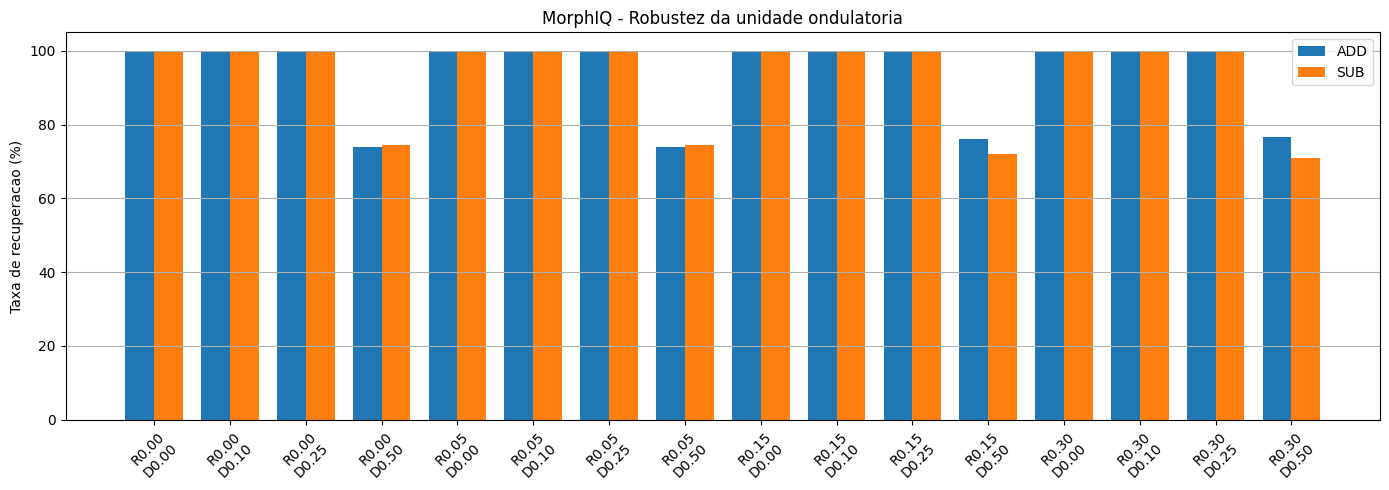


MORPHIQ - EXPERIMENTO 40
Cenarios: 16
Testes por operacao e cenario: 200
Total de operacoes: 6400
Taxa media ADD: 93.78 %
Taxa media SUB: 93.25 %
Erro medio ADD: 0.1459 Hz
Erro medio SUB: 0.1464 Hz


In [ ]:


# ==============================================
# MORPHIQ - EXPERIMENTO 40
# UNIDADE ARITMETICA POR MISTURA DE ONDAS
# ADD / SUB NO DOMINIO DOS SINAIS
# ==============================================

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2040)

fs = 1000
N = 2000
t = np.arange(N) / fs

testes = 200
ruidos = [0.0, 0.05, 0.15, 0.30]
desvios = [0.0, 0.10, 0.25, 0.50]

# Frequencias positivas, A > B
def gerar_entradas(a, b, desvio, ruido):
    ea = rng.uniform(-desvio, desvio)
    eb = rng.uniform(-desvio, desvio)

    fase_a = rng.uniform(0, 2*np.pi)
    fase_b = rng.uniform(0, 2*np.pi)

    onda_a = np.cos(
        2*np.pi*(a+ea)*t + fase_a
    )

    onda_b = np.cos(
        2*np.pi*(b+eb)*t + fase_b
    )

    onda_a += rng.normal(0, ruido, N)
    onda_b += rng.normal(0, ruido, N)

    return onda_a, onda_b

# Mistura fisicamente modelavel:
# multiplicacao de duas ondas
def misturador(onda_a, onda_b):
    return 2.0 * onda_a * onda_b

# Filtro digital usado como aproximacao
# de um filtro passa-faixa
def filtrar_componente(sinal, alvo, largura=2.0):
    espectro = np.fft.rfft(sinal)
    freqs = np.fft.rfftfreq(N, 1/fs)

    mascara = (
        np.abs(freqs - alvo) <= largura
    )

    espectro_filtrado = np.zeros_like(
        espectro
    )
    espectro_filtrado[mascara] = (
        espectro[mascara]
    )

    return np.fft.irfft(
        espectro_filtrado, n=N
    )

# Estimacao da frequencia da onda filtrada
def medir_frequencia(sinal, alvo):
    nfft = 40000
    janela = np.hanning(N)

    espectro = np.abs(
        np.fft.rfft(sinal*janela, n=nfft)
    )

    freqs = np.fft.rfftfreq(nfft, 1/fs)

    faixa = np.where(
        (freqs >= max(0.1, alvo-2.0)) &
        (freqs <= alvo+2.0)
    )[0]

    indice = faixa[
        np.argmax(espectro[faixa])
    ]

    # Interpolacao parabolica
    if 0 < indice < len(espectro)-1:
        x = espectro[indice-1]
        y = espectro[indice]
        z = espectro[indice+1]

        denominador = x-2*y+z

        if abs(denominador) > 1e-12:
            ajuste = 0.5*(x-z)/denominador
            return freqs[indice] + (
                ajuste*fs/nfft
            )

    return freqs[indice]

# Operacao ondulatoria
def executar_onda(a, b, op, desvio, ruido):

    sinal_a, sinal_b = gerar_entradas(
        a, b, desvio, ruido
    )

    mistura = misturador(
        sinal_a, sinal_b
    )

    # Frequencia nominal usada apenas
    # para configurar o filtro de saida
    if op == "ADD":
        alvo = a+b
    else:
        alvo = a-b

    saida = filtrar_componente(
        mistura, alvo
    )

    medido = medir_frequencia(
        saida, alvo
    )

    return medido, sinal_a, sinal_b, mistura, saida

# ==============================================
# TESTES AUTOMATICOS
# ==============================================

resultados = {
    "ADD": [],
    "SUB": []
}

erros_medios = {
    "ADD": [],
    "SUB": []
}

cenarios = []

for ruido in ruidos:
    for desvio in desvios:

        cenarios.append(
            (ruido, desvio)
        )

        print(
            f"\nRuido: {ruido:.2f} | "
            f"Desvio: +/-{desvio:.2f} Hz"
        )

        for op in ["ADD", "SUB"]:

            acertos = 0
            erros = []

            for _ in range(testes):

                # Evita componentes de soma
                # e diferenca muito proximas
                a = int(rng.integers(15, 36))
                b = int(rng.integers(3, 11))

                esperado = (
                    a+b if op == "ADD" else a-b
                )

                medido, *_ = executar_onda(
                    a, b, op, desvio, ruido
                )

                erro = abs(medido-esperado)
                erros.append(erro)

                if erro < 0.5:
                    acertos += 1

            taxa = 100*acertos/testes

            resultados[op].append(taxa)
            erros_medios[op].append(
                np.mean(erros)
            )

            print(
                f"{op}: {taxa:.1f}% | "
                f"Erro medio: {np.mean(erros):.4f} Hz"
            )

# ==============================================
# EXEMPLO VISUAL: 12 + 5 E 12 - 5
# ==============================================

a = 12
b = 5

onda_a = np.cos(2*np.pi*a*t)
onda_b = np.cos(2*np.pi*b*t)

mistura = misturador(
    onda_a, onda_b
)

soma = filtrar_componente(
    mistura, a+b
)

subtracao = filtrar_componente(
    mistura, a-b
)

fig, axes = plt.subplots(
    4, 1, figsize=(11, 10)
)

limite = int(0.5*fs)

axes[0].plot(
    t[:limite],
    onda_a[:limite],
    label="Onda A - 12 Hz"
)

axes[0].plot(
    t[:limite],
    onda_b[:limite],
    label="Onda B - 5 Hz",
    alpha=0.7
)

axes[0].set_title("Ondas de entrada")
axes[0].legend()

axes[1].plot(
    t[:limite],
    mistura[:limite]
)
axes[1].set_title(
    "Mistura - componentes 7 e 17 Hz"
)

axes[2].plot(
    t[:limite],
    soma[:limite]
)
axes[2].set_title(
    "ADD - componente 17 Hz"
)

axes[3].plot(
    t[:limite],
    subtracao[:limite]
)
axes[3].set_title(
    "SUB - componente 7 Hz"
)

for ax in axes:
    ax.grid(True)
    ax.set_xlabel("Tempo (s)")

plt.tight_layout()
plt.show()

# ==============================================
# GRAFICO DE ROBUSTEZ
# ==============================================

labels = [
    f"R{r:.2f}\nD{d:.2f}"
    for r, d in cenarios
]

x = np.arange(len(labels))
largura = 0.38

plt.figure(figsize=(14, 5))

plt.bar(
    x-largura/2,
    resultados["ADD"],
    largura,
    label="ADD"
)

plt.bar(
    x+largura/2,
    resultados["SUB"],
    largura,
    label="SUB"
)

plt.xticks(x, labels, rotation=45)
plt.ylabel("Taxa de recuperacao (%)")
plt.title(
    "MorphIQ - Robustez da unidade ondulatoria"
)
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ==============================================
# RESUMO
# ==============================================

print("\nMORPHIQ - EXPERIMENTO 40")
print("Cenarios:", len(cenarios))
print("Testes por operacao e cenario:", testes)
print("Total de operacoes:",
      len(cenarios)*testes*2)

print(
    "Taxa media ADD:",
    round(np.mean(resultados["ADD"]), 2), "%"
)

print(
    "Taxa media SUB:",
    round(np.mean(resultados["SUB"]), 2), "%"
)

print(
    "Erro medio ADD:",
    round(np.mean(erros_medios["ADD"]), 4),
    "Hz"
)

print(
    "Erro medio SUB:",
    round(np.mean(erros_medios["SUB"]), 4),
    "Hz"
)